# Data Mining Project — Information Operations (A.Y. 2026/2027)

This notebook contains the complete analysis of the project:

* **Task 1 – Data Understanding and Preparation**: data semantics, data quality (including an investigation of
  the timestamps), distributions, correlations and the construction of a **user (account) profile** with
  engineered features;
* **Task 2 – Clustering Analysis**: K-means, DBSCAN, hierarchical clustering, a final comparison and, as optional
  technique, **Gaussian Mixture Models fitted with the EM algorithm**.

**Course-material rule.** Every technique, algorithm, metric and visualisation used here appears in the course
slides (folder `material/`). At the beginning of every section a Markdown cell lists the techniques used and the
slide deck / page where they are introduced. The slide decks are cited with these short names:

| Short name | File in `material/` |
|---|---|
| **[DU]** Data Understanding | `2-data_understanding-2026.pdf` |
| **[DP]** Data Preparation & Cleaning | `3-data_preparation-2026.pdf` |
| **[SIM]** Data Similarity | `6-data_similarity.pdf` |
| **[CL-INTRO]** Cluster analysis – introduction | `6-basic_cluster_analysis-intro.pdf` |
| **[KM]** K-means | `6-basic_cluster_analysis-kmeans.pdf` |
| **[KM-VAR]** K-means variants (bisecting, X-means, mixture models / EM) | `6-basic_cluster_analysis-kmeans-variants.pdf` |
| **[HIER]** Hierarchical clustering | `7.basic_cluster_analysis-hierarchical.pdf` |
| **[DBSCAN]** DBSCAN | `8.basic_cluster_analysis-dbscan.pdf` |
| **[VAL]** Cluster validity | `8.basic_cluster_analysis-validity.pdf` |

The slides do not prescribe software libraries; the notebook uses the standard Python data-analysis stack
(`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn`) only as implementations of the techniques of
the slides, plus `pyarrow` to store intermediate tables in Parquet format.

**Identifiers.** All identifiers (`postid`, `accountid`, `in_reply_to_postid`, `in_reply_to_accountid`,
`reposted_postid`, `reposted_accountid`) were anonymised with a hash computed **per country**: they are unique
only inside the same `ioCountry`. The notebook therefore always uses the **composite key (ioCountry, id)** –
for duplicates, labels, joins and user profiles.

**Professors' Q&A.** The answers of the Q&A document (`material/Q&A.pdf`) are applied throughout the notebook and
cited as **[Q&A Qn]**:

| Q&A | Guideline | Where / how it is applied |
|---|---|---|
| Q2 | missing-value plots can be useful | 1.2.1 – bar chart of missing values by class |
| Q3, Q14 | `post_time` is in UTC; use UTC for all countries | 1.2.6 and every hour-of-day analysis (no local time zones are inferred) |
| Q4, Q5, Q16 | ids hashed per country; same `postid` with different account / text inside a country is a data problem: look for patterns, otherwise declare the pipeline; no hash collisions across countries | 1.2.3 – composite keys, analysis of the duplicated keys, declared rule |
| Q6, Q11 | choose the features; normalisation is part of the evaluation; same features first, then possibly a better subset per algorithm | 2.1 (selection, z-score justification), 2.3 (DBSCAN with several feature sets) |
| Q7, Q13 | clustering all users and/or groups separately; stratified sampling by ioCountry and is_control if needed | 2.2.4 (K-means per operation), 2.3–2.4 (stratified samples) |
| Q8 | metrics are not enough: interpret and characterise every cluster | 2.2–2.6 (profile tables, parallel coordinates, interpretation of every cluster) |
| Q9 | in general one row per user; user–country granularity is allowed (mind the size) | 1.2.3, 1.5 (profiles keyed by (ioCountry, accountid)) |
| Q10 | quality of the features matters more than their number | 1.5 (each feature with a meaning and a formula; redundancies removed) |
| Q12 | DBSCAN: try parameters **and** feature sets before concluding whether it works | 2.3 |
| Q13 | hierarchical: try the whole profile set first, sample only if needed | 2.4 |
| Q15 | shared profile descriptions: an interesting pattern to analyse | 1.5.4 and feature `shared_desc` |
| Q17 | `in_reply_to_postid` without `in_reply_to_accountid` (and vice versa) are both data problems | 1.2.4 |

**IO vs control.** Information-operation accounts (**IO**, `is_control == False`) are always compared with
**control** accounts (`is_control == True`). Long-tailed variables (followers, following, number of posts, ...)
are analysed on a logarithmic scale.

**How to run.** Put `data.csv.zip` in the project folder (or the extracted `data.csv` in `data/`) and run all the
cells. The raw CSV (~5 GB, 8.7 M posts) is read in chunks and converted into a compact Parquet table that is used
by the following cells.

## 0. Setup

In [1]:
# --- Standard library ---
import gc
import time
import warnings
import zipfile
from pathlib import Path

# --- Scientific stack ---
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

# One consistent colour per class in every comparison
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
CLASS_ORDER = ['IO', 'Control']
CLASS_PALETTE = {'IO': '#d62728', 'Control': '#1f77b4'}

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# --- Paths ---
PROJECT_DIR = Path('.').resolve()
DATA_DIR = PROJECT_DIR / 'data'
DATA_DIR.mkdir(exist_ok=True)
RAW_ZIP = PROJECT_DIR / 'data.csv.zip'
RAW_CSV = DATA_DIR / 'data.csv'
POSTS_PQ = DATA_DIR / 'posts_compact.parquet'      # compact post-level table built from the raw CSV
CLEAN_PQ = DATA_DIR / 'posts_clean.parquet'        # cleaned post-level table
PROFILES_PQ = DATA_DIR / 'user_profiles.parquet'   # account-level profiles (output of Task 1, input of Task 2)

print('pandas', pd.__version__, '| numpy', np.__version__)


def sturges_bins(n: int) -> int:
    """Number of histogram bins according to Sturges' rule, k = 1 + log2(n)  [DU p. 30]."""
    return int(np.ceil(1 + np.log2(n)))


def entropy_bits(counts) -> float:
    """Shannon entropy H = -sum p log2 p of a vector of counts  [SIM pp. 20-22]."""
    p = np.asarray(counts, dtype=float)
    p = p[p > 0] / p.sum()
    return float(-(p * np.log2(p)).sum() + 0.0)


def mutual_information_bits(x, y) -> float:
    """Mutual information I(X,Y) = H(X) + H(Y) - H(X,Y) in bits  [SIM pp. 23-24]."""
    ct = pd.crosstab(pd.Series(np.asarray(x)), pd.Series(np.asarray(y))).to_numpy()
    return entropy_bits(ct.sum(1)) + entropy_bits(ct.sum(0)) - entropy_bits(ct.ravel())

pandas 3.1.1 | numpy 2.5.5


In [2]:
# Extract the raw CSV from the ZIP archive if it is not already available.
if not RAW_CSV.exists():
    if not RAW_ZIP.exists():
        raise FileNotFoundError('Put data.csv.zip in the project folder (or data.csv in ./data).')
    with zipfile.ZipFile(RAW_ZIP) as zf:
        zf.extract('data.csv', DATA_DIR)  # the __MACOSX entry of the archive is skipped
print(f'Raw CSV: {RAW_CSV}  ({RAW_CSV.stat().st_size / 1e9:.2f} GB)')

Raw CSV: C:\Users\Diogo\Desktop\Data mining project\data\data.csv  (5.03 GB)


### 0.1 From the raw CSV to a compact Parquet table

The raw file (5 GB, 8.7 million posts) does not fit comfortably in memory together with its texts, and most of its
bytes are long strings (texts, biographies, 42-character anonymised identifiers). It is therefore read in chunks of
500k rows **as plain strings** (no type inference, so that no information is lost before the quality assessment),
and every chunk is reduced to the numbers the analysis needs:

| Raw field(s) | Stored as | What is computed | Why |
|---|---|---|---|
| `postid`, `accountid`, `in_reply_to_*`, `reposted_*` | `*_key` (64-bit integer) | hash of the composite key `ioCountry|id` (`0` = missing) | ids are unique only inside an operation; the same string gives the same number in every chunk and column (`accountid` vs `reposted_accountid`), which is all joins and duplicate checks need |
| `post_text` | `text_len`, `n_words` | number of characters and of words of the text **written by the account**: the anonymised mentions (`@` + 42 hex characters) and links (`https://` + 42 hex characters) are removed first | the anonymisation replaced every mention and link with a 42-character hash, much longer than a real user name or short link: in the raw texts these tokens are 39% of all the characters (39% in IO posts, 41% in control posts) and would turn "text length" into a second count of mentions and links |
| `post_text` | `raw_text_len` | length of the text as it is in the file | only used to keep copy detection on texts of at least 20 characters (1.5) |
| `post_text` | `text_h` | hash of the normalised text (lower case, single spaces, trimmed; tokens kept) | two accounts publishing exactly the same message get the same number: copy-paste detection without keeping the texts |
| `account_profile_description` | `desc_len`, `desc_h` | length of the biography; hash of the normalised biography (`0` = no biography) | profile completeness; identical ("template") biographies |
| `hashtags`, `urls`, `account_mentions` | `n_hashtags`, `n_urls`, `n_mentions` | number of elements of the list | the lists are stored as text (`"['a' 'b']"`, without commas, sometimes over two lines), and the elements are anonymised hashes (links, mentions) or free strings: what describes the behaviour is **how many** hashtags, links and mentions a post has |
| `follower_count`, `following_count` | value + status code + offending token | numeric value; status 0 = valid, 1 = missing, 2 = non-numeric token, 3 = negative, 4 = non-integer | invalid values must be found and repaired (1.2), so the reason why a value is invalid is kept |
| `post_time`, `account_creation_date` | timestamps | parsed dates | time analysis (1.2.6) and account age |
| the whole row | `row_h` | hash of all the raw fields | exact duplicate records |

Nominal fields (`ioCountry`, `application_name`, `post_language`, `is_repost`, `is_control`) are kept as they are.
The example after the conversion shows one real post before and after this transformation.

In [3]:
LIST_ITEM_RE = r"'[^']*'|\"[^\"]*\""   # one quoted element of a stringified list
ANON_TOKEN_RE = r'@[0-9a-f]{42}|https?://[0-9a-f]{42}'   # anonymised mention or link inside a text
COUNT_STATUS = {0: 'valid', 1: 'missing', 2: 'non-numeric token', 3: 'negative', 4: 'non-integer'}
ID_COLUMNS = {'postid': 'post_key', 'accountid': 'acc_key', 'in_reply_to_postid': 'reply_post_key',
              'in_reply_to_accountid': 'reply_acc_key', 'reposted_postid': 'rep_post_key',
              'reposted_accountid': 'rep_acc_key'}


def hash_col(s: pd.Series) -> np.ndarray:
    """Deterministic 64-bit hash of a string column (missing values -> 0)."""
    h = pd.util.hash_pandas_object(s.fillna(''), index=False).to_numpy().copy()
    h[s.isna().to_numpy()] = 0
    return h


def composite_key(country: pd.Series, ident: pd.Series) -> np.ndarray:
    """Hash of the composite key 'ioCountry|id' (ids are unique only within the same country)."""
    return hash_col(country + '|' + ident)          # NaN ids stay NaN -> key 0


def content_text(txt: pd.Series) -> pd.Series:
    """Text written by the account: anonymised mentions and links removed, spaces collapsed."""
    return txt.str.replace(ANON_TOKEN_RE, ' ', regex=True).str.replace(r'\s+', ' ', regex=True).str.strip()


def parse_count(raw: pd.Series):
    """Parse a count column; returns (numeric value, status code, offending token)."""
    num = pd.to_numeric(raw, errors='coerce')
    status = np.select([raw.isna(), num.isna(), num < 0, (num % 1) != 0], [1, 2, 3, 4], default=0).astype('int8')
    return num.astype('float64'), status, raw.where(status == 2)


SCHEMA = pa.schema(
    [('row_h', pa.uint64()), ('ioCountry', pa.string()), ('accountid', pa.string())]
    + [(k, pa.uint64()) for k in ID_COLUMNS.values()]
    + [('text_len', pa.float32()), ('n_words', pa.float32()), ('raw_text_len', pa.float32()), ('text_h', pa.uint64()),
       ('application_name', pa.string()), ('post_language', pa.string()),
       ('post_time', pa.timestamp('s')), ('desc_len', pa.float32()), ('desc_h', pa.uint64()),
       ('follower_count', pa.float64()), ('follower_status', pa.int8()), ('follower_bad_token', pa.string()),
       ('following_count', pa.float64()), ('following_status', pa.int8()), ('following_bad_token', pa.string()),
       ('account_creation_date', pa.timestamp('s')), ('is_repost_raw', pa.string()),
       ('n_hashtags', pa.int16()), ('n_urls', pa.int16()), ('n_mentions', pa.int16()),
       ('is_control_raw', pa.string())])


def transform_chunk(ch: pd.DataFrame) -> pd.DataFrame:
    """Turn one raw chunk (all strings) into the compact representation described above."""
    out = pd.DataFrame(index=ch.index)
    out['row_h'] = pd.util.hash_pandas_object(ch, index=False).to_numpy()
    out['ioCountry'] = ch['ioCountry']
    out['accountid'] = ch['accountid']
    for raw_col, key_col in ID_COLUMNS.items():
        out[key_col] = composite_key(ch['ioCountry'], ch[raw_col])
    txt = ch['post_text']
    content = content_text(txt)
    out['text_len'] = content.str.len().astype('float32')
    out['n_words'] = content.str.count(r'\S+').astype('float32')
    out['raw_text_len'] = txt.str.len().astype('float32')
    out['text_h'] = hash_col(txt.str.lower().str.replace(r'\s+', ' ', regex=True).str.strip())
    out['application_name'] = ch['application_name']
    out['post_language'] = ch['post_language']
    out['post_time'] = pd.to_datetime(ch['post_time'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
    out['desc_len'] = ch['account_profile_description'].str.len().astype('float32')
    desc_norm = ch['account_profile_description'].str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
    out['desc_h'] = hash_col(desc_norm.where(desc_norm != ''))      # 0 = no biography
    for col, short in [('follower_count', 'follower'), ('following_count', 'following')]:
        out[col], out[f'{short}_status'], out[f'{short}_bad_token'] = parse_count(ch[col])
    out['account_creation_date'] = pd.to_datetime(ch['account_creation_date'], format='%Y-%m-%d', errors='coerce')
    out['is_repost_raw'] = ch['is_repost']
    out['n_hashtags'] = ch['hashtags'].str.count(LIST_ITEM_RE).fillna(0).astype('int16')
    out['n_urls'] = ch['urls'].str.count(LIST_ITEM_RE).fillna(0).astype('int16')
    out['n_mentions'] = ch['account_mentions'].str.count(LIST_ITEM_RE).fillna(0).astype('int16')
    out['is_control_raw'] = ch['is_control']
    return out


if not POSTS_PQ.exists():
    t0 = time.time()
    writer = pq.ParquetWriter(POSTS_PQ, SCHEMA, compression='zstd')
    reader = pd.read_csv(RAW_CSV, dtype=str, keep_default_na=False, na_values=[''], chunksize=500_000)
    for i, chunk in enumerate(reader):
        writer.write_table(pa.Table.from_pandas(transform_chunk(chunk), preserve_index=False).cast(SCHEMA))
        if i % 4 == 0:
            print(f'chunk {i:2d}: {(i + 1) * 500_000:>10,d} rows read  ({time.time() - t0:5.0f}s)')
    writer.close()
    del reader, chunk
    _ = gc.collect()
print(f'Compact table: {POSTS_PQ.name}  ({POSTS_PQ.stat().st_size / 1e6:.0f} MB, '
      f'{pq.ParquetFile(POSTS_PQ).metadata.num_rows:,} rows)')

Compact table: posts_compact.parquet  (398 MB, 8,714,356 rows)


In [4]:
def load_posts(columns, path=POSTS_PQ):
    """Load a subset of columns; repeated strings are loaded as pandas categoricals to save memory."""
    cat_cols = [c for c in ['ioCountry', 'application_name', 'post_language', 'accountid',
                            'is_repost_raw', 'is_control_raw'] if c in columns]
    return pq.read_table(path, columns=columns, read_dictionary=cat_cols).to_pandas()


# The first 30,000 raw records: used to show what the original data look like (examples of values in 1.1)
raw_head = pd.read_csv(RAW_CSV, dtype=str, keep_default_na=False, na_values=[''], nrows=30_000)

# One real post before and after the transformation: an original IO post of the Ecuador operation with one
# hashtag, one link and one mention (row 28,315 of the CSV)
EXAMPLE_ROW = 28_314
raw_ex = raw_head.iloc[[EXAMPLE_ROW]]
comp_ex = transform_chunk(raw_ex)
before_after = pd.DataFrame({
    'raw field': ['post_text', 'post_text', 'post_text', 'post_text', 'hashtags', 'urls', 'account_mentions', 'accountid',
                  'follower_count'],
    'raw value': [raw_ex['post_text'].iloc[0]] * 4 + [raw_ex[c].iloc[0] for c in ['hashtags', 'urls', 'account_mentions',
                                                                                    'accountid', 'follower_count']],
    'stored as': ['raw_text_len', 'text_len', 'n_words', 'text_h', 'n_hashtags', 'n_urls', 'n_mentions', 'acc_key',
                  'follower_count (+ follower_status)'],
    'stored value': [comp_ex[c].iloc[0] for c in ['raw_text_len', 'text_len', 'n_words', 'text_h', 'n_hashtags',
                                                   'n_urls', 'n_mentions', 'acc_key']]
                    + [f"{comp_ex['follower_count'].iloc[0]:.0f} (status {comp_ex['follower_status'].iloc[0]})"]})
with pd.option_context('display.max_colwidth', 120):
    display(before_after)
print('Text written by the account (anonymised mention and link removed):', repr(content_text(raw_ex['post_text']).iloc[0]))

# How much of the raw text length is made of anonymised mentions / links (whole dataset)?
tl = load_posts(['raw_text_len', 'text_len', 'is_control_raw'])
tok_share = ((tl['raw_text_len'] - tl['text_len']).groupby(tl['is_control_raw'].astype(str)).sum()
             / tl['raw_text_len'].groupby(tl['is_control_raw'].astype(str)).sum() * 100)
print(f'Share of the raw characters removed with the anonymised tokens: {100 * (1 - tl["text_len"].sum() / tl["raw_text_len"].sum()):.1f}% '
      f'(IO posts {tok_share["False"]:.1f}%, control posts {tok_share["True"]:.1f}%) | texts longer than 280 characters: '
      f'raw {100 * (tl["raw_text_len"] > 280).mean():.2f}%, written text {100 * (tl["text_len"] > 280).mean():.2f}%')
del tl

,raw field,raw value,stored as,stored value
0,post_text,"@50856bd24b327776ca00bd6da4e221e880a9f84062 #HoroscopoBizarro Cáncer: Mientras ves si el vaso está medio vacío o no,...",raw_text_len,192.0000
1,post_text,"@50856bd24b327776ca00bd6da4e221e880a9f84062 #HoroscopoBizarro Cáncer: Mientras ves si el vaso está medio vacío o no,...",text_len,97.0000
2,post_text,"@50856bd24b327776ca00bd6da4e221e880a9f84062 #HoroscopoBizarro Cáncer: Mientras ves si el vaso está medio vacío o no,...",n_words,17.0000
3,post_text,"@50856bd24b327776ca00bd6da4e221e880a9f84062 #HoroscopoBizarro Cáncer: Mientras ves si el vaso está medio vacío o no,...",text_h,4697683514319524534
4,hashtags,['HoroscopoBizarro'],n_hashtags,1
5,urls,['https://89aff470e69c31875df469f789abd4cb308ce0430c'],n_urls,1
6,account_mentions,['50856bd24b327776ca00bd6da4e221e880a9f84062'],n_mentions,1
7,accountid,4a08f9f3e1b73d62e982f899cdfb644e2101bd28a4,acc_key,1895994083108667101
8,follower_count,587,follower_count (+ follower_status),587 (status 0)


Text written by the account (anonymised mention and link removed): '#HoroscopoBizarro Cáncer: Mientras ves si el vaso está medio vacío o no, alguien se toma tu agua.'


Share of the raw characters removed with the anonymised tokens: 39.4% (IO posts 38.6%, control posts 40.5%) | texts longer than 280 characters: raw 3.20%, written text 0.05%


**Reading the example.** The raw text has 192 characters, but 93 of them are the two anonymised tokens: the mention
(`@` + 42 characters) and the link (`https://` + 42 characters). What the account wrote is the 97-character sentence
with the hashtag, 17 words: these are `text_len` and `n_words`. The lists `['HoroscopoBizarro']`, `['https://…']`
and `['50856…']` become the counts 1, 1 and 1. The text (tokens included) becomes one 64-bit number, `text_h`:
another account publishing exactly the same message would get the same number. The account id becomes the hash of
`ecuador|4a08f9…`, and the follower count 587 is valid (status 0). Over the whole dataset the anonymised tokens are
39% of all the characters of the texts (39% in IO posts, 41% in control posts), and 3.2% of the raw texts are longer
than the 280-character limit of the platform only because of them (0.05% of the written texts).

---
# Task 1 – Data Understanding and Preparation

## 1.1 Data semantics

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Data objects, attributes, data matrix | [DU] pp. 5–6 |
| Attribute types: nominal, binary (symmetric/asymmetric), ordinal, interval, ratio | [DU] pp. 13–14, 16–17 |
| Discrete vs continuous attributes | [DU] p. 15 |
| Ordered (temporal/sequential) data | [DU] pp. 10–12 |

Each record of the dataset is a **post**. Some attributes describe the post, others describe the **account** that
published it and are simply repeated on every post of the account (a snapshot taken at collection time). The table
below gives, for each of the 20 attributes, its level, its attribute type according to the slides, a real value
taken from the raw file (the first IO post in which the field is filled; identifiers, links and mentions are the
42-character anonymised hashes of the release), its meaning and how it is used in this project.

In [5]:
SEMANTICS = [  # variable, level, attribute type ([DU] pp. 13-17), meaning, how it is used in the project
    ('ioCountry', 'account', 'nominal', 'information operation (country + release) the record belongs to; control '
     'accounts are matched to an operation', 'part of every composite key; strata of every sample; all comparisons are '
     'also made per operation; never a clustering input'),
    ('postid', 'post', 'nominal (identifier)', 'anonymised post id, unique only inside the operation',
     'key (ioCountry, postid): duplicates, link from replies / reposts to the original post'),
    ('post_text', 'post', 'text (document)', 'content of the post; mentions and links replaced by hashes',
     'length and number of words of the written text; hash of the text for copy-paste detection'),
    ('application_name', 'post', 'nominal (hashed)', 'client used to publish', 'client concentration per class; '
     'app_entropy, n_apps (profile)'),
    ('post_language', 'post', 'nominal', 'language code (ISO 639-1, und = undetermined)', 'language shares per class; '
     'lang_entropy, n_languages; missing -> category unknown'),
    ('in_reply_to_postid', 'post', 'nominal (identifier)', 'post answered by this post (replies only)',
     'is_reply flag; order check reply after original (1.2.6)'),
    ('in_reply_to_accountid', 'post', 'nominal (identifier)', 'author of the answered post', 'is_reply flag; '
     'self-replies; consistency check with the answered post (1.2.4)'),
    ('post_time', 'post', 'interval (date-time), ordered', 'publication time in UTC', 'timeliness analysis (1.2.6); '
     'activity and time features (not used for clustering); account age when posting'),
    ('accountid', 'post -> account', 'nominal (identifier)', 'anonymised author id, unique only inside the operation',
     'key (ioCountry, accountid) of the user profile'),
    ('account_profile_description', 'account', 'text', 'biography of the account (optional)',
     'desc_len, has_description; identical biographies (shared_desc)'),
    ('follower_count', 'account', 'ratio, discrete', 'number of followers (snapshot)', 'cleaned (1.2.5); log10(1 + x) '
     '-> clustering attribute log_followers'),
    ('following_count', 'account', 'ratio, discrete', 'number of followed accounts (snapshot)', 'cleaned (1.2.5); '
     'log10(1 + x) -> clustering attribute log_following'),
    ('account_creation_date', 'account', 'interval (date)', 'creation date of the account', 'account_age_days '
     '(-> log_account_age); creation waves'),
    ('is_repost', 'post', 'asymmetric binary', 'whether the post is a repost', 'post type; repost_ratio (clustering)'),
    ('reposted_accountid', 'post', 'nominal (identifier)', 'author of the reposted post (reposts only)',
     'in_network_repost_ratio (clustering), self_repost_ratio, top_reposted_share'),
    ('reposted_postid', 'post', 'nominal (identifier)', 'reposted post (reposts only)', 'order check repost after '
     'original (1.2.6); consistency with is_repost'),
    ('hashtags', 'post', 'set of nominal values', 'hashtags of the post', 'n_hashtags -> hashtags_per_post (clustering)'),
    ('urls', 'post', 'set of nominal values (hashed)', 'links of the post', 'n_urls -> urls_per_post (clustering)'),
    ('account_mentions', 'post', 'set of identifiers', 'mentioned accounts (a repost mentions the original author)',
     'n_mentions -> mentions_per_post, interaction_ratio'),
    ('is_control', 'account', 'binary (class label)', 'True = control account, False = IO account',
     'evaluation only (IO vs control comparisons, entropy and purity of the clusters); never a clustering input'),
]
sem = pd.DataFrame(SEMANTICS, columns=['variable', 'level', 'attribute type', 'meaning', 'how it is used'])
io_head = raw_head[raw_head['is_control'] == 'False']


def first_example(col: str) -> str:
    s = io_head[col].dropna()
    s = s[s != '[]']                       # for the lists, show a non-empty one
    return str(s.iloc[0]).replace('\n', ' ')[:46] if len(s) else '-'


sem['example (raw value)'] = [first_example(v) for v in sem['variable']]
with pd.option_context('display.max_colwidth', 100):
    display(sem.set_index('variable')[['level', 'attribute type', 'example (raw value)', 'meaning', 'how it is used']])

,level,attribute type,example (raw value),meaning,how it is used
variable,,,,,
ioCountry,account,nominal,ecuador,information operation (country + release) the record belongs to; control accounts are matched to...,part of every composite key; strata of every sample; all comparisons are also made per operation...
postid,post,nominal (identifier),0bafe020a260495bee38b98fde83668d924454019b,"anonymised post id, unique only inside the operation","key (ioCountry, postid): duplicates, link from replies / reposts to the original post"
post_text,post,text (document),Vamos a cambiar la forma de hacer comunicación,content of the post; mentions and links replaced by hashes,length and number of words of the written text; hash of the text for copy-paste detection
application_name,post,nominal (hashed),2727201c363b6fc4afe259ba4094ae0c49cb4df224,client used to publish,"client concentration per class; app_entropy, n_apps (profile)"
post_language,post,nominal,es,"language code (ISO 639-1, und = undetermined)","language shares per class; lang_entropy, n_languages; missing -> category unknown"
in_reply_to_postid,post,nominal (identifier),f29b32f8dbaa1e0f00152decbcc2bd93dddc740464,post answered by this post (replies only),is_reply flag; order check reply after original (1.2.6)
in_reply_to_accountid,post,nominal (identifier),db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302,author of the answered post,is_reply flag; self-replies; consistency check with the answered post (1.2.4)
post_time,post,"interval (date-time), ordered",2010-03-13 02:52:00,publication time in UTC,timeliness analysis (1.2.6); activity and time features (not used for clustering); account age w...
accountid,post -> account,nominal (identifier),22de67d991b31493165b9270f7d8b5b4ce712d5fc8,"anonymised author id, unique only inside the operation","key (ioCountry, accountid) of the user profile"


### 1.1.1 Overview of the dataset

In [6]:
posts = load_posts(['ioCountry', 'accountid', 'acc_key', 'is_control_raw', 'application_name', 'post_language',
                    'post_time', 'account_creation_date', 'is_repost_raw'])
n_raw = len(posts)
lab = posts['is_control_raw'].astype(str).map({'False': 'IO', 'True': 'Control'}).fillna('invalid label')
glance = pd.Series({
    'records (posts)': f'{n_raw:,}', 'attributes': '20', 'operations': posts['ioCountry'].nunique(),
    'accounts (ioCountry, accountid)': f'{posts["acc_key"].nunique():,}',
    'raw accountid values': f'{posts["accountid"].nunique():,}',
    'IO posts / control posts / invalid label': f'{(lab == "IO").sum():,} / {(lab == "Control").sum():,} / '
                                                 f'{(lab == "invalid label").sum():,}',
    'reposts': f'{100 * posts["is_repost_raw"].eq("True").mean():.1f}% of the posts',
    'distinct publishing clients / languages': f'{posts["application_name"].nunique():,} / '
                                               f'{posts["post_language"].nunique()} (+ missing)',
    'post_time range (UTC)': f'{posts["post_time"].min()} -> {posts["post_time"].max()}',
    'account_creation_date range': f'{posts["account_creation_date"].min().date()} -> '
                                   f'{posts["account_creation_date"].max().date()}'}, name='value')
display(glance.to_frame())
overview = (posts.assign(label=lab).groupby(['ioCountry', 'label'], observed=True)
            .agg(posts=('acc_key', 'size'), accounts=('acc_key', 'nunique'), first_post=('post_time', 'min'),
                 last_post=('post_time', 'max')))
overview['% of all posts'] = 100 * overview['posts'] / n_raw
overview['posts per account (mean)'] = overview['posts'] / overview['accounts']
overview['first_post'] = overview['first_post'].dt.date
overview['last_post'] = overview['last_post'].dt.date
display(overview.round(1))
del posts, lab
_ = gc.collect()

,value
records (posts),"8,714,356"
attributes,20
operations,5
"accounts (ioCountry, accountid)","86,525"
raw accountid values,"85,156"
IO posts / control posts / invalid label,"5,230,077 / 3,483,167 / 1,112"
reposts,41.4% of the posts
distinct publishing clients / languages,"3,728 / 70 (+ missing)"
post_time range (UTC),2008-04-30 10:35:00 -> 2019-07-30 23:59:56
account_creation_date range,2006-07-26 -> 2019-07-12


posts  accounts  first_post   last_post  % of all posts  posts per account (mean)
ioCountry label                                                                                             
ecuador   Control         770338     21138  2010-06-14  2019-07-30          8.8000                   36.4000
          IO              700274       787  2010-03-13  2019-07-30          8.0000                  889.8000
          invalid label      207       174  2011-04-24  2019-06-17          0.0000                    1.2000
iran_1    Control         199873      5015  2012-03-12  2018-08-28          2.3000                   39.9000
          IO             1122977       660  2010-12-26  2018-08-28         12.9000                1,701.5000
          invalid label      173        81  2012-08-13  2018-08-22          0.0000                    2.1000
iran_4    Control         306822      7612  2013-11-28  2019-05-06          3.5000                   40.3000
          IO              254797      2519  2008-04-30  2019-05-09          2.9000                  101.2000
          invalid label       64        56  2014-02-16  2019-04-19          0.0000                    1.1000
russia_1  Control        1823841     31299  2009-11-22  2018-06-21         20.9000                   58.3000
          IO             1826432      3293  2009-05-09  2018-06-21         21.0000                  554.6000
          invalid label      455       407  2010-06-04  2018-04-29          0.0000                    1.1000
uae       Control         382293     10545  2011-09-23  2019-05-26          4.4000                   36.3000
          IO             1325597      3658  2011-07-23  2019-05-26         15.2000                  362.4000
          invalid label      213       195  2012-04-08  2019-05-24          0.0000                    1.1000

* The dataset covers five operations; Russia is the largest (≈42% of the posts). IO and control posts are not
  balanced in the same way across operations (e.g. `iran_1` and `uae` are dominated by IO posts), and at account level
  the data are **unbalanced** ([DU] p. 20): ≈11 thousand IO accounts against ≈75 thousand control accounts.
  Comparisons are therefore made globally **and within each operation**.
* IO accounts publish many posts each (their whole history), control accounts few (1.2.6 explains why).
* The label already shows an invalid value (`is_control?`), handled in 1.2. Summary statistics of every numerical and
  nominal attribute of the cleaned data are given at the beginning of 1.3.

## 1.2 Data quality

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Data quality problems: syntactic accuracy, semantic accuracy, completeness, unbalanced data, timeliness | [DU] pp. 18–20 |
| Duplicate data and data cleaning | [DU] p. 21 |
| Missing values (structural / hidden by default values) | [DU] p. 64; [DP] pp. 25–26 |
| Substitution of missing / invalid values with the median of a segment | [DP] p. 26 |
| Descriptive statistics and visualisation to detect problems (histograms, bar charts) | [DU] pp. 22, 27–30 |
| Outliers: box plots, IQR rule, substitution | [DU] pp. 34, 61–63; [DP] p. 68 |
| Logarithmic transformation of long-tailed attributes | [DP] pp. 64–66 |

### 1.2.1 Missing values (completeness)

Other fields (ioCountry, postid, accountid, post_time, account_creation_date, lists, is_repost) are never missing.


is_control_raw,IO %,Control %,overall %,missing count
post_text,0.0000,0.0000,0.0000,3
post_language,1.9830,0.0000,1.1900,103743
account_profile_description,17.8930,21.0690,19.1630,1669919
follower_count,0.0150,0.0160,0.0150,1318
following_count,0.0140,0.0140,0.0140,1192
in_reply_to_postid,88.5940,91.6860,89.8300,7828114
in_reply_to_accountid,88.7240,91.8120,89.9580,7839269
reposted_accountid,57.1190,60.8980,58.6290,5109181
reposted_postid,57.1190,60.8980,58.6290,5109181


Posts whose account reports 0 followers (possible "hidden" missing value, [DU] p. 64): 0.75%


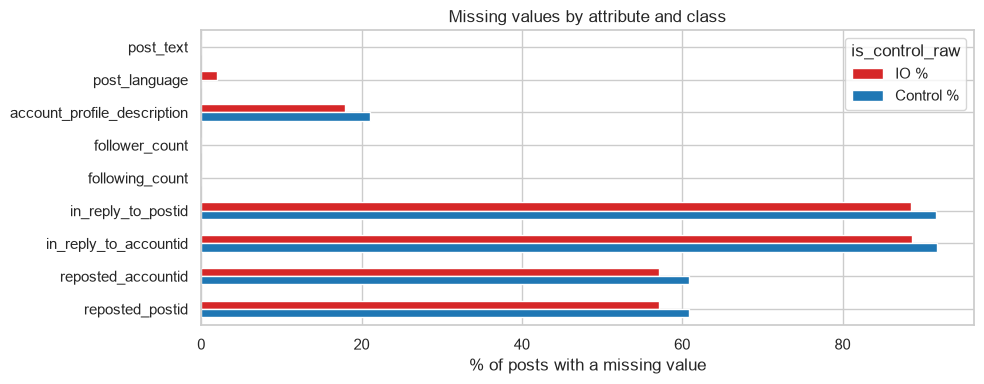

In [7]:
mq = load_posts(['is_control_raw', 'post_language', 'text_len', 'desc_len', 'follower_status', 'following_status',
                 'reply_post_key', 'reply_acc_key', 'rep_acc_key', 'rep_post_key', 'follower_count'])
missing = pd.DataFrame({
    'post_text': mq['text_len'].isna(),
    'post_language': mq['post_language'].isna(),
    'account_profile_description': mq['desc_len'].isna(),
    'follower_count': mq['follower_status'].eq(1),
    'following_count': mq['following_status'].eq(1),
    'in_reply_to_postid': mq['reply_post_key'].eq(0),
    'in_reply_to_accountid': mq['reply_acc_key'].eq(0),
    'reposted_accountid': mq['rep_acc_key'].eq(0),
    'reposted_postid': mq['rep_post_key'].eq(0),
})
miss = missing.groupby(mq['is_control_raw'].astype(str)).mean().T * 100
miss = miss.rename(columns={'False': 'IO %', 'True': 'Control %'}).drop(columns='is_control?', errors='ignore')
miss['overall %'] = missing.mean() * 100
miss['missing count'] = missing.sum()
print('Other fields (ioCountry, postid, accountid, post_time, account_creation_date, lists, is_repost) are never '
      'missing.')
display(miss.round(3))
print(f'Posts whose account reports 0 followers (possible "hidden" missing value, [DU] p. 64): '
      f'{(mq["follower_count"] == 0).mean() * 100:.2f}%')

# Bar chart of the missing values by class ([DU] p. 27; a missing-value plot is suggested in [Q&A Q2])
ax = miss[['IO %', 'Control %']].plot(kind='barh', figsize=(10, 4), color=[CLASS_PALETTE['IO'], CLASS_PALETTE['Control']])
ax.set_xlabel('% of posts with a missing value')
ax.set_title('Missing values by attribute and class')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

* The reply and repost identifiers are missing **by design** (structural missingness): they exist only when the
  post is a reply or a repost, so their absence encodes the post type and is not a data error.
* `account_profile_description` is missing for ≈19% of the posts: an empty biography is itself a behavioural
  signal (feature `has_description`).
* `post_language` is missing for ≈1% of the posts – **only IO posts** (≈2% of them), a first hint of non-standard
  publishing tools. It becomes an explicit `unknown` category.
* `post_text` is missing for 3 posts; `follower_count` / `following_count` for ≈1.3k posts each (repaired at
  account level in 1.2.5). A count of 0 followers is plausible (new or fake accounts), so zeros are not treated as
  hidden missing values.

### 1.2.2 Syntactic accuracy (values outside the domain)

In [8]:
print('is_control raw values:')
display(mq['is_control_raw'].value_counts().to_frame('posts'))
del mq, missing
_ = gc.collect()

cq = load_posts(['is_repost_raw', 'follower_status', 'follower_bad_token', 'following_status', 'following_bad_token'])
print('is_repost raw values:')
display(cq['is_repost_raw'].value_counts().to_frame('posts'))
status_tab = pd.DataFrame({
    'follower_count': cq['follower_status'].map(COUNT_STATUS).value_counts(),
    'following_count': cq['following_status'].map(COUNT_STATUS).value_counts()}).fillna(0).astype(int)
display(status_tab)
tokens = pd.concat([cq['follower_bad_token'].dropna(), cq['following_bad_token'].dropna()]).value_counts()
print('Non-numeric tokens found in follower_count / following_count:')
display(tokens.to_frame('occurrences').T)
del cq
_ = gc.collect()

is_control raw values:


,posts
is_control_raw,
False,5230077
True,3483167
is_control?,1112


is_repost raw values:


,posts
is_repost_raw,
False,5109181
True,3605175


,follower_count,following_count
valid,8709796,8709975
non-numeric token,2265,2160
missing,1318,1192
negative,977,1029


Non-numeric tokens found in follower_count / following_count:


,unknown,NaN-ish,error,none,many,12abc,??42,4O00,ten,"1,2,3"
occurrences,517,516,508,499,480,414,384,377,370,360


* The class label contains **1,112 posts with the value `is_control?`** (≈0.01%).
* `follower_count` and `following_count` contain **text in numerical attributes** (`unknown`, `NaN-ish`, `error`,
  `none`, `many`, `12abc`, `??42`, `4O00` with a letter O, `ten`, `1,2,3`) and **negative values** – both outside
  the domain of a count. No non-integer value was found. `is_repost` contains only valid booleans.
* Since `is_control`, `follower_count` and `following_count` are **account attributes** repeated on every post,
  they can be repaired from the other posts of the same account (1.2.5).

### 1.2.3 Duplicate data (with the composite key)

In [9]:
keys = load_posts(['row_h', 'post_key', 'ioCountry', 'accountid', 'acc_key', 'text_h', 'post_time',
                   'account_creation_date', 'is_control_raw'])
exact_dup = keys['row_h'].duplicated()
print(f'Exact duplicated rows (identical in every field, ioCountry included): {exact_dup.sum():,}')
k1 = keys[~exact_dup]
key_dup = k1['post_key'].duplicated(keep=False)
grp = k1[key_dup].groupby('post_key').agg(n=('acc_key', 'size'), n_accounts=('acc_key', 'nunique'),
                                         n_texts=('text_h', 'nunique'), n_times=('post_time', 'nunique'))
print(f'Remaining records sharing the same (ioCountry, postid): {key_dup.sum():,} in {len(grp):,} groups')
display(grp.assign(same_account=grp['n_accounts'].eq(1), same_text=grp['n_texts'].eq(1),
                   same_time=grp['n_times'].eq(1))[['same_account', 'same_text', 'same_time']]
        .value_counts().to_frame('groups'))

# Is there a pattern telling which record of a duplicated key is the right one? ([Q&A Q4, Q5])
posts_per_acc = k1.groupby('acc_key').size()
dk = k1[key_dup].assign(acc_posts=lambda d: d['acc_key'].map(posts_per_acc))
gk = dk.groupby('post_key')
pattern = pd.DataFrame({'n_accounts': gk['acc_key'].nunique(), 'min_posts': gk['acc_posts'].min(),
                        'max_posts': gk['acc_posts'].max(), 'n_labels': gk['is_control_raw'].nunique(),
                        'label': gk['is_control_raw'].first().astype(str)})
two_acc = pattern[pattern['n_accounts'] > 1]
print(f'Groups with two different accounts: {len(two_acc)} | groups where one account has no other post: '
      f'{int((two_acc["min_posts"] == 1).sum())} | median number of posts of the two accounts: '
      f'{two_acc["min_posts"].median():.0f} and {two_acc["max_posts"].median():.0f} | groups mixing IO and control '
      f'labels: {int((pattern["n_labels"] > 1).sum())} | label of the groups: {pattern["label"].value_counts().to_dict()}')
del dk, gk, posts_per_acc

Exact duplicated rows (identical in every field, ioCountry included): 1,579


Remaining records sharing the same (ioCountry, postid): 601 in 296 groups


groups
same_account same_text same_time        
False        True      True          149
             False     True           76
True         False     True           70
False        False     False           1

Groups with two different accounts: 226 | groups where one account has no other post: 1 | median number of posts of the two accounts: 99 and 99 | groups mixing IO and control labels: 2 | label of the groups: {'True': 295, 'False': 1}


**The same raw account id in several operations.** Identifiers were anonymised separately for every operation, so
the composite key gives a different `acc_key` to the same raw `accountid` in two operations. How many such ids are
there, and are they the same posts published twice or different posts of the same user?

In [10]:
raw_ids = k1.groupby('accountid', observed=True)['ioCountry'].nunique()
multi_ids = raw_ids[raw_ids > 1].index
mk = k1[k1['accountid'].isin(multi_ids)].copy()
mk['accountid'] = mk['accountid'].astype(str)
mk['ioCountry'] = mk['ioCountry'].astype(str)
mk['post_sig'] = mk['text_h'].astype(str) + '|' + mk['post_time'].astype(str)      # same text at the same second
mk['day'] = mk['post_time'].dt.normalize()
rel_rows = []
for aid, d in mk.groupby('accountid'):
    sigs = [set(s) for _, s in d.groupby('ioCountry')['post_sig']]
    days = [set(s) for _, s in d.groupby('ioCountry')['day']]
    common = len(set.intersection(*sigs)) / len(set.union(*sigs))
    rel_rows.append({'accountid': aid, 'operations': len(sigs), 'common': common,
                     'shared day': len(set.intersection(*days)) > 0,
                     'pair': ' + '.join(sorted(d['ioCountry'].unique()))})
multi = pd.DataFrame(rel_rows)
multi['relation'] = np.select([multi['common'] == 1, multi['common'] > 0],
                              ['the same posts in every operation', 'partly the same posts'],
                              'different posts (different days)')
print(f'Raw accountid values occurring in more than one operation: {len(multi_ids):,} '
      f'-> {mk["acc_key"].nunique():,} composite accounts with {len(mk):,} posts; labels of these posts: '
      f'{mk["is_control_raw"].astype(str).value_counts().to_dict()}')
print('Distinct accounts – raw accountid:', f'{keys["accountid"].nunique():,}',
      '| composite (ioCountry, accountid):', f'{keys["acc_key"].nunique():,}')
display(pd.crosstab(multi['relation'], multi['operations'], margins=True))
print('Ids with different posts that share at least one day across operations:',
      int(multi.loc[multi['relation'].str.startswith('different'), 'shared day'].sum()))
print('Most frequent combinations of operations:', multi['pair'].value_counts().head(5).to_dict())


def id_in_operations(aid: str) -> pd.DataFrame:
    d = mk[mk['accountid'] == aid]
    return d.groupby('ioCountry').agg(acc_key=('acc_key', 'first'), posts=('post_key', 'size'),
                                      label=('is_control_raw', 'first'), first_post=('post_time', 'min'),
                                      last_post=('post_time', 'max'), days=('day', 'nunique'))


for rel in ['different posts (different days)', 'the same posts in every operation']:
    ex_id = multi[(multi['relation'] == rel) & (multi['operations'] == 2)]['accountid'].iloc[0]
    print(f'Example – {rel}: raw accountid {ex_id}')
    display(id_in_operations(ex_id))
del grp, raw_ids, mk

Raw accountid values occurring in more than one operation: 1,295 -> 2,664 composite accounts with 230,735 posts; labels of these posts: {'True': 230712, 'is_control?': 23}
Distinct accounts – raw accountid: 85,156 | composite (ioCountry, accountid): 86,525


operations,2,3,4,All
relation,,,,
different posts (different days),743,53,6,802
partly the same posts,51,0,0,51
the same posts in every operation,434,7,1,442
All,1228,60,7,1295


Ids with different posts that share at least one day across operations: 0
Most frequent combinations of operations: {'iran_4 + uae': 340, 'iran_1 + iran_4': 164, 'ecuador + russia_1': 161, 'iran_1 + russia_1': 155, 'ecuador + iran_4': 92}
Example – different posts (different days): raw accountid 0041b60d9d520a79641d05af0cb1218e0333800538


,acc_key,posts,label,first_post,last_post,days
ioCountry,,,,,,
iran_1,8698751389176082826,82,True,2014-11-16 11:30:12,2015-12-04 23:59:37,2
iran_4,16819015739385293718,9,True,2015-01-27 11:28:15,2015-01-27 23:59:00,1


Example – the same posts in every operation: raw accountid 003730584595346580402eab6f424012a07746a4e8


,acc_key,posts,label,first_post,last_post,days
ioCountry,,,,,,
iran_1,15630730889624952489,51,True,2015-10-08 02:39:32,2015-10-08 23:59:54,1
iran_4,13824648425242729442,51,True,2015-10-08 02:39:32,2015-10-08 23:59:54,1


* **1,579 rows are exact copies** of other rows → removed.
* 296 composite post keys `(ioCountry, postid)` (601 records) occur more than once with different content inside
  the same operation – a data problem according to [Q&A Q4, Q5]: 149 groups share text and time but have two
  different accounts, 77 differ in account and text, 70 have the same account but different texts. We looked for a
  pattern telling which record is the right one: both accounts are ordinary accounts (median ≈ 99 posts each; in only
  one group an account has no other post), all groups but one share the same timestamp and almost all the same
  label, so the
  data give **no criterion to prefer one record**. Following [Q&A Q5] we declare the pipeline: a post is counted
  once, keeping the **first record of every composite key** (the other ≈300 records, 0.003% of the posts, are
  dropped).
* **The same raw id in several operations.** Identifiers were hashed per country, so the same user can have different
  ids in different operations and cannot be linked across them in general [Q&A Q4]; conversely, the same id in two
  countries is not a hash collision: it is the same user [Q&A Q16]. 1,295 raw account ids occur in 2 (1,228 ids), 3 (60) or 4 (7)
  operations: 2,664 composite accounts, all control (230,712 posts labelled `True`, 23 `is_control?`). For **442**
  ids the posts are **identical in every operation** – the same posts of the same day were included in two or more
  releases (second example: the same 51 posts of 8 October 2015 in `iran_1` and `iran_4`). For **802** ids the posts are
  **completely different and never fall on the same day** – the same user was sampled for different operations on
  different days (first example: 82 posts on two days of 2014–2015 in `iran_1`, 9 posts on 27 January 2015 in
  `iran_4`); 51 ids share part of their posts. The most frequent combinations are `iran_4 + uae` (340 ids),
  `iran_1 + iran_4` (164) and `ecuador + russia_1` (161).
* **What "treated as different accounts of different operations" means.** The unit of the analysis is the pair
  **(ioCountry, accountid)** (user–country granularity, [Q&A Q9]): a user sampled for two operations gets two keys,
  two profiles, and each profile is built only from the posts of its operation. In the first example above the same
  user is one profile in each operation, each with its own posts and days. We keep the two profiles because every
  profile must belong to one operation: IO and control accounts are compared inside an operation, the samples are
  stratified by operation, and features such as in-network reposts, copied texts and template biographies are
  defined *inside* the operation. Merging the two profiles would mix two operations and, for the ids whose posts are
  identical in both operations, count the same posts twice. The cost is small: 86,525 profiles instead of 85,156 raw
  identifiers (+1.6%). For the same reason a raw `postid` occurring in two operations is **not** a duplicate.

### 1.2.4 Semantic accuracy (business rules)

In [11]:
inc = load_posts(['post_key', 'acc_key', 'is_control_raw', 'post_time', 'account_creation_date', 'reply_post_key',
                  'reply_acc_key', 'is_repost_raw', 'rep_acc_key', 'rep_post_key', 'follower_count',
                  'follower_status'])
inc = inc[~exact_dup.to_numpy()]
# Replies whose replied post is itself in the data: does in_reply_to_accountid equal the author of that post?
author = inc.drop_duplicates('post_key').set_index('post_key')['acc_key']
known = (inc['reply_post_key'] != 0) & inc['reply_post_key'].isin(author.index)
complete_known = known & (inc['reply_acc_key'] != 0)
same_author = (inc.loc[complete_known, 'reply_post_key'].map(author) == inc.loc[complete_known, 'reply_acc_key']).mean()
recoverable = int((known & (inc['reply_acc_key'] == 0)).sum())
del author, known, complete_known
valid_lab = inc[inc['is_control_raw'].isin(['True', 'False'])]
labels_per_acc = valid_lab.groupby('acc_key')['is_control_raw'].nunique()
bad_lab_accs = inc.loc[~inc['is_control_raw'].isin(['True', 'False']), 'acc_key'].unique()
is_rep = inc['is_repost_raw'].eq('True')
checks = {
    'accounts with both True and False labels': int((labels_per_acc > 1).sum()),
    'accounts with an invalid label on some post': len(bad_lab_accs),
    '  ... of which have a valid label on other posts': int(np.isin(bad_lab_accs, labels_per_acc.index).sum()),
    'accounts with >1 creation date': int((inc.groupby('acc_key')['account_creation_date'].nunique() > 1).sum()),
    'accounts with >1 valid follower_count value': int(
        (inc[inc['follower_status'] == 0].groupby('acc_key')['follower_count'].nunique() > 1).sum()),
    'posts published before the account creation date': int((inc['post_time'] < inc['account_creation_date']).sum()),
    'replies with in_reply_to_postid but no in_reply_to_accountid':
        int(((inc['reply_post_key'] != 0) & (inc['reply_acc_key'] == 0)).sum()),
    'replies with in_reply_to_accountid but no in_reply_to_postid':
        int(((inc['reply_post_key'] == 0) & (inc['reply_acc_key'] != 0)).sum()),
    '  missing in_reply_to_accountid whose replied post is in the data': recoverable,
    '% of complete replies (replied post in the data) whose account id = author of the replied post':
        round(100 * same_author, 1),
    'reposts without reposted ids': int((is_rep & (inc['rep_acc_key'] == 0)).sum()),
    'non-reposts with reposted ids': int((~is_rep & (inc['rep_acc_key'] != 0)).sum()),
    'posts that are both reply and repost': int((is_rep & (inc['reply_post_key'] != 0)).sum()),
    'self-replies (reply to own account)': int(((inc['reply_acc_key'] == inc['acc_key']) & (inc['reply_acc_key'] != 0)).sum()),
    'self-reposts (repost of own post)': int(((inc['rep_acc_key'] == inc['acc_key']) & (inc['rep_acc_key'] != 0)).sum()),
}
display(pd.Series(checks, name='count', dtype=object).to_frame())
del inc, valid_lab, is_rep
_ = gc.collect()

,count
accounts with both True and False labels,1
accounts with an invalid label on some post,913
... of which have a valid label on other posts,913
accounts with >1 creation date,0
accounts with >1 valid follower_count value,984
posts published before the account creation date,0
replies with in_reply_to_postid but no in_reply_to_accountid,74608
replies with in_reply_to_accountid but no in_reply_to_postid,63456
missing in_reply_to_accountid whose replied post is in the data,4020
% of complete replies (replied post in the data) whose account id = author of the replied post,85.2000


In [12]:
# Plausibility of the counts (semantic accuracy): no account can follow or be followed by more accounts than the
# platform has users, so any count above 10^9 is impossible even if it is a well-formed number.
MAX_PLAUSIBLE = 1e9
cnt = load_posts(['row_h', 'post_key', 'acc_key', 'ioCountry', 'is_control_raw', 'post_time', 'follower_count',
                  'follower_status', 'following_count', 'following_status'])
cnt = cnt[~cnt['row_h'].duplicated() & ~cnt['post_key'].duplicated()].reset_index(drop=True)
cnt = cnt.sort_values(['acc_key', 'post_time'], kind='stable').reset_index(drop=True)
plaus = []
for col, st in [('follower_count', 'follower_status'), ('following_count', 'following_status')]:
    v = cnt[col].where(cnt[st] == 0)
    big = v > MAX_PLAUSIBLE
    ok = v.where(~big)
    nun = ok.groupby(cnt['acc_key']).nunique()
    spread = (ok.groupby(cnt['acc_key']).max() / ok.groupby(cnt['acc_key']).min().clip(lower=1))[nun > 1]
    plaus.append({'attribute': col, 'well-formed values': int(v.notna().sum()), 'values > 10^9': int(big.sum()),
                  'accounts with such values': cnt.loc[big, 'acc_key'].nunique(),
                  '... IO / control posts': f"{int((big & cnt['is_control_raw'].eq('False')).sum())} / "
                                            f"{int((big & cnt['is_control_raw'].eq('True')).sum())}",
                  'smallest value > 10^9': v[big].min(), 'largest value <= 10^9': ok.max(),
                  'values in (10^8, 10^9]': int(((ok > 1e8)).sum()),
                  'accounts whose plausible value changes': int((nun > 1).sum()),
                  'median change max/min (%)': 100 * (spread.median() - 1),
                  '99th percentile change (%)': 100 * (spread.quantile(0.99) - 1)})
display(pd.DataFrame(plaus).set_index('attribute').T)
ex_acc = cnt.loc[cnt['following_count'].gt(MAX_PLAUSIBLE) & cnt['following_status'].eq(0), 'acc_key'].iloc[0]
print('Example – following_count of the posts of one account in time order:',
      cnt.loc[cnt['acc_key'] == ex_acc, 'following_count'].head(12).map('{:,.0f}'.format).tolist())

attribute,follower_count,following_count
well-formed values,8707912,8708091
values > 10^9,493,518
accounts with such values,431,455
... IO / control posts,305 / 188,317 / 201
smallest value > 10^9,"10,080,725,079.0000","10,150,822,424.0000"
largest value <= 10^9,"19,912,528.0000","2,301,841.0000"
"values in (10^8, 10^9]",0,0
accounts whose plausible value changes,563,264
median change max/min (%),0.0140,0.0247
99th percentile change (%),0.4274,3.2794


Example – following_count of the posts of one account in time order: ['2,751', '2,751', '2,751', '2,751', '2,751', '2,751', '2,751', '2,751', '27,060,757,020', '2,751', '2,751', '2,751']


* The class label is consistent at account level: every account with an `is_control?` post has a valid label on its
  other posts, and only one account has contradicting valid labels (resolved by majority).
* `account_creation_date` is constant per account and no post precedes the creation of its account.
* `follower_count` and `following_count` are per-account snapshots. Besides the invalid tokens of 1.2.2, **493 follower counts and 518 following
  counts are well-formed numbers above 10^9** (between 1.0·10^10 and 1.0·10^11): impossible values, since no account
  can be followed by or follow more accounts than the platform has users – a semantic accuracy error ([DU] p. 18).
  The separation is sharp: the largest plausible values are 19.9 million followers and 2.3 million following, and no
  value lies between 10^8 and 10^9. They occur in 431 and 455 accounts, IO and control alike, as isolated values in
  otherwise constant sequences (example above: 2,751 … 27,060,757,020 … 2,751). Without them the counts of an account
  are constant or change very little over time: they change in 563 (followers) and 264 (following) accounts, by
  0.01–0.02% at the median and by less than 0.5% / 3.3% for 99% of them – genuine snapshots taken at different moments.
* **Partial reply identifiers are data problems in both directions** [Q&A Q17]: ≈75k posts have
  `in_reply_to_postid` without `in_reply_to_accountid` and ≈63k the opposite – one of the two pieces of information
  was not recorded; only when both are missing the post is not a reply. A missing post id cannot be recovered. A
  missing account id could in principle be taken from the author of the replied post when that post is in the data
  (≈4k cases), but the rule "reply account = author of the replied post" holds only for ≈85% of the complete replies
  whose original is in the data (a further semantic inconsistency), so this inference would not be reliable and is not
  applied. Pipeline: a post is a **reply** if *either* identifier is present; the account replied to is used only when
  recorded. Repost fields are perfectly consistent with `is_repost`.
* Self-replies (threads) and self-reposts are legitimate behaviours (self-reposting is an amplification tactic):
  they are kept.

### 1.2.5 Cleaning

**Which substitution for the invalid counts?** An invalid `follower_count` / `following_count` (missing,
non-numeric, negative, or above 10^9) must be replaced by an estimate. Both candidates are substitutions with the
median of a segment of the same account ([DP] p. 26); they differ in the segment:

* **(A) account median** – the median of all the valid values of the account;
* **(B) time neighbours** – the median of the valid values of the **previous and the next post of the same account**
  in `post_time` order (the mean of the two values when both exist; the only one available for the first or last
  post of an account).

(B) follows the snapshot that was valid when the post was collected, so it should be better when a count changes over
time; (A) uses more values. The data decide: we hide valid values one at a time (leave-one-out), estimate them with
both methods and compare the estimate with the hidden value, on a random sample of valid posts of accounts with at
least 3 valid values and on all the posts of the accounts whose count changes.

In [13]:
loo_rows = []
loo_rng = np.random.default_rng(RANDOM_STATE)
for col, st in [('follower_count', 'follower_status'), ('following_count', 'following_status')]:
    good = (cnt[st] == 0) & (cnt[col] <= MAX_PLAUSIBLE)
    vv = cnt.loc[good, ['acc_key', col]].reset_index(drop=True)          # valid values, time order inside accounts
    size = vv.groupby('acc_key')[col].transform('size')
    vv = vv[size >= 3].reset_index(drop=True)
    pos = vv.groupby('acc_key').cumcount().to_numpy()
    arrays = {k: g[col].to_numpy() for k, g in vv.groupby('acc_key')}
    changing = vv.groupby('acc_key')[col].transform('nunique').to_numpy() > 1
    for pool_name, pool in [('random sample of valid posts', loo_rng.choice(len(vv), 20_000, replace=False)),
                            ('accounts whose value changes', np.flatnonzero(changing))]:
        est = np.empty((len(pool), 3))
        for i, r in enumerate(pool):
            arr, j = arrays[vv.at[r, 'acc_key']], pos[r]
            neigh = arr[max(j - 1, 0):j].tolist() + arr[j + 1:j + 2].tolist()
            est[i] = arr[j], np.median(np.delete(arr, j)), np.mean(neigh)
        for meth, k in [('(A) account median', 1), ('(B) time neighbours', 2)]:
            err = np.abs(est[:, k] - est[:, 0])
            loo_rows.append({'attribute': col, 'test posts': pool_name, 'method': meth, 'posts': len(pool),
                             'exact estimate %': 100 * (err == 0).mean(),
                             'mean relative error %': 100 * (err / np.maximum(est[:, 0], 1)).mean(),
                             'max relative error %': 100 * (err / np.maximum(est[:, 0], 1)).max()})
display(pd.DataFrame(loo_rows).set_index(['attribute', 'test posts', 'method']).round(3))

# Where are the real invalid values? Are their neighbours available?
avail = []
for col, st in [('follower_count', 'follower_status'), ('following_count', 'following_status')]:
    good = (cnt[st] == 0) & (cnt[col] <= MAX_PLAUSIBLE)
    v = cnt[col].where(good)
    prev_v = v.groupby(cnt['acc_key']).ffill()
    next_v = v.groupby(cnt['acc_key']).bfill()
    bad = ~good
    both = bad & prev_v.notna() & next_v.notna()
    avail.append({'attribute': col, 'invalid values': int(bad.sum()), 'previous and next valid post': int(both.sum()),
                  'only previous': int((bad & prev_v.notna() & next_v.isna()).sum()),
                  'only next': int((bad & prev_v.isna() & next_v.notna()).sum()),
                  'no valid value in the account': int((bad & prev_v.isna() & next_v.isna()).sum()),
                  'previous = next (%)': 100 * (prev_v[both] == next_v[both]).mean()})
display(pd.DataFrame(avail).set_index('attribute').round(2))
del vv, arrays

posts  exact estimate %  mean relative error %  max relative error %
attribute       test posts                   method                                                                                    
follower_count  random sample of valid posts (A) account median    20000           99.0300                 0.0000                0.3040
                                             (B) time neighbours   20000           99.9950                 0.0000                0.0070
                accounts whose value changes (A) account median   193731           52.3220                 0.0200              600.0000
                                             (B) time neighbours  193731           99.2050                 0.0070              600.0000
following_count random sample of valid posts (A) account median    20000           99.5600                 0.0000                0.7040
                                             (B) time neighbours   20000           99.9850                 0.0000                0.0630
                accounts whose value changes (A) account median    92320           57.3440                 0.0350               25.0000
                                             (B) time neighbours   92320           99.3350                 0.0010               20.8330

,invalid values,previous and next valid post,only previous,only next,no valid value in the account,previous = next (%)
attribute,,,,,,
follower_count,5053,4939,59,51,4,100.0000
following_count,4899,4802,52,42,3,99.9600


**Result.** Both methods reproduce almost every hidden value, but **(B) is better**: on a random sample of valid posts it
is exact for 99.995% of the follower counts (A: 99.03%) and 99.985% of the following counts (A: 99.56%); on the
accounts whose count changes over time – the cases where the choice matters – (B) is exact for ≈99% of the posts and
(A) only for 52–57%, because the median mixes snapshots taken at different moments. For the real invalid values (5,053
follower and 4,899 following values, impossible counts included) both neighbours exist in 98% of the cases and they
are equal in 100% / 99.96% of them; 110 / 94 values are the first or the last post of their account (one neighbour
only), and 4 / 3 accounts have no valid value at all (median of the operation). Method (B) is therefore used: it
is the median of the smallest meaningful segment (the same account at the same moment) and falls back to larger
segments only when needed.

**Cleaning rules** (all keyed by the composite keys):

1. drop exact duplicate rows and keep the first record of every `(ioCountry, postid)`;
2. `is_control`: majority of the valid labels of the account `(ioCountry, accountid)` (repairs every `is_control?`);
3. `follower_count`, `following_count`: values that are missing, non-numeric, negative or above 10^9 are invalid; each
   invalid value is replaced by the **median of the valid values of the previous and next post of the same account**
   (method B; only one of them for the first or last post); accounts without any valid value receive the median of
   the accounts of their operation. Valid values are kept. The profile of an account uses the median of the values
   of its posts;
4. `post_language`: missing → explicit category `unknown`;
5. new boolean post-type flags: `is_reply` (any reply identifier present) and `is_repost`.

In [14]:
keep = (~exact_dup & ~keys['post_key'].duplicated()).to_numpy()   # rule 1
del keys, k1, exact_dup, key_dup, cnt
_ = gc.collect()

if not CLEAN_PQ.exists():
    cols = ['ioCountry', 'accountid', 'acc_key', 'post_key', 'is_control_raw', 'post_time', 'account_creation_date',
            'application_name', 'post_language', 'is_repost_raw', 'reply_post_key', 'reply_acc_key', 'rep_acc_key',
            'rep_post_key', 'text_len', 'n_words', 'raw_text_len', 'text_h', 'n_hashtags', 'n_urls', 'n_mentions',
            'desc_len', 'desc_h', 'follower_count', 'follower_status', 'following_count', 'following_status']
    clean = load_posts(cols)
    # the label is an account attribute, computed on all the records of the account
    lab_valid = clean['is_control_raw'].astype(str).map({'True': 1.0, 'False': 0.0})
    acc_label = lab_valid.groupby(clean['acc_key']).mean().round().astype(bool)                 # rule 2
    clean = clean[keep].reset_index(drop=True)
    clean['is_control'] = clean['acc_key'].map(acc_label).astype(bool)
    order = clean.sort_values(['acc_key', 'post_time'], kind='stable').index                     # time order per account
    for col, st in [('follower_count', 'follower_status'), ('following_count', 'following_status')]:   # rule 3
        v = clean[col].where((clean[st] == 0) & (clean[col] <= MAX_PLAUSIBLE)).loc[order]
        acc_o = clean['acc_key'].loc[order]
        prev_v, next_v = v.groupby(acc_o).ffill(), v.groupby(acc_o).bfill()
        v = v.fillna((prev_v + next_v) / 2).fillna(prev_v).fillna(next_v)
        clean[col] = v.reindex(clean.index)
        acc_med = clean.groupby('acc_key')[col].median()
        op_median = acc_med.groupby(clean.drop_duplicates('acc_key').set_index('acc_key')['ioCountry']).median()
        clean[col] = clean[col].fillna(clean['ioCountry'].map(op_median).astype(float))
    clean['post_language'] = clean['post_language'].cat.add_categories('unknown').fillna('unknown')   # rule 4
    clean['is_repost'] = clean['is_repost_raw'].astype(str).eq('True')                                # rule 5
    clean['is_reply'] = (clean['reply_post_key'] != 0) | (clean['reply_acc_key'] != 0)
    clean = clean.drop(columns=['is_control_raw', 'is_repost_raw', 'follower_status', 'following_status'])
    clean.to_parquet(CLEAN_PQ, index=False, compression='zstd')
    del clean, acc_label, lab_valid, order, v, prev_v, next_v, acc_o, acc_med, op_median
    _ = gc.collect()
del keep

posts = pd.read_parquet(CLEAN_PQ)
posts['class'] = pd.Categorical(np.where(posts['is_control'], 'Control', 'IO'), categories=CLASS_ORDER)
n_acc = posts['acc_key'].nunique()
print(f'Cleaned posts: {len(posts):,} (removed {n_raw - len(posts):,} duplicated records) | accounts: {n_acc:,}')
print('Accounts per class:', posts.drop_duplicates('acc_key')['class'].value_counts().to_dict())
print('Remaining problems -> invalid label:', int(posts['is_control'].isna().sum()),
      '| follower/following missing:', int(posts[['follower_count', 'following_count']].isna().sum().sum()),
      '| negative counts:', int((posts[['follower_count', 'following_count']] < 0).sum().sum()))

Cleaned posts: 8,712,472 (removed 1,884 duplicated records) | accounts: 86,525
Accounts per class: {'Control': 75608, 'IO': 10917}
Remaining problems -> invalid label: 0 | follower/following missing: 0 | negative counts: 0


### 1.2.6 Timeliness: is `post_time` the publication time or the collection time?

A first look at the data shows an unusual temporal structure in the control posts (a large share published at
23h UTC, most control accounts active on a single day). If `post_time` were the moment at which the data were
collected (e.g. by web scraping) instead of the real publication time, every time-based feature would be
meaningless. We check this with simple descriptive statistics ([DU] pp. 22, 31–34; [DU] p. 20 – *timeliness*):

1. the **resolution** of the timestamps (share of timestamps with seconds = 00);
2. the **hour-of-day** distribution;
3. the **time window** covered by each account (first/last post, same calendar day or not);
4. the relation between the number of posts of an account and the length of its window;
5. the **logical order** of reposts and replies: a repost / reply cannot be published before the original post.
   If the timestamps were collection times (or artificial), this rule would be violated.

`post_time` is expressed in **UTC** [Q&A Q3], and UTC is used consistently for all the operations [Q&A Q14]: no local
time zone is inferred, so every "hour of day" in the notebook is a UTC hour.

% of posts whose timestamp has seconds = 00 (uniform seconds would give 1.7%):


class,IO,Control
ioCountry,,
ecuador,100.0000,1.9000
iran_1,100.0000,1.6000
iran_4,100.0000,1.6000
russia_1,100.0000,1.5000
uae,100.0000,1.7000


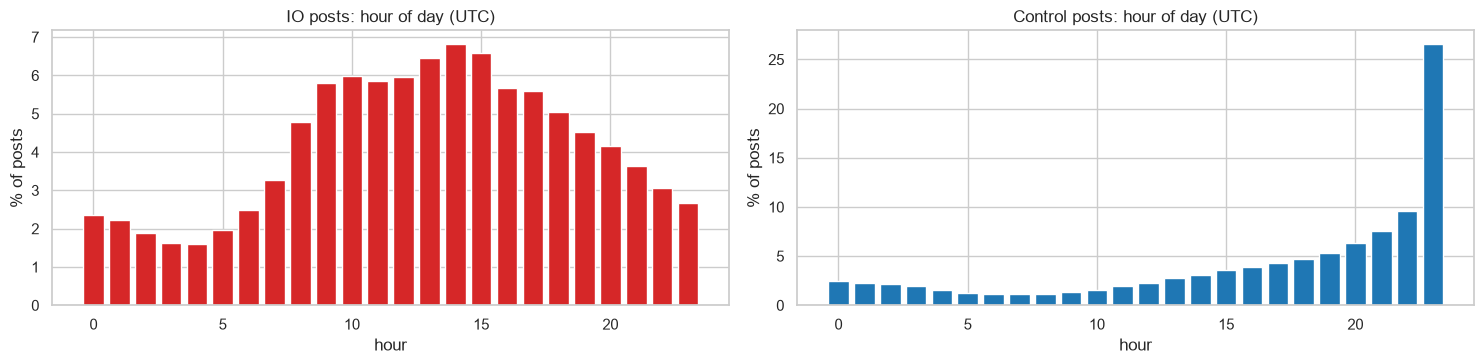

,% accounts with all posts on one calendar day,median gap between consecutive posts (s),% posts at 23h UTC
class,,,
IO,5.9000,720.0000,2.7000
Control,94.9000,72.0000,26.6000


accounts  % on one UTC day  % within 24 hours  on_2_or_more_days  median_posts
operation class                                                                                  
ecuador   IO            787            7.4000            15.1000                729       33.0000
          Control     21137           95.6000            95.7000                935       16.0000
iran_1    IO            660            5.2000             5.3000                626      196.0000
          Control      5015           97.7000            97.7000                115       21.0000
iran_4    IO           2519            8.0000             8.2000               2318       22.0000
          Control      7612           96.8000            96.8000                244       21.0000
russia_1  IO           3293            5.9000             6.1000               3100      135.0000
          Control     31299           92.9000            92.9000               2231       23.0000
uae       IO           3658            4.3000             4.7000               3501      186.0000
          Control     10545           96.8000            96.8000                333       18.0000

Control account-days: 87,078 | posts per account-day: median 24, maximum 99 | account-days whose last post is at 23h UTC: 98.8%
Control accounts observed on 2 or more days: 3,858 (5.1%) | number of days: {2: 2456, 3: 622, 4: 249, 5: 125, 6: 78} | median time between their first and last post: 81 days | median posts: 174
Control accounts with >= 5 posts, all on one day: 55,329
  last post between 23:00 and 23:59: 99.3%  (after 23:50: 97.1%)


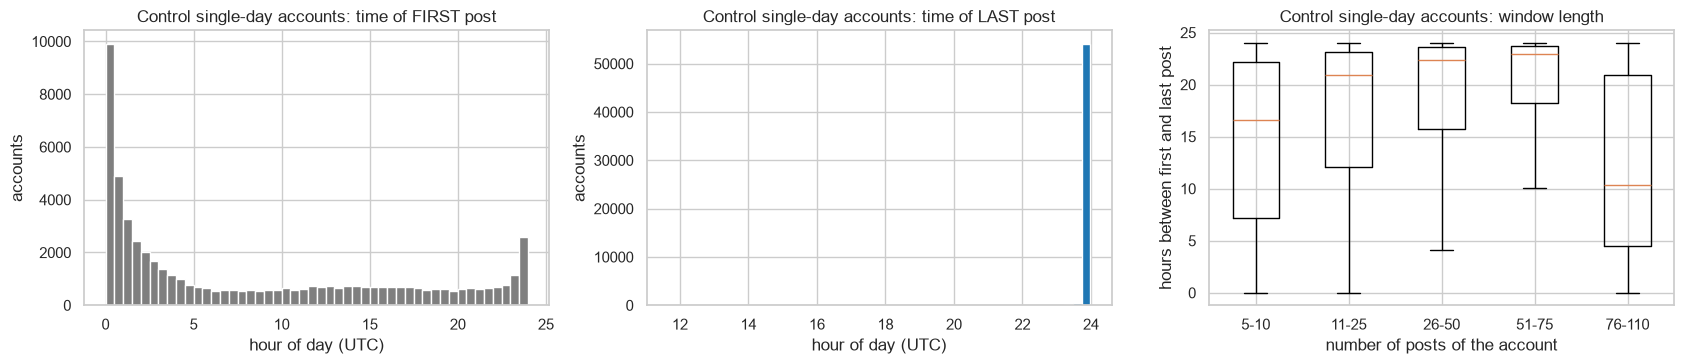

,type,class of the answering post,pairs found in the data,% published BEFORE the original,median delay (minutes)
0,repost,IO,141608,0.0060,56.0000
1,repost,Control,16259,0.0000,4.3170
2,reply,IO,15375,0.0000,13.0000
3,reply,Control,11915,0.0000,1.5330


% of control posts published on a day on which the same operation has IO posts: 100.0%


,control period,days with control posts,... on an IO day (%),days of the control period with IO posts (%),P(all control days on IO days by chance),IO days that also have control posts (%),busiest control day
operation,,,,,,,
ecuador,2010-06-14 -> 2019-07-30,2749,100.0000,97.3000,10^-33,84.3000,"2018-04-12: 12,398 control / 550 IO posts"
iran_1,2012-03-12 -> 2018-08-28,581,100.0000,98.8000,10^-3,24.6000,"2017-03-28: 2,442 control / 452 IO posts"
iran_4,2013-11-28 -> 2019-05-06,1284,100.0000,98.6000,10^-8,64.5000,"2018-03-16: 11,412 control / 319 IO posts"
russia_1,2009-11-22 -> 2018-06-21,1296,100.0000,99.2000,10^-5,41.6000,"2014-07-26: 24,789 control / 2,118 IO posts"
uae,2011-09-23 -> 2019-05-26,1601,100.0000,86.7000,10^-99,65.5000,"2019-03-06: 11,610 control / 5,181 IO posts"


In [15]:
pt = posts[['ioCountry', 'class', 'acc_key', 'post_key', 'post_time', 'rep_post_key', 'reply_post_key']].copy()
pt['hour'] = pt['post_time'].dt.hour

# 1. resolution: share of timestamps with seconds == 0
res = (pt.assign(sec0=pt['post_time'].dt.second.eq(0))
       .groupby(['ioCountry', 'class'], observed=True)['sec0'].mean().unstack() * 100)
print('% of posts whose timestamp has seconds = 00 (uniform seconds would give 1.7%):')
display(res.round(1))

# 2. hour-of-day distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
for ax, cls in zip(axes, CLASS_ORDER):
    share = pt.loc[pt['class'] == cls, 'hour'].value_counts(normalize=True).sort_index() * 100
    ax.bar(share.index, share.values, color=CLASS_PALETTE[cls])
    ax.set_title(f'{cls} posts: hour of day (UTC)')
    ax.set_xlabel('hour')
    ax.set_ylabel('% of posts')
plt.tight_layout()
plt.show()

# 3. time window of every account
srt = pt.sort_values(['acc_key', 'post_time'])
g = srt.groupby('acc_key')
win = pd.DataFrame({'class': g['class'].first(), 'n': g.size(), 'first': g['post_time'].min(),
                    'last': g['post_time'].max()})
win['same_day'] = win['first'].dt.normalize() == win['last'].dt.normalize()
win['span_h'] = (win['last'] - win['first']).dt.total_seconds() / 3600
gap_s = g['post_time'].diff().dt.total_seconds()
window_tab = pd.DataFrame({
    '% accounts with all posts on one calendar day': win.groupby('class', observed=True)['same_day'].mean() * 100,
    'median gap between consecutive posts (s)': gap_s.groupby(srt['class']).median(),
    '% posts at 23h UTC': pt.groupby('class', observed=True)['hour'].apply(lambda h: (h == 23).mean() * 100),
})
display(window_tab.round(1))

# The same check per operation, and the observation unit of the control accounts: (account, UTC day)
srt_day = srt['post_time'].dt.normalize()
win['operation'] = g['ioCountry'].first()
win['days'] = srt_day.groupby(srt['acc_key']).nunique()
per_op = win.groupby(['operation', 'class'], observed=True).agg(
    accounts=('n', 'size'), one_day=('same_day', 'mean'), within_24h=('span_h', lambda s: (s <= 24).mean()),
    on_2_or_more_days=('days', lambda s: int((s >= 2).sum())), median_posts=('n', 'median'))
per_op[['one_day', 'within_24h']] *= 100
display(per_op.rename(columns={'one_day': '% on one UTC day', 'within_24h': '% within 24 hours'}).round(1))
ctrl_srt = srt[srt['class'] == 'Control']
acc_day = (ctrl_srt.groupby([ctrl_srt['acc_key'], srt_day[ctrl_srt.index]])
           .agg(n=('post_time', 'size'), last=('post_time', 'max')))
multi_day = win[(win['class'] == 'Control') & (win['days'] > 1)]
print(f'Control account-days: {len(acc_day):,} | posts per account-day: median {acc_day["n"].median():.0f}, '
      f'maximum {acc_day["n"].max()} | account-days whose last post is at 23h UTC: '
      f'{100 * (acc_day["last"].dt.hour == 23).mean():.1f}%')
print(f'Control accounts observed on 2 or more days: {len(multi_day):,} '
      f'({100 * len(multi_day) / (win["class"] == "Control").sum():.1f}%) | number of days: '
      f'{multi_day["days"].value_counts().sort_index().head(5).to_dict()} | median time between their first and last '
      f'post: {multi_day["span_h"].median() / 24:.0f} days | median posts: {multi_day["n"].median():.0f}')
del ctrl_srt, acc_day

one_day = win[(win['class'] == 'Control') & win['same_day'] & (win['n'] >= 5)]
last_tod = one_day['last'].dt.hour + one_day['last'].dt.minute / 60
first_tod = one_day['first'].dt.hour + one_day['first'].dt.minute / 60
print(f'Control accounts with >= 5 posts, all on one day: {len(one_day):,}')
print(f'  last post between 23:00 and 23:59: {(one_day["last"].dt.hour == 23).mean() * 100:.1f}%  '
      f'(after 23:50: {((one_day["last"].dt.hour == 23) & (one_day["last"].dt.minute >= 50)).mean() * 100:.1f}%)')

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
axes[0].hist(first_tod, bins=48, color='#7f7f7f')
axes[0].set_title('Control single-day accounts: time of FIRST post')
axes[1].hist(last_tod, bins=48, color='#1f77b4')
axes[1].set_title('Control single-day accounts: time of LAST post')
for ax in axes[:2]:
    ax.set_xlabel('hour of day (UTC)')
    ax.set_ylabel('accounts')
# 4. window length vs number of posts (conditional box plot, [DU] p. 37)
one_day = one_day.assign(posts_bucket=pd.cut(one_day['n'], [4, 10, 25, 50, 75, 110],
                                             labels=['5-10', '11-25', '26-50', '51-75', '76-110']))
data_bp = [one_day.loc[one_day['posts_bucket'] == b, 'span_h'] for b in one_day['posts_bucket'].cat.categories]
axes[2].boxplot(data_bp, tick_labels=list(one_day['posts_bucket'].cat.categories), showfliers=False)
axes[2].set_xlabel('number of posts of the account')
axes[2].set_ylabel('hours between first and last post')
axes[2].set_title('Control single-day accounts: window length')
plt.tight_layout()
plt.show()

# 5. order of reposts / replies with respect to the original post (same ioCountry, composite keys)
orig_time = pt.drop_duplicates('post_key').set_index('post_key')['post_time']
rows = []
for kind, col in [('repost', 'rep_post_key'), ('reply', 'reply_post_key')]:
    d = pt[(pt[col] != 0) & pt[col].isin(orig_time.index)]
    delta_h = (d['post_time'] - d[col].map(orig_time)).dt.total_seconds() / 3600
    for cls in CLASS_ORDER:
        m = d['class'] == cls
        rows.append({'type': kind, 'class of the answering post': cls, 'pairs found in the data': int(m.sum()),
                     '% published BEFORE the original': 100 * (delta_h[m] < 0).mean(),
                     'median delay (minutes)': 60 * delta_h[m].median()})
display(pd.DataFrame(rows).round(3))

io = pt[pt['class'] == 'IO']
io_days = pd.MultiIndex.from_arrays([io['ioCountry'].astype(str), io['post_time'].dt.normalize()]).unique()
ctrl = pt[pt['class'] == 'Control']
in_io_day = pd.MultiIndex.from_arrays([ctrl['ioCountry'].astype(str), ctrl['post_time'].dt.normalize()]).isin(io_days)
print(f'% of control posts published on a day on which the same operation has IO posts: {in_io_day.mean() * 100:.1f}%')

# Are the control days chosen among the IO days, or would this happen anyway?
day_rows = []
pt['day'] = pt['post_time'].dt.normalize()
for op, d in pt.groupby('ioCountry', observed=True):
    io_d = set(d.loc[d['class'] == 'IO', 'day'])
    c_d = set(d.loc[d['class'] == 'Control', 'day'])
    period = pd.date_range(min(c_d), max(c_d), freq='D')
    chance = np.mean([x in io_d for x in period])           # share of the days of the control period with IO posts
    per_day = d.groupby(['day', 'class'], observed=True).size().unstack('class').fillna(0)
    busiest = per_day['Control'].idxmax()
    day_rows.append({'operation': op, 'control period': f'{min(c_d).date()} -> {max(c_d).date()}',
                     'days with control posts': len(c_d), '... on an IO day (%)': 100 * len(c_d & io_d) / len(c_d),
                     'days of the control period with IO posts (%)': 100 * chance,
                     'P(all control days on IO days by chance)': f'10^{len(c_d) * np.log10(chance):.0f}',
                     'IO days that also have control posts (%)': 100 * len(c_d & io_d) / len(io_d),
                     'busiest control day': f'{busiest.date()}: {int(per_day.at[busiest, "Control"]):,} control / '
                                            f'{int(per_day.at[busiest, "IO"]):,} IO posts'})
display(pd.DataFrame(day_rows).set_index('operation').round(1))
del io, per_day
del pt, srt, g, gap_s, orig_time, ctrl, in_io_day, io_days, srt_day
_ = gc.collect()

**Evidence.**

* **Two different sources / formats.** Every IO timestamp has seconds = 00 (minute resolution, the format of the
  released IO archives), while control timestamps have second resolution (≈1.7% with seconds = 00, as expected for
  uniformly distributed seconds).
* **Real publication times.** Reposts and replies are **never** earlier than the post they answer, for both
  classes (the only exceptions are a few IO reposts by less than one minute, explained by the truncation of IO
  timestamps to the minute). Delays are realistic (minutes to hours). Collection times or artificial timestamps would
  violate this rule. Hence `post_time` **is the real publication time**, not the collection time.
* **A day-bounded, capped sample for the control accounts.** 94.9% of the control accounts have all their posts on a
  single UTC day (92.9% in Russia, 95.6–97.7% in the other operations), against 4–8% of the IO accounts. The unit of
  the control collection is the pair **(account, day)**: each of the 87,078 control account-days contains **at most 99
  posts** (median 24), and its last post is between 23:00 and 23:59 UTC in 98.8% of the cases. For the single-day
  accounts with at least 5 posts the last post is after 23:50 in 97.1% of the cases, the first post is often right after
  midnight, and the window becomes shorter as the number of posts approaches 99 (very active accounts fill the quota in a
  few hours before midnight). This is the pattern of a collection that, for a control account and a day, retrieved
  **at most 99 posts going backwards from 23:59:59 UTC** – which also explains the accumulation of control posts at 23h.
  "One day per control account" is therefore true for 94.9% of them, not for all: **3,858 control accounts (5.1%; 2,231
  of them in Russia) were collected on 2 or more separate days** (2,456 on two days, 622 on three, a few on dozens of
  days), with a median of 81 days between their first and last post and a median of 174 posts; each of their days is
  again a window of at most 99 posts ending at 23:59.
* **Control days are IO days.** Every control post falls on a day on which the same operation also has IO posts. For
  example, in `russia_1` on 26 July 2014 there are 24,789 control posts and 2,118 IO posts, and in no operation is there
  a day with control posts but without IO posts. In plain words: the control users were collected on days on which the
  operation was active, so IO and control posts are **matched in time** (same days, same events and topics) and their
  differences are not due to different periods. How strong is this evidence? IO accounts post almost every day, so even
  days chosen at random would usually be IO days: inside the control period 97–99% of the days have IO posts in
  Ecuador, Iran_1, Iran_4 and Russia, 87% in UAE. Still, the probability that all the control days fall on IO days by
  chance is between 10^-3 (Iran_1, 581 days) and 10^-99 (UAE), so the control days were really chosen among the IO
  days. The matching works in one direction only: 25–84% of the IO days have control posts, i.e. the control sample
  covers a subset of the days of the operation.

**Decision.** Timestamps are reliable for describing *when* the posts in the dataset were published, so the
temporal features are computed and analysed in the profiles (1.5). However, the observation window is completely
different for the two classes (IO: whole account history; control: one capped day, rarely a few separate days).
Features describing
volume and time (number of posts, active days, lifespan, concentration over days/weeks, hour-of-day profile,
inter-post times) would separate IO from control because of the **sampling design** and not because of behaviour.
They are therefore **excluded from the clustering input** (Section 2.1).

### 1.2.7 Outliers

Outliers are detected with the IQR rule: a value is an outlier if it is outside
$[L, U] = [Q_1 - 1.5\,IQR,\ Q_3 + 1.5\,IQR]$ ([DP] p. 68; box plots [DU] p. 34). Long-tailed counts are first
log-transformed, $\log_{10}(1+x)$ ([DP] pp. 64–66).

,L,U,max,low outliers,high outliers,outliers %,% IO among the outliers,% IO among all units
variable,,,,,,,,
"text_len (post, written text)",13.9100,374.4800,"1,030.0000",397815,226,4.5700,62.3800,60.0300
n_hashtags (post),0.0000,4.6600,40.0000,0,405883,4.6600,31.5200,60.0300
n_mentions (post),0.0000,4.6600,51.0000,0,114687,1.3200,39.3300,60.0300
n_urls (post),0.0000,4.6600,9.0000,0,564,0.0100,11.7000,60.0300
n_posts (account),0.0000,"3,595.6700","265,448.0000",0,214,0.2500,89.2500,12.6200
follower_count (account),0.7500,"80,265.4000","19,912,528.0000",2080,1066,3.6400,29.9700,12.6200
following_count (account),2.5600,"41,372.8300","2,301,841.0000",6290,413,7.7500,10.7300,12.6200
account_age_days (account),9.9100,"28,772.3000","4,493.4800",2872,0,3.3200,32.9700,12.6200
desc_len (account),0.0000,"7,656.6800",773.0000,0,0,0.0000,NaN,12.6200


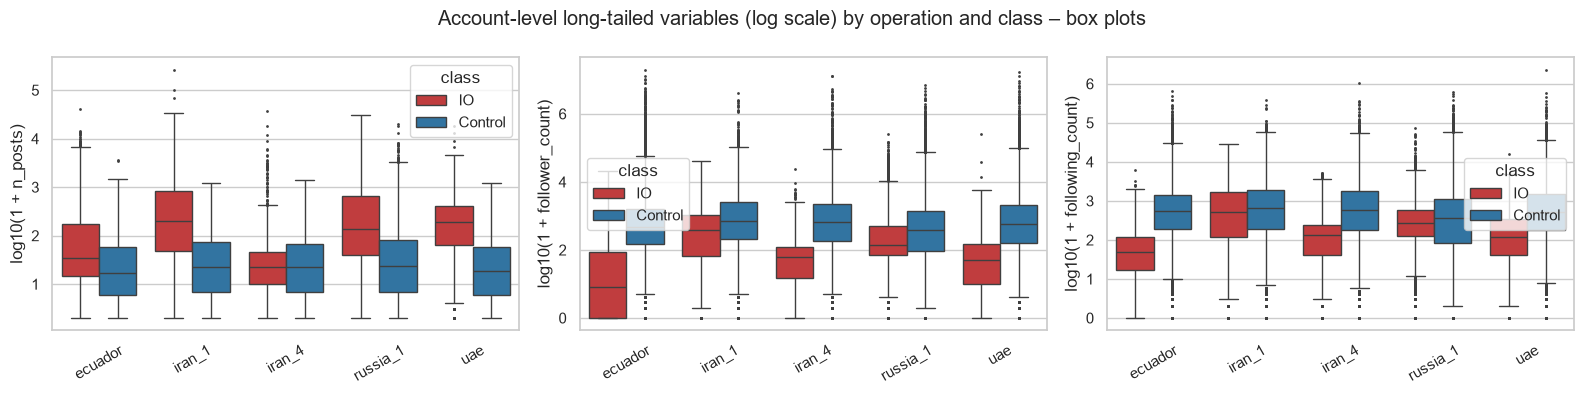

Most extreme accounts – n_posts:


,ioCountry,class,n_posts,follower_count,following_count,account_age_days,hashtags_per_post,mean_text_len
acc_key,,,,,,,,
16199581744105587512,iran_1,IO,265448,"8,012.0000","1,450.0000","1,294.4000",0.0000,63.4000
17870760626845196490,iran_1,IO,101956,"1,137.0000",219.0000,220.7000,0.0000,61.2000
9322395900981560685,iran_1,IO,68808,"14,365.0000","15,104.0000","1,303.2000",0.0000,47.6000


Most extreme accounts – follower_count:


,ioCountry,class,n_posts,follower_count,following_count,account_age_days,hashtags_per_post,mean_text_len
acc_key,,,,,,,,
17883533465797937889,ecuador,Control,42,"19,912,528.0000","1,069.0000","2,036.8000",0.4000,94.9000
257681911743916262,uae,Control,176,"16,864,374.0000",1.0000,"2,398.4000",2.9000,116.9000
3133872437748861692,iran_4,Control,99,"13,354,679.0000",573.0000,"2,797.6000",2.2000,68.5000


Most extreme accounts – following_count:


,ioCountry,class,n_posts,follower_count,following_count,account_age_days,hashtags_per_post,mean_text_len
acc_key,,,,,,,,
4148476509908245136,uae,Control,25,"2,092,714.0000","2,301,841.0000","1,579.6000",1.4000,135.5000
1892042965318783194,iran_4,Control,18,"1,136,836.0000","1,038,991.0000",880.8000,3.2000,102.6000
917701990553032903,ecuador,Control,198,"3,282,534.5000","657,857.5000","4,134.9000",1.3000,113.3000


Most extreme accounts – hashtags_per_post:


,ioCountry,class,n_posts,follower_count,following_count,account_age_days,hashtags_per_post,mean_text_len
acc_key,,,,,,,,
6911449776619384734,iran_4,Control,97,897.0000,"4,991.0000","1,330.0000",32.3000,272.2000
11262041474559553550,ecuador,Control,66,906.0000,"4,972.0000","1,299.5000",31.7000,266.1000
639816840937943702,ecuador,Control,7,"3,086.0000","5,000.0000","1,649.9000",29.7000,242.9000


Most extreme accounts – mean_text_len:


,ioCountry,class,n_posts,follower_count,following_count,account_age_days,hashtags_per_post,mean_text_len
acc_key,,,,,,,,
17062525569141107556,uae,Control,99,"2,684.0000","3,494.0000","2,194.6000",18.1000,361.8000
8811908429650299763,uae,Control,10,402.0000,587.0000,"2,754.0000",19.0000,345.8000
16007986770789708682,uae,Control,1,254.0000,774.0000,"2,548.0000",2.0000,314.0000


Accounts below the lower fence of account_age_days (posting in their first days): {'Control': 1925, 'IO': 947}
Accounts with 0 followers: {'Control': 1147, 'IO': 933}


In [16]:
g_acc = posts.groupby('acc_key')
acc = g_acc.agg(ioCountry=('ioCountry', 'first'), n_posts=('post_time', 'size'), follower_count=('follower_count', 'median'),
                following_count=('following_count', 'median'), is_control=('is_control', 'first'),
                account_creation_date=('account_creation_date', 'first'), hashtags_per_post=('n_hashtags', 'mean'),
                mean_text_len=('text_len', 'mean'), desc_len=('desc_len', 'first'))
acc['desc_len'] = acc['desc_len'].fillna(0)
acc['account_age_days'] = ((posts['post_time'] - posts['account_creation_date']).dt.total_seconds() / 86400
                           ).groupby(posts['acc_key']).median()
acc['class'] = pd.Categorical(np.where(acc['is_control'], 'Control', 'IO'), categories=CLASS_ORDER)
del g_acc


def iqr_bounds(x: pd.Series, log=True):
    """IQR fences [L, U] ([DP] p. 68), computed on log10(1+x) when log=True and returned in original units."""
    v = np.log10(1 + x) if log else x
    q1, q3 = v.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return (10 ** lo - 1, 10 ** hi - 1) if log else (lo, hi)


OUTLIER_VARS = [('text_len (post, written text)', posts['text_len'], posts['class']),
                ('n_hashtags (post)', posts['n_hashtags'], posts['class']),
                ('n_mentions (post)', posts['n_mentions'], posts['class']),
                ('n_urls (post)', posts['n_urls'], posts['class']),
                ('n_posts (account)', acc['n_posts'], acc['class']),
                ('follower_count (account)', acc['follower_count'], acc['class']),
                ('following_count (account)', acc['following_count'], acc['class']),
                ('account_age_days (account)', acc['account_age_days'], acc['class']),
                ('desc_len (account)', acc['desc_len'], acc['class']),
                ('hashtags_per_post (account)', acc['hashtags_per_post'], acc['class']),
                ('mean_text_len (account)', acc['mean_text_len'], acc['class'])]
rows = []
for name, s, cls in OUTLIER_VARS:
    ok = s.notna()
    s, cls = s[ok], cls[ok]
    lo, hi = iqr_bounds(s)
    low, high = s < lo, s > hi
    out = low | high
    rows.append({'variable': name, 'L': max(lo, 0), 'U': hi, 'max': s.max(), 'low outliers': int(low.sum()),
                 'high outliers': int(high.sum()), 'outliers %': 100 * out.mean(),
                 '% IO among the outliers': 100 * (cls[out] == 'IO').mean() if out.any() else np.nan,
                 '% IO among all units': 100 * (cls == 'IO').mean()})
outlier_tab = pd.DataFrame(rows).set_index('variable')
display(outlier_tab.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['n_posts', 'follower_count', 'following_count']):
    sns.boxplot(data=acc, x='ioCountry', y=np.log10(1 + acc[col]), hue='class', palette=CLASS_PALETTE,
                hue_order=CLASS_ORDER, ax=ax, fliersize=1)
    ax.set_ylabel(f'log10(1 + {col})')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
fig.suptitle('Account-level long-tailed variables (log scale) by operation and class – box plots')
plt.tight_layout()
plt.show()
show_cols = ['ioCountry', 'class', 'n_posts', 'follower_count', 'following_count', 'account_age_days',
             'hashtags_per_post', 'mean_text_len']
for col in ['n_posts', 'follower_count', 'following_count', 'hashtags_per_post', 'mean_text_len']:
    print(f'Most extreme accounts – {col}:')
    display(acc.nlargest(3, col)[show_cols].round(1))
print('Accounts below the lower fence of account_age_days (posting in their first days):',
      acc.loc[acc['account_age_days'] < outlier_tab.at['account_age_days (account)', 'L'], 'class'].value_counts().to_dict())
print('Accounts with 0 followers:', acc.loc[acc['follower_count'] == 0, 'class'].value_counts().to_dict())

**Where the outliers are, who they are, and what we do with them** (IQR fences on $\log_{10}(1+x)$, table above):

| Attribute | Outliers | Who | Most extreme cases | Decision |
|---|---|---|---|---|
| posts per account | 214 accounts above 3,596 posts (0.25%) | 89% IO | three `iran_1` IO accounts with 265,448, 101,956 and 68,808 posts | kept: hyper-activity is the phenomenon studied; activity is not a clustering input |
| followers | 2,080 accounts with 0 followers; 1,066 above 80k | 0 followers: 933 IO (8.5% of the IO accounts) and 1,147 control (1.5%); above 80k: almost all control | control accounts with 19.9M, 16.9M and 13.4M followers (media, public figures) | kept: real accounts; log and, for clustering, capping at L / U |
| following | 6,290 accounts following at most 2 accounts; 413 above 41k | 89% control | a UAE control account following 2.3M accounts | kept; log and capping |
| account age | 2,872 accounts posting within ≈10 days of their creation | 947 IO (33%, against 12.6% IO overall) | – | kept: brand-new accounts are a typical IO trait; log and capping |
| hashtags per post | 2,467 accounts above 5.8 per post | 99% control | control accounts with 30–32 hashtags per post (hashtag spam) | kept; log and capping |
| length of the written text (account mean) | 1,979 below 27 and 713 above 226 characters | 92% control | UAE control accounts with 314–362 characters on average | kept; log and capping |
| biography length | none | – | longest biography: 773 characters | – |
| written text (post) | 397,815 posts with fewer than 14 written characters (only links, mentions or emoji) and 226 above 374 | as in the whole data | longest written text: 1,030 characters | kept: real posts |
| hashtags / mentions / links (post) | 405,883 posts with 5 or more hashtags (68% control), 114,687 with 5 or more mentions, 564 with 5 or more links | – | up to 40 hashtags, 51 mentions, 9 links | kept |

* None of these values is impossible (the impossible counts, above 10^9, were already treated as invalid in 1.2.5),
  and posts longer than the platform limit are only 0.05% of the written texts. The outliers are therefore **kept**
  ("outliers are the goal of our analysis", [DU] p. 61): hyper-active accounts, accounts without followers and
  brand-new accounts are typical of information operations, while celebrities and hashtag spammers are part of the
  control population.
* IO accounts are over-represented among the outliers of activity, of missing audience and of account age; the outliers
  of audience, hashtags and text length are almost all control accounts.
* Their influence is controlled where it matters: the logarithmic scale for description (1.3.5) and, for clustering,
  the replacement of the values outside $[L, U]$ with $L$ or $U$ ([DP] p. 68, Section 2.1).

## 1.3 Distributions and descriptive statistics

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Bar chart for categorical attributes | [DU] p. 27 |
| Histograms, number of bins with Sturges' rule $k = 1 + \log_2 n$ | [DU] pp. 28–30 |
| Visualisation of temporal data (time series plot) | [DU] pp. 23–24 |
| Shape of distributions (skewness) | [DU] pp. 25–26 |
| Central tendency (mean, median, mode) and dispersion (std, quartiles, IQR, MAD) | [DU] pp. 31–33 |
| Box plot and conditional box plot | [DU] pp. 34, 37–38 |
| Entropy of a nominal attribute | [DU] p. 17; [SIM] pp. 20–22 |
| Logarithmic transformation for long tails | [DP] pp. 64–66 |

**Summary statistics of the cleaned data.** Numerical attributes are described with the measures of central
tendency and dispersion of [DU] pp. 31–33 (posts for the post attributes, accounts for the account attributes);
nominal attributes with their number of values, mode and entropy ([DU] p. 17).

In [17]:
posts['post_type'] = pd.Categorical(np.select([posts['is_repost'], posts['is_reply']], ['repost', 'reply'], 'original'),
                                    categories=['original', 'reply', 'repost'])


def describe_plus(df: pd.DataFrame) -> pd.DataFrame:
    """Central tendency and dispersion ([DU] pp. 31-33): mean, median, mode, std, five-number summary, IQR, MAD."""
    d = df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
    d['mode'] = df.mode().iloc[0]
    d['IQR'] = d['75%'] - d['25%']
    d['MAD'] = (df - df.median()).abs().median()
    return d


num_tab = pd.concat({
    'post': describe_plus(posts[['text_len', 'n_words', 'n_hashtags', 'n_urls', 'n_mentions']]),
    'account': describe_plus(acc[['n_posts', 'follower_count', 'following_count', 'account_age_days', 'desc_len']])})
display(num_tab.round(2))
cat_rows = []
for name, s in [('ioCountry', posts['ioCountry']), ('class (is_control)', posts['class']),
                ('post type (is_repost, replies)', posts['post_type']), ('post_language', posts['post_language']),
                ('application_name', posts['application_name'])]:
    vc = s.value_counts()
    vc = vc[vc > 0]
    cat_rows.append({'attribute': name, 'count': int(s.notna().sum()), 'distinct values': len(vc),
                     'mode': str(vc.index[0])[:14], 'mode share %': 100 * vc.iloc[0] / vc.sum(),
                     'entropy (bits)': entropy_bits(vc), 'maximum entropy log2(values)': np.log2(len(vc))})
display(pd.DataFrame(cat_rows).set_index('attribute').round(2))

count        mean          std    min      25%      50%        75%             max     mode        IQR      MAD
post    text_len         8,712,469.0000     80.8900      47.0700 0.0000  49.0000  75.0000   111.0000      1,030.0000 120.0000    62.0000  30.0000
        n_words          8,712,469.0000     12.7400       7.9700 0.0000   7.0000  11.0000    17.0000        131.0000   8.0000    10.0000   5.0000
        n_hashtags       8,712,472.0000      1.0700       1.8700 0.0000   0.0000   0.0000     1.0000         40.0000   0.0000     1.0000   0.0000
        n_urls           8,712,472.0000      0.6700       0.6300 0.0000   0.0000   1.0000     1.0000          9.0000   1.0000     1.0000   1.0000
        n_mentions       8,712,472.0000      0.8200       1.4200 0.0000   0.0000   1.0000     1.0000         51.0000   1.0000     1.0000   1.0000
account n_posts             86,525.0000    100.6900   1,123.5300 1.0000   6.0000  23.0000    84.0000    265,448.0000  99.0000    78.0000  20.0000
        follower_count      86,525.0000 10,162.6200 185,848.8700 0.0000  97.0000 385.0000 1,433.0000 19,912,528.0000   0.0000 1,336.0000 354.0000
        following_count     86,525.0000  1,811.8700  12,883.3300 0.0000 118.0000 406.0000 1,235.0000  2,301,841.0000   0.0000 1,117.0000 362.0000
        account_age_days    86,525.0000    972.4900     893.7000 0.0100 208.3200 721.5400 1,498.9700      4,493.4800 135.9900 1,290.6500 585.6900
        desc_len            86,525.0000     66.1600      62.8400 0.0000   6.0000  51.0000   114.0000        773.0000   0.0000   108.0000  51.0000

,count,distinct values,mode,mode share %,entropy (bits),maximum entropy log2(values)
attribute,,,,,,
ioCountry,8712472,5,russia_1,41.8900,2.0900,2.3200
class (is_control),8712472,2,IO,60.0300,0.9700,1.0000
"post type (is_repost, replies)",8712472,3,original,47.7300,1.3800,1.5800
post_language,8712472,71,en,28.6700,3.0600,6.1500
application_name,8712472,3728,62010408238d4a,26.9100,4.5000,11.8600


* **Post attributes.** The written text has 81 characters on average (median 75, at most 1,030) and 12.7 words; a post
  has on average 1.07 hashtags (median 0: more than half of the posts have none), 0.67 links and 0.82 mentions.
* **Account attributes.** Posts per account, followers and following are extremely skewed: the mean is far above the
  median (101 vs 23 posts, 10,163 vs 385 followers, 1,812 vs 406 following) and the maximum is thousands of times the
  third quartile – the long tails discussed in 1.3.5. The median account is about 2 years old when it posts (722 days);
  a quarter of the accounts have a biography of at most 6 characters (23% have none).
* **Nominal attributes.** Russia is the most frequent operation (42% of the posts), IO posts are 60% of the posts,
  original posts are the most frequent type (48%), English the most frequent of 71 language codes (29%). The publishing
  client has 3,728 values but an entropy of only 4.5 bits (maximum 11.9): a few clients account for most posts.

### 1.3.1 Volume and time

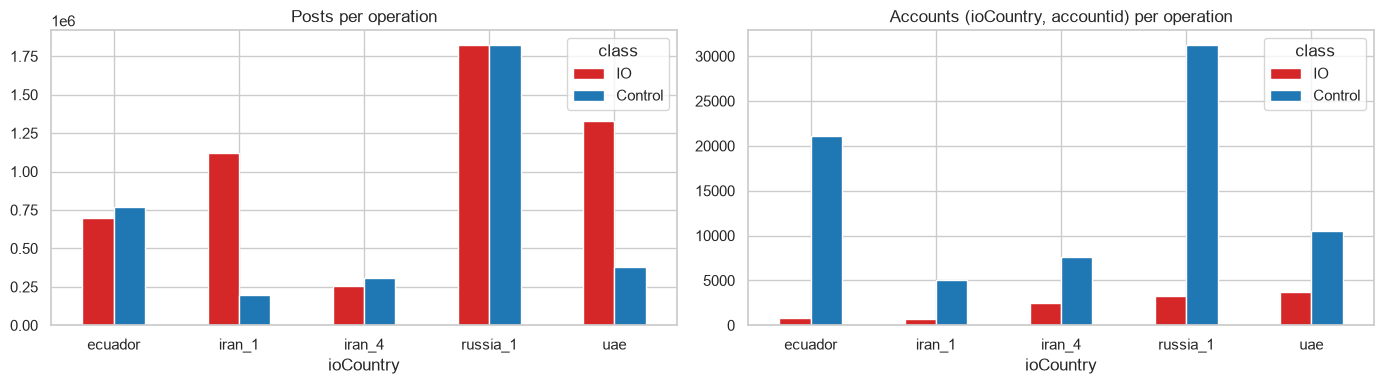

,count,mean,std,min,25%,50%,75%,90%,99%,max
class,,,,,,,,,,
IO,"10,917.0000",479.1000,"3,104.6000",1.0000,21.0000,88.0000,349.0000,"1,044.4000","5,434.4000","265,448.0000"
Control,"75,608.0000",46.1000,171.3000,1.0000,5.0000,20.0000,67.0000,99.0000,297.0000,"19,690.0000"


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
vol = posts.groupby(['ioCountry', 'class'], observed=True).size().unstack('class')[CLASS_ORDER]
vol.plot(kind='bar', ax=axes[0], color=[CLASS_PALETTE[c] for c in CLASS_ORDER], rot=0)
axes[0].set_title('Posts per operation')
accs = acc.groupby(['ioCountry', 'class'], observed=True).size().unstack('class')[CLASS_ORDER]
accs.plot(kind='bar', ax=axes[1], color=[CLASS_PALETTE[c] for c in CLASS_ORDER], rot=0)
axes[1].set_title('Accounts (ioCountry, accountid) per operation')
plt.tight_layout()
plt.show()
display(acc.groupby('class', observed=True)['n_posts'].describe(percentiles=[.25, .5, .75, .9, .99]).round(1))

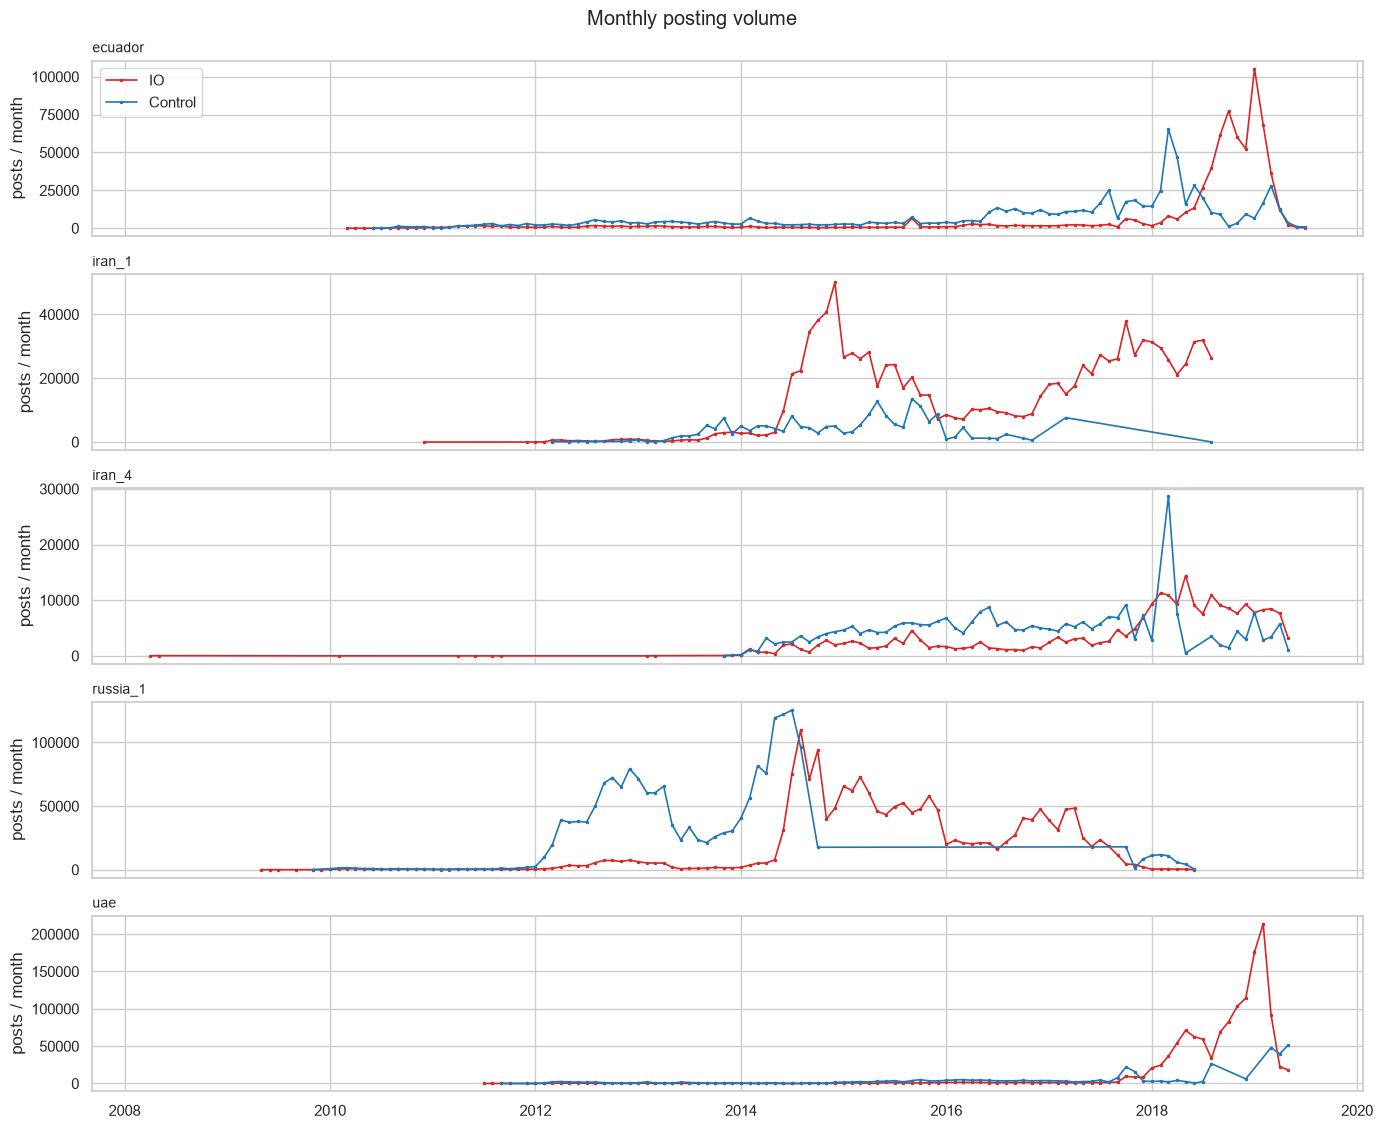

In [19]:
# Monthly number of posts of every operation (time series plot, [DU] pp. 23-24)
monthly = (posts.groupby(['ioCountry', 'class', posts['post_time'].dt.to_period('M')], observed=True)
           .size().rename('posts').reset_index())
monthly['post_time'] = monthly['post_time'].dt.to_timestamp()
ops = list(posts['ioCountry'].cat.categories)
fig, axes = plt.subplots(len(ops), 1, figsize=(14, 2.3 * len(ops)), sharex=True)
for ax, op in zip(axes, ops):
    for cls in CLASS_ORDER:
        m = monthly[(monthly['ioCountry'] == op) & (monthly['class'] == cls)]
        ax.plot(m['post_time'], m['posts'], color=CLASS_PALETTE[cls], label=cls, lw=1.2, marker='.', ms=3)
    ax.set_title(op, loc='left', fontsize=10)
    ax.set_ylabel('posts / month')
axes[0].legend(loc='upper left')
fig.suptitle('Monthly posting volume')
plt.tight_layout()
plt.show()
del monthly

IO activity is concentrated in specific periods (campaign peaks): Russia in 2014–2017, Iran_1 in 2014–2015 and
2017–2018, UAE and Ecuador with very sharp peaks in 2018–2019. Control posts cover days of the same windows
(1.2.6), but almost every control account (94.9%) contributes a single day.

### 1.3.2 Post type, language and publishing client

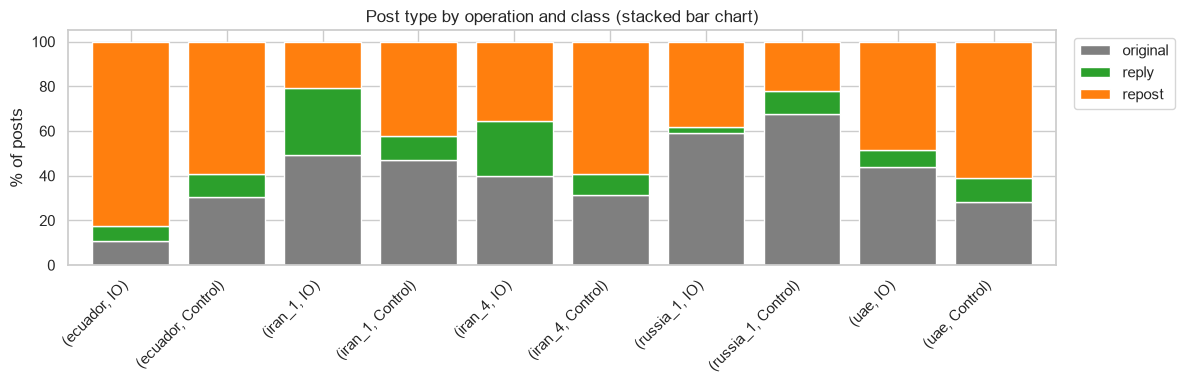

post_type          original   reply  repost
ioCountry class                            
ecuador   IO        10.9000  6.6000 82.5000
          Control   30.6000 10.1000 59.3000
iran_1    IO        49.1000 30.2000 20.7000
          Control   47.1000 10.8000 42.1000
iran_4    IO        39.9000 24.6000 35.5000
          Control   31.3000  9.7000 59.0000
russia_1  IO        59.1000  2.7000 38.2000
          Control   67.7000 10.0000 22.3000
uae       IO        43.9000  7.5000 48.6000
          Control   28.3000 10.6000 61.1000

In [20]:
ptype = posts.groupby(['ioCountry', 'class'], observed=True)['post_type'].value_counts(normalize=True).unstack()
ax = (ptype * 100).plot(kind='bar', stacked=True, figsize=(12, 4), color=['#7f7f7f', '#2ca02c', '#ff7f0e'], width=0.8)
ax.set_ylabel('% of posts')
ax.set_xlabel('')
ax.set_title('Post type by operation and class (stacked bar chart)')
ax.legend(bbox_to_anchor=(1.01, 1))
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
display((ptype * 100).round(1))

post_language          en      ru      ar      es      fr    und      fa     pt     tr  unknown
ioCountry class                                                                                
ecuador   IO       9.2000  0.7000  0.1000 79.7000  0.3000 3.1000  0.0000 0.4000 0.1000   3.9000
          Control 19.0000  0.1000  0.3000 65.2000  0.7000 6.6000  0.0000 3.2000 0.1000   0.0000
iran_1    IO      24.7000  3.6000 13.7000  5.8000 28.8000 3.8000  8.2000 0.1000 8.2000   0.5000
          Control 59.3000  0.9000  4.9000 18.4000  2.6000 4.9000  0.4000 1.1000 1.1000   0.0000
iran_4    IO      12.7000  0.0000 11.6000  0.0000  0.1000 5.8000 68.9000 0.0000 0.4000   0.0000
          Control 44.0000  0.1000 34.7000  5.4000  1.0000 5.1000  5.2000 0.5000 0.5000   0.0000
russia_1  IO      32.6000 57.0000  0.4000  0.1000  0.1000 2.4000  0.0000 0.0000 0.0000   3.6000
          Control 44.1000 25.1000  2.2000  6.9000  2.2000 4.6000  0.0000 4.7000 0.3000   0.0000
uae       IO      17.0000  1.7000 60.5000  3.3000  2.6000 5.2000  2.4000 0.8000 1.9000   0.3000
          Control 25.9000  0.1000 59.2000  2.2000  0.7000 5.3000  0.4000 1.3000 0.4000   0.0000

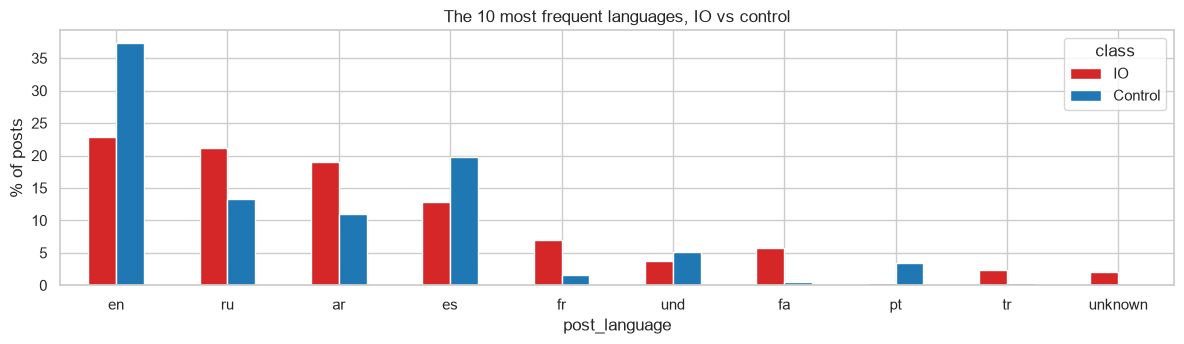

In [21]:
# Language: share of the most frequent languages in every operation x class group (table) + bar chart
top_lang = posts['post_language'].value_counts().head(10).index
lang_share = (posts.groupby(['ioCountry', 'class'], observed=True)['post_language'].value_counts(normalize=True)
              .unstack('post_language')[top_lang] * 100)
display(lang_share.round(1))
lang_cls = (posts.groupby('class', observed=True)['post_language'].value_counts(normalize=True)
            .unstack('post_language')[top_lang] * 100)
ax = lang_cls.T.plot(kind='bar', figsize=(12, 3.6), color=[CLASS_PALETTE[c] for c in lang_cls.index], rot=0)
ax.set_ylabel('% of posts')
ax.set_title('The 10 most frequent languages, IO vs control')
plt.tight_layout()
plt.show()

In [22]:
# Publishing client (anonymised): concentration of the distribution and its entropy ([SIM] pp. 20-22)
app_stats = []
for (op, cls), grp_ in posts.groupby(['ioCountry', 'class'], observed=True):
    vc = grp_['application_name'].value_counts()
    vc = vc[vc > 0]
    app_stats.append({'ioCountry': op, 'class': cls, 'distinct apps': len(vc),
                      'top-1 app share %': 100 * vc.iloc[0] / vc.sum(),
                      'top-3 apps share %': 100 * vc.iloc[:3].sum() / vc.sum(), 'entropy (bits)': entropy_bits(vc)})
display(pd.DataFrame(app_stats).set_index(['ioCountry', 'class']).round(2))

distinct apps  top-1 app share %  top-3 apps share %  entropy (bits)
ioCountry class                                                                        
ecuador   IO                  73            31.0700             90.3900          2.1800
          Control            759            39.0800             73.2300          3.5000
iran_1    IO                 124            62.2800             77.8800          2.2400
          Control            462            22.1900             52.6600          4.6600
iran_4    IO                  42            53.9500             94.5400          1.7700
          Control            460            28.4400             70.4300          3.7200
russia_1  IO                 257            28.7000             52.3400          4.0100
          Control           2343            18.7000             39.0700          5.4900
uae       IO                  71            35.8500             81.7600          2.4400
          Control            552            33.6500             76.2200          3.4300

* **Post type.** The IO–control difference changes direction across operations: Ecuador IO accounts mostly repost,
  Russian IO accounts mostly publish original content and almost never reply, Iranian IO accounts reply much more
  than their controls.
* **Language** follows the audience of each operation (Spanish in Ecuador, Arabic in UAE, Persian in Iran_4,
  Russian/English in Russia); Iran_1 IO accounts are strongly multilingual (French, English, Arabic, Turkish).
* **Clients.** In every operation IO posts use far fewer distinct applications, more concentrated on the top ones
  (lower entropy), consistent with centrally managed accounts using the same tools.

### 1.3.3 Content descriptors and descriptive statistics

count    mean     std    min     25%     50%      75%      max     mode     IQR     MAD
IO      text_len   601,005.0000 77.7600 43.1700 0.0000 48.0000 72.0000 109.0000 786.0000 120.0000 61.0000 29.0000
        n_words    601,005.0000 12.2800  7.3300 0.0000  7.0000 11.0000  17.0000  70.0000   8.0000 10.0000  4.0000
        n_hashtags 601,005.0000  0.7300  1.3900 0.0000  0.0000  0.0000   1.0000  28.0000   0.0000  1.0000  0.0000
        n_urls     601,005.0000  0.6600  0.6500 0.0000  0.0000  1.0000   1.0000   6.0000   1.0000  1.0000  1.0000
        n_mentions 601,005.0000  0.7600  0.9500 0.0000  0.0000  1.0000   1.0000  50.0000   1.0000  1.0000  1.0000
Control text_len   398,995.0000 85.7300 52.1900 0.0000 50.0000 81.0000 112.0000 867.0000 115.0000 62.0000 31.0000
        n_words    398,995.0000 13.4600  8.8000 0.0000  8.0000 12.0000  17.0000  75.0000  11.0000  9.0000  5.0000
        n_hashtags 398,995.0000  1.6000  2.3200 0.0000  0.0000  1.0000   2.0000  34.0000   0.0000  2.0000  1.0000
        n_urls     398,995.0000  0.6900  0.6000 0.0000  0.0000  1.0000   1.0000   8.0000   1.0000  1.0000  0.0000
        n_mentions 398,995.0000  0.9100  1.9100 0.0000  0.0000  1.0000   1.0000  51.0000   0.0000  1.0000  1.0000

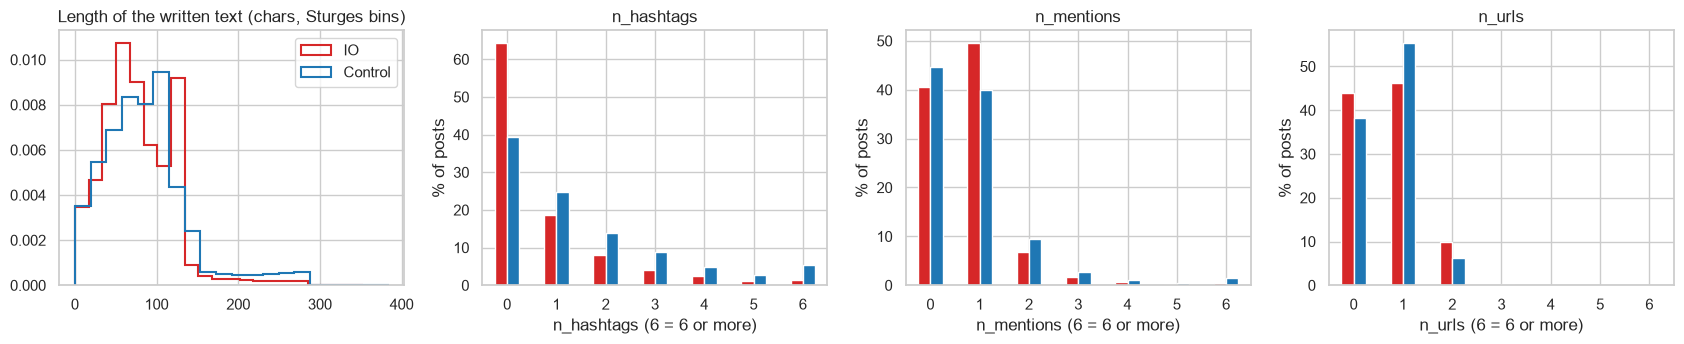

In [23]:
num_post_cols = ['text_len', 'n_words', 'n_hashtags', 'n_urls', 'n_mentions']
sample_posts = posts.sample(1_000_000, random_state=RANDOM_STATE)
desc = pd.concat({cls: describe_plus(sample_posts.loc[sample_posts['class'] == cls, num_post_cols])
                  for cls in CLASS_ORDER})
display(desc.round(2))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for cls in CLASS_ORDER:
    v = sample_posts.loc[(sample_posts['class'] == cls) & (sample_posts['text_len'] <= 400), 'text_len']
    axes[0].hist(v, bins=sturges_bins(len(v)), density=True, histtype='step', lw=1.5, color=CLASS_PALETTE[cls],
                 label=cls)
axes[0].set_title('Length of the written text (chars, Sturges bins)')
axes[0].legend()
for ax, col in zip(axes[1:], ['n_hashtags', 'n_mentions', 'n_urls']):
    share = (sample_posts.assign(v=sample_posts[col].clip(upper=6)).groupby('class', observed=True)['v']
             .value_counts(normalize=True).unstack('class')[CLASS_ORDER] * 100)
    share.plot(kind='bar', ax=ax, color=[CLASS_PALETTE[c] for c in CLASS_ORDER], rot=0, legend=False)
    ax.set_xlabel(f'{col} (6 = 6 or more)')
    ax.set_ylabel('% of posts')
    ax.set_title(col)
plt.tight_layout()
plt.show()

IO posts contain fewer hashtags than control posts (64% of the IO posts have none, against 39%; mean 0.73 vs 1.60);
mentions and links are similar (one mention or one link in about half of the posts). Once the anonymised mentions and
links are removed, the length of the written text is also similar in the two classes (median 72 vs 81 characters,
almost always below the 280-character limit) and positively skewed ([DU] pp. 25–26): mean > median.

### 1.3.4 Account-level attributes

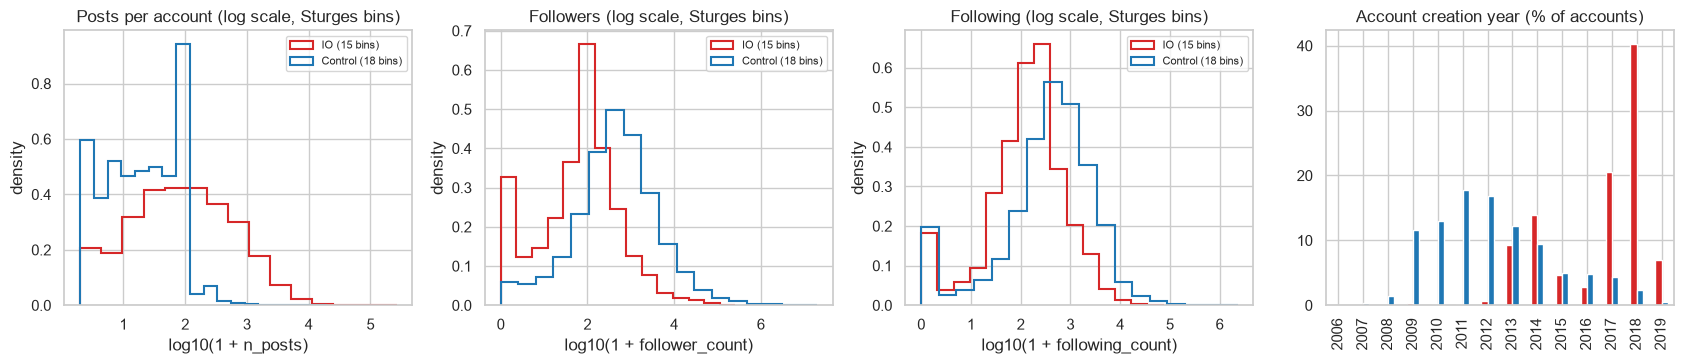

Sturges bins: IO accounts n = 10917 -> 15 | control accounts n = 75608 -> 18


,median n_posts,median follower_count,median following_count
class,,,
IO,88.0000,85.0000,157.0000
Control,20.0000,477.0000,474.0000


Share of accounts with exactly 1 post: {'IO': 3.3, 'Control': 7.5} | with 0 followers: {'IO': 8.5, 'Control': 1.5} | created in 2017-2018: {'IO': 60.9, 'Control': 6.7}


In [24]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, col, title in zip(axes, ['n_posts', 'follower_count', 'following_count'],
                          ['Posts per account', 'Followers', 'Following']):
    for cls in CLASS_ORDER:
        v = np.log10(1 + acc.loc[acc['class'] == cls, col])
        ax.hist(v, bins=sturges_bins(len(v)), density=True, histtype='step', lw=1.5, color=CLASS_PALETTE[cls],
                label=f'{cls} ({sturges_bins(len(v))} bins)')
    ax.set_xlabel(f'log10(1 + {col})')
    ax.set_ylabel('density')
    ax.set_title(f'{title} (log scale, Sturges bins)')
    ax.legend(fontsize=8)
acc['creation_year'] = acc['account_creation_date'].dt.year
cy = acc.groupby('class', observed=True)['creation_year'].value_counts(normalize=True).unstack('class')[CLASS_ORDER]
(cy * 100).plot(kind='bar', ax=axes[3], color=[CLASS_PALETTE[c] for c in CLASS_ORDER], legend=False)
axes[3].set_title('Account creation year (% of accounts)')
axes[3].set_xlabel('')
plt.tight_layout()
plt.show()
print('Sturges bins: IO accounts n =', (acc['class'] == 'IO').sum(), '->', sturges_bins((acc['class'] == 'IO').sum()),
      '| control accounts n =', (acc['class'] == 'Control').sum(), '->', sturges_bins((acc['class'] == 'Control').sum()))
display(acc.groupby('class', observed=True)[['n_posts', 'follower_count', 'following_count']].median()
        .rename(columns=lambda c: f'median {c}'))
print('Share of accounts with exactly 1 post:', (acc['n_posts'] == 1).groupby(acc['class'], observed=True).mean()
      .mul(100).round(1).to_dict(), '| with 0 followers:', (acc['follower_count'] == 0).groupby(acc['class'], observed=True)
      .mean().mul(100).round(1).to_dict(), '| created in 2017-2018:', acc['creation_year'].isin([2017, 2018])
      .groupby(acc['class'], observed=True).mean().mul(100).round(1).to_dict())

**How to read the four plots.** The first three panels are histograms of the number of posts, of followers and of
followed accounts of every account, on a logarithmic scale ($\log_{10}(1+x)$: 1 means 9, 2 means 99, 3 means 999), one
line per class. The y axis is a *density* (the area under each line is 1), so the 10,917 IO and the 75,608 control
accounts can be compared even though the classes have very different sizes. The fourth panel is a bar chart of the
creation year of the accounts.

**Sturges' rule** ([DU] p. 30) sets the number of bins of a histogram to $k = 1 + \log_2 n$, where $n$ is the number of
values: $1 + \log_2 10{,}917 = 14.4$ → 15 bins for the IO accounts and $1 + \log_2 75{,}608 = 17.2$ → 18 bins for the
control accounts. Too few bins hide the shape of a distribution and too many make every bin noisy (the slides show the
same data with 5, 17 and 200 bins, [DU] p. 29); Sturges' rule replaces an arbitrary choice with a rule that depends only
on the amount of data. The slides note that it suits roughly bell-shaped distributions of moderate size, which is why it
is applied to the log-transformed values and not to the raw counts.

**What the plots say.**

* *Posts per account.* The control curve has a spike at $\log_{10}(1+x) \approx 2$ – about 99 posts, the cap of the
  control collection (1.2.6) – and many accounts with a single post (7.5% of the controls, 3.3% of the IO accounts);
  the IO curve extends up to $10^5$ posts. The difference in volume reflects the sampling design, not behaviour.
* *Followers and following.* The IO curves are shifted to the left: median 85 followers against 477, 157 followed
  accounts against 474, and a spike at 0 – 8.5% of the IO accounts have no follower at all (1.5% of the controls).
* *Creation year.* 61% of the IO accounts were created in 2017–2018 (40% in 2018 alone), with an earlier wave in
  2013–2014, while control accounts are spread over 2009–2016 (7% created in 2017–2018): IO accounts were created in
  batches for the campaigns.

### 1.3.5 Long-tailed attributes and the logarithmic scale

A distribution has a **long (right) tail** when most values are small but a few are larger by orders of magnitude
– a strongly positively skewed distribution, like income in [DU] p. 26. Followers are the textbook case: a typical
account has a few hundred followers, a few accounts have millions. On a linear scale this causes three problems:
(i) the **mean is pulled far above the median** and no longer describes a typical account; (ii) histograms and box
plots squeeze almost all the accounts into the first bin or below the box, while the axis is stretched by a few
values; (iii) in a Euclidean distance the few extreme accounts dominate every comparison.

The **logarithmic transformation** ([DP] pp. 64–66) solves the three problems at once: $\log_{10}$ turns ratios into
differences ($10 \to 1$, $100 \to 2$, $1000 \to 3$), so the gap between 100 and 1,000 followers is the same as the
gap between 1,000 and 10,000 – what matters for a count is "how many times more", not the absolute difference. It
compresses the tail and spreads the bulk of the data (the slides' example: gains between 5 and 11,000 become values
between 0.7 and 4). The logarithm of 0 is not defined, and many counts are 0 (accounts without followers, posts
without hashtags), so we use $\log_{10}(1 + x)$ (*log1p*): 0 stays 0, and for large values the added 1 is
negligible ($\log_{10}(1001) \approx 3$).

Which attributes are long-tailed? We use two simple descriptive criteria: the **mean is above the median** and the
**maximum is at least 10 times the third quartile** (the tail reaches at least one order of magnitude beyond the
bulk of the data).

,median,mean,Q3,P99,max,mean / median,max / Q3,% zeros,long tail
attribute,,,,,,,,,
n_posts (account),23.0000,100.6900,84.0000,"1,386.0000","265,448.0000",4.3800,"3,160.1000",0.0000,True
follower_count (account),385.0000,"10,162.6200","1,433.0000","101,509.7600","19,912,528.0000",26.4000,"13,895.6900",2.4000,True
following_count (account),406.0000,"1,811.8700","1,235.0000","21,653.4800","2,301,841.0000",4.4600,"1,863.8400",6.3300,True
hashtags_per_post (account),0.9200,1.3800,1.6700,9.0000,32.2700,1.5000,19.3600,0.8800,True
mean_text_len (account),81.2900,86.6700,103.0300,219.0000,361.8300,1.0700,3.5100,0.0300,False
account_age_days (account),721.5400,972.4900,"1,498.9700","3,347.7600","4,493.4800",1.3500,3.0000,0.0000,False
desc_len (account),51.0000,66.1600,114.0000,233.0000,773.0000,1.3000,6.7800,23.1400,False
text_len (post),75.0000,80.8900,111.0000,257.0000,"1,030.0000",1.0800,9.2800,1.2400,False
n_hashtags (post),0.0000,1.0700,1.0000,9.0000,40.0000,NaN,40.0000,54.4300,True


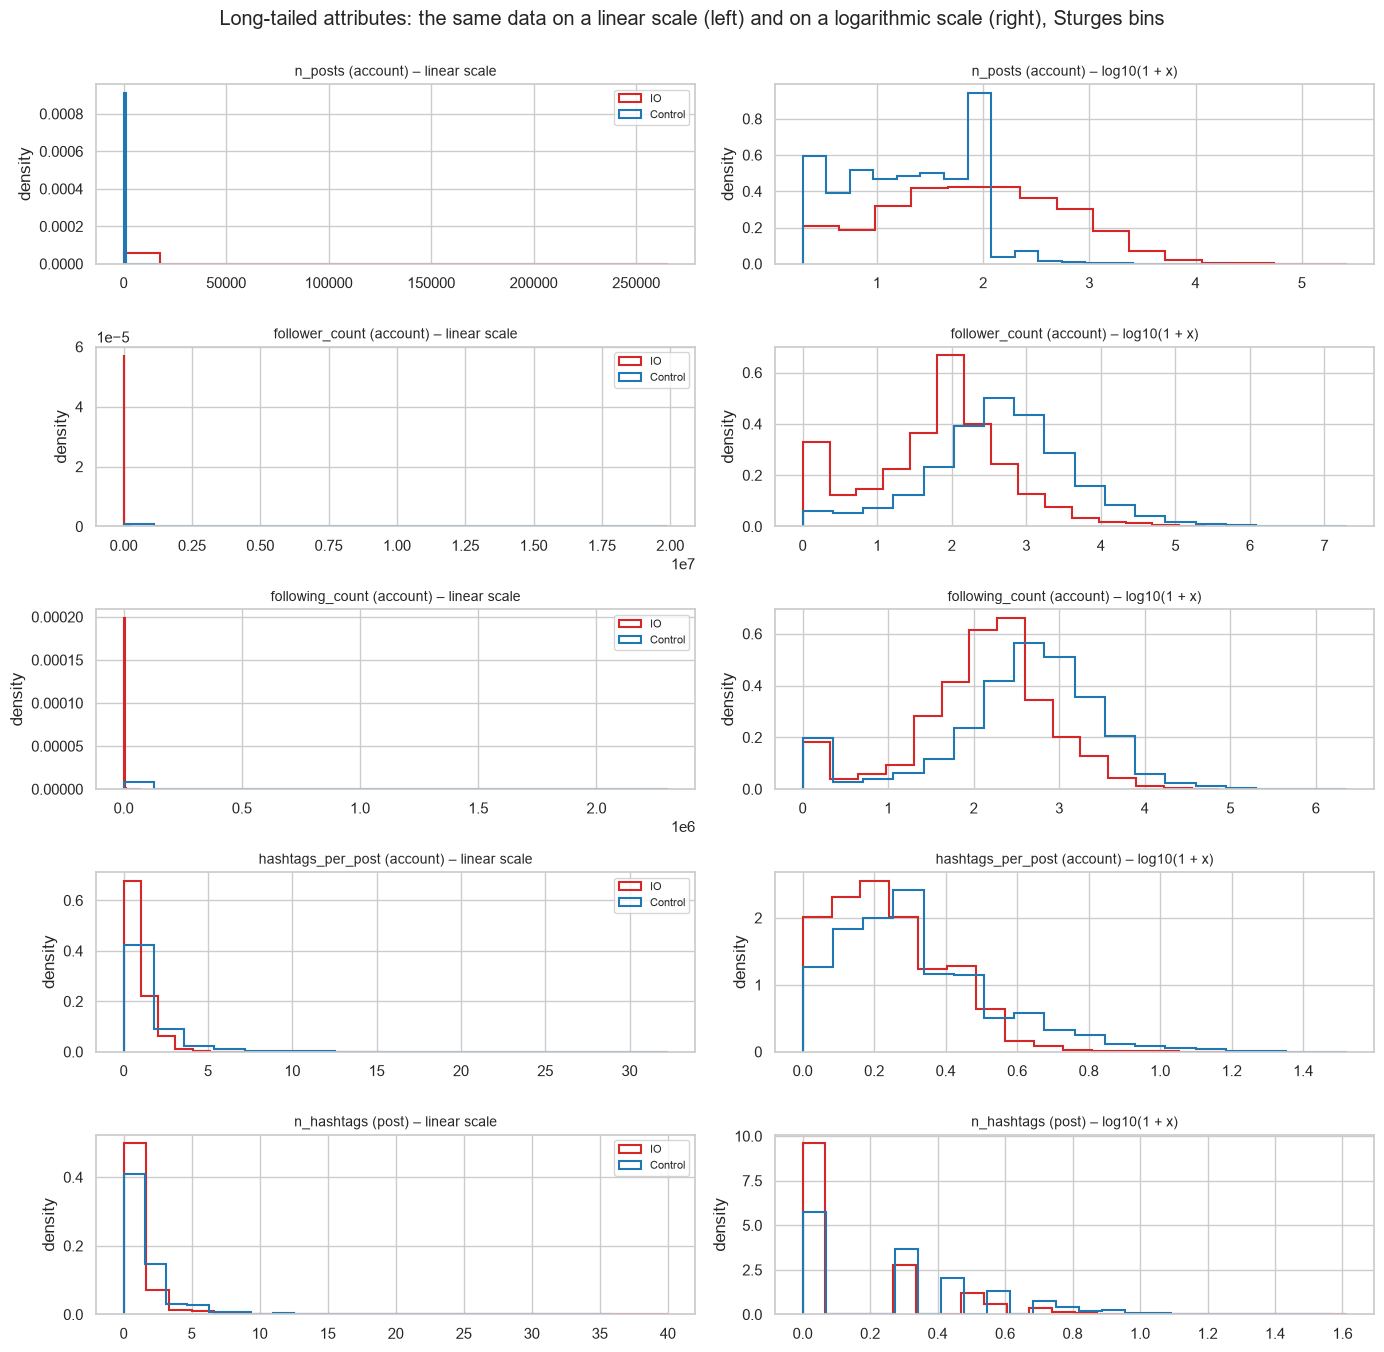

In [25]:
LT_CANDIDATES = {
    'n_posts (account)': acc['n_posts'], 'follower_count (account)': acc['follower_count'],
    'following_count (account)': acc['following_count'], 'hashtags_per_post (account)': acc['hashtags_per_post'],
    'mean_text_len (account)': acc['mean_text_len'], 'account_age_days (account)': acc['account_age_days'],
    'desc_len (account)': acc['desc_len'], 'text_len (post)': posts['text_len'], 'n_hashtags (post)': posts['n_hashtags'],
    'n_mentions (post)': posts['n_mentions'], 'n_urls (post)': posts['n_urls']}
lt_rows = []
for name, s in LT_CANDIDATES.items():
    s = s.dropna()
    q1, med, q3, p99 = s.quantile([.25, .5, .75, .99])
    lt_rows.append({'attribute': name, 'median': med, 'mean': s.mean(), 'Q3': q3, 'P99': p99, 'max': s.max(),
                    'mean / median': s.mean() / med if med > 0 else np.nan,
                    'max / Q3': s.max() / q3 if q3 > 0 else np.inf, '% zeros': 100 * (s == 0).mean()})
lt = pd.DataFrame(lt_rows).set_index('attribute')
lt['long tail'] = (lt['max / Q3'] >= 10) & (lt['mean'] > lt['median'])
display(lt.round(2))

long_tailed = list(lt.index[lt['long tail']])
fig, axes = plt.subplots(len(long_tailed), 2, figsize=(14, 2.7 * len(long_tailed)))
for row, name in zip(axes, long_tailed):
    s_all = LT_CANDIDATES[name]
    cls_all = (acc['class'] if '(account)' in name else posts['class']).loc[s_all.index]
    for cls in CLASS_ORDER:
        v = s_all[(cls_all == cls) & s_all.notna()]
        k = sturges_bins(len(v))
        row[0].hist(v, bins=k, density=True, histtype='step', lw=1.5, color=CLASS_PALETTE[cls], label=cls)
        row[1].hist(np.log10(1 + v), bins=k, density=True, histtype='step', lw=1.5, color=CLASS_PALETTE[cls], label=cls)
    row[0].set_title(f'{name} – linear scale', fontsize=10)
    row[1].set_title(f'{name} – log10(1 + x)', fontsize=10)
    row[0].legend(fontsize=8)
    for ax in row:
        ax.set_ylabel('density')
fig.suptitle('Long-tailed attributes: the same data on a linear scale (left) and on a logarithmic scale (right), '
             'Sturges bins', y=1.0)
plt.tight_layout()
plt.show()

* By the two criteria, the **long-tailed attributes** are the number of posts per account (maximum 3,160 times the third
  quartile), the followers (13,896 times; mean 26 times the median), the followed accounts (1,864 times), the hashtags per
  post of an account (19 times) and the hashtags of a post (40 times). The left column shows the problem: on a linear
  scale almost all the accounts fall into the first bin, and the axis is stretched to 265k posts or 20M followers by a
  handful of accounts. On the log scale (right column) the same data become readable, roughly bell-shaped distributions,
  and the IO–control differences appear: IO accounts have more posts, fewer followers and followed accounts, and a group
  with no follower at all.
* The length of the written text, the account age and the biography length are **not** long-tailed (maximum at most
  3.5–9 times the third quartile, mean close to the median); mentions and links per post are short counts with many
  zeros (at most 51 and 9). For them the logarithm is not needed to tame a tail; where it is used in Task 2 the reason
  is different and is shown in 2.1.
* This is why the box plots and histograms of counts in this notebook use the log scale, and why followers, following
  and hashtags enter the clustering as $\log_{10}(1+x)$.

## 1.4 Correlations and redundancies

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Covariance and Pearson's correlation coefficient | [DU] pp. 49–56; [SIM] p. 17 |
| Spearman's rank correlation | [DU] p. 59 |
| Visualisation of a correlation matrix | [DU] p. 60 |
| Scatter plot | [DU] pp. 39–42 |
| Contingency table and χ² test for nominal attributes | [DU] p. 17 |
| Mutual information between nominal attributes | [SIM] pp. 23–24 |
| Redundant features | [DP] pp. 14, 17–18 |

### 1.4.1 Numerical attributes (post level)

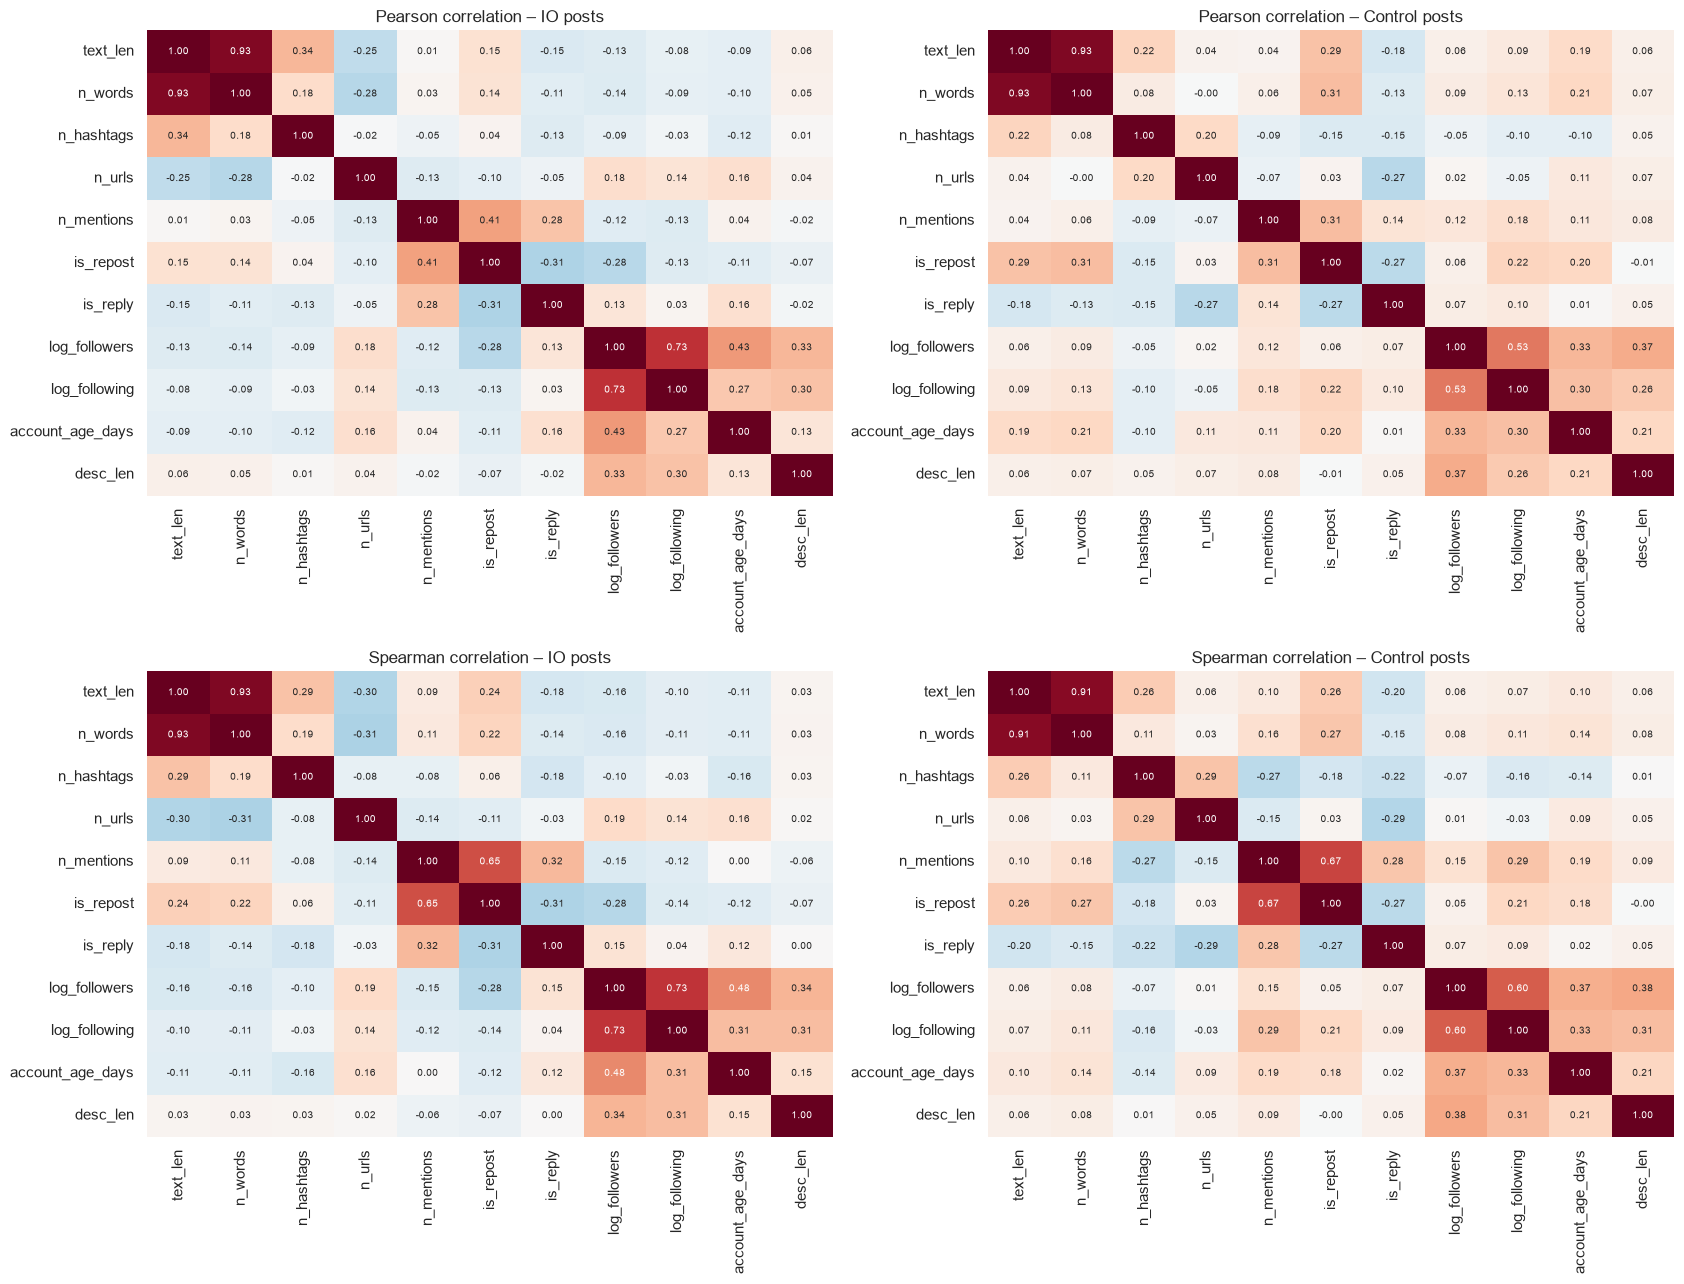

In [26]:
corr_df = sample_posts.assign(
    is_repost=sample_posts['is_repost'].astype(int), is_reply=sample_posts['is_reply'].astype(int),
    log_followers=np.log10(1 + sample_posts['follower_count']),
    log_following=np.log10(1 + sample_posts['following_count']),
    account_age_days=(sample_posts['post_time'] - sample_posts['account_creation_date']).dt.days,
    desc_len=sample_posts['desc_len'].fillna(0))
corr_cols = ['text_len', 'n_words', 'n_hashtags', 'n_urls', 'n_mentions', 'is_repost', 'is_reply',
             'log_followers', 'log_following', 'account_age_days', 'desc_len']
fig, axes = plt.subplots(2, 2, figsize=(17, 13))
for i, method in enumerate(['pearson', 'spearman']):
    for j, cls in enumerate(CLASS_ORDER):
        cm = corr_df.loc[corr_df['class'] == cls, corr_cols].corr(method=method)
        sns.heatmap(cm, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=axes[i, j], cbar=False,
                    annot_kws={'size': 7})
        axes[i, j].set_title(f'{method.capitalize()} correlation – {cls} posts')
plt.tight_layout()
plt.show()

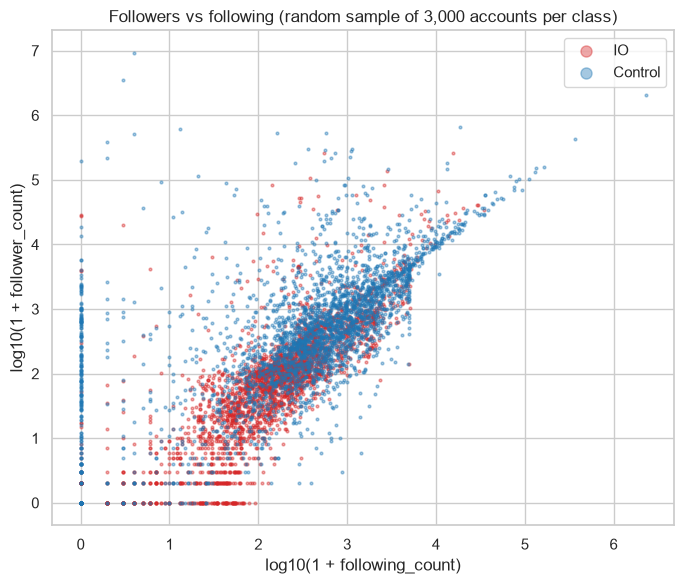

IO: Pearson (log-log) = 0.83 | Spearman = 0.85
Control: Pearson (log-log) = 0.61 | Spearman = 0.67


In [27]:
# Scatter plot (log-log) of followers vs following for a random sample of accounts of each class
sc_sample = acc.groupby('class', observed=True).sample(3000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(7, 6))
for cls in CLASS_ORDER:
    s = sc_sample[sc_sample['class'] == cls]
    ax.scatter(np.log10(1 + s['following_count']), np.log10(1 + s['follower_count']), s=4, alpha=0.4,
               color=CLASS_PALETTE[cls], label=cls)
ax.set_xlabel('log10(1 + following_count)')
ax.set_ylabel('log10(1 + follower_count)')
ax.legend(markerscale=4)
ax.set_title('Followers vs following (random sample of 3,000 accounts per class)')
plt.tight_layout()
plt.show()
for cls in CLASS_ORDER:
    a = acc[acc['class'] == cls]
    print(f'{cls}: Pearson (log-log) = {np.corrcoef(np.log10(1 + a["following_count"]), np.log10(1 + a["follower_count"]))[0, 1]:.2f}'
          f' | Spearman = {stats.spearmanr(a["following_count"], a["follower_count"]).statistic:.2f}')

### 1.4.2 Nominal attributes: contingency tables, χ² test and mutual information

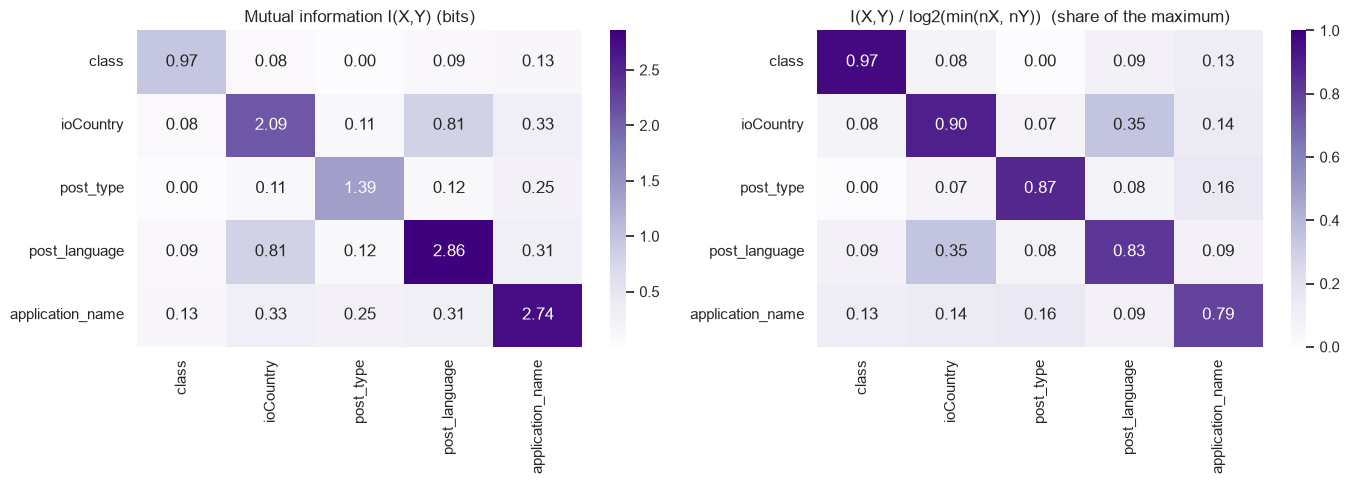

Contingency table class x post_type (sample of 300k posts):


post_type,original,reply,repost
class,,,
IO,82080,20663,77452
Control,60601,12292,46912


chi2 = 733, dof = 2, p-value = 8.14e-160


In [28]:
cs = sample_posts.sample(300_000, random_state=RANDOM_STATE)
cat_vars = {'class': cs['class'].astype(str), 'ioCountry': cs['ioCountry'].astype(str),
            'post_type': cs['post_type'].astype(str),
            'post_language': cs['post_language'].astype(str).where(cs['post_language'].isin(top_lang), 'other'),
            'application_name': cs['application_name'].astype(str).where(
                cs['application_name'].isin(posts['application_name'].value_counts().head(10).index), 'other')}
mi = pd.DataFrame(index=cat_vars, columns=cat_vars, dtype=float)
for a in cat_vars:
    for b in cat_vars:
        mi.loc[a, b] = mutual_information_bits(cat_vars[a], cat_vars[b])
mi_rel = mi.copy()
for a in cat_vars:
    for b in cat_vars:  # maximum possible value: log2(min(nX, nY)), [SIM] p. 23
        mi_rel.loc[a, b] = mi.loc[a, b] / np.log2(min(cat_vars[a].nunique(), cat_vars[b].nunique()))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(mi, annot=True, fmt='.2f', cmap='Purples', ax=axes[0])
axes[0].set_title('Mutual information I(X,Y) (bits)')
sns.heatmap(mi_rel, annot=True, fmt='.2f', cmap='Purples', vmin=0, vmax=1, ax=axes[1])
axes[1].set_title('I(X,Y) / log2(min(nX, nY))  (share of the maximum)')
plt.tight_layout()
plt.show()

ct = pd.crosstab(cs['class'], cs['post_type'])
chi2, pval, dof, _ = stats.chi2_contingency(ct)
print('Contingency table class x post_type (sample of 300k posts):')
display(ct)
print(f'chi2 = {chi2:,.0f}, dof = {dof}, p-value = {pval:.2e}')
del corr_df, cs, cat_vars
_ = gc.collect()

**Redundancies found** (and how they are handled):

* `text_len` and `n_words` (length of the written text in characters and in words) are strongly correlated (Pearson
  and Spearman ≈ 0.91–0.93) → only the text length is used.
* `n_mentions` is strongly correlated with `is_repost` (Spearman ≈ 0.65–0.67): a repost always mentions the original
  author.
* `log_followers` and `log_following` are correlated (0.53–0.73 at post level; at account level 0.61 for control and
  0.83 for IO accounts, Pearson on the log scale) but not redundant: their balance is informative.
* Repost identifiers are fully determined by `is_repost`; reply identifiers carry the same information as `is_reply`;
  account attributes repeated on every post are moved to the profile.
* Among nominal attributes, `post_language` shares a lot of information with the operation, and
  `application_name` is the attribute most informative about the class. The post type is almost independent of
  the class **globally** (very low mutual information), although it differs a lot within each operation (1.3.2):
  differences in opposite directions cancel out when operations are pooled, so comparisons must be made per
  operation. With 300k posts every χ² test is significant, so the strength of the dependence (mutual
  information) is more informative than the p-value.

## 1.5 User profiling and feature engineering

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Aggregation of objects (posts → accounts) | [DP] p. 4 |
| Feature creation / construction | [DP] pp. 20–22 |
| Entropy of a nominal attribute for sample data | [SIM] pp. 20–22; [DU] p. 17 |
| Mean and standard deviation (burstiness), median, quartiles, IQR | [DU] pp. 31–34 |
| Selection of records (minimum number of posts) | [DP] p. 2 |
| Conditional box plots, histograms | [DU] pp. 28–30, 34, 37 |
| Spearman correlation matrix and redundant features | [DU] pp. 59–60; [DP] pp. 14, 17–18 |
| Scatter matrix | [DU] p. 41 |
| Radar plot, min-max normalisation | [DU] p. 47; [DP] p. 47 |

Starting from the cleaned post-level table we build **one profile per account**, identified by the composite key
**(ioCountry, accountid)** (user–country granularity, [Q&A Q9]). Following [Q&A Q10], we prefer a limited number of
indicators with a clear behavioural meaning (each with its formula) to many mechanical statistics such as the mean and
standard deviation of every attribute. For an account $u$ let $P_u$ be its posts, $N_u = |P_u|$, $c(u)$ its operation and
$\mathbb{1}[\cdot]$ the indicator function. Entropies use $H(X) = -\sum_x p_x \log_2 p_x$, where $p_x$ is the share
of the account's posts with value $x$ ([SIM] p. 22).

**A. Activity and time** (reliable timestamps, but **not comparable** between IO and control because of the
day-bounded control sample, 1.2.6)

| Feature | What it captures | Formula |
|---|---|---|
| `n_posts` | volume of activity | $N_u$ |
| `rel_activity` | activity compared with the typical account of the same operation (unusually active accounts) | $\log_{10}\big(N_u / \operatorname{median}_{v: c(v)=c(u)} N_v\big)$ |
| `active_days` | number of distinct days with at least one post | $\lvert\{\text{day}(p) : p \in P_u\}\rvert$ |
| `lifespan_days` | observed activity period | $\max_p t_p - \min_p t_p$ (days) |
| `posts_per_active_day` | posting intensity on active days | $N_u / \text{active\_days}$ |
| `max_day_share` | temporal concentration: share of posts on the most active day | $\max_d n_{u,d} / N_u$ |
| `max_week_share` | the same on a weekly basis | $\max_w n_{u,w} / N_u$ |
| `hour_entropy` | regularity of the daily rhythm (0 = always the same hour, 1 = uniform over 24 hours) | $H(\text{hour}) / \log_2 24$ |
| `burstiness` | burstiness of the inter-post times $\tau$ (−1 periodic, 0 random, →1 bursty); $N_u \ge 3$ | $B = (\sigma_\tau - \mu_\tau)/(\sigma_\tau + \mu_\tau)$ |

**B. Interaction and broadcasting**

| Feature | What it captures | Formula |
|---|---|---|
| `repost_ratio` | amplification of other content | $\frac{1}{N_u}\sum_p \mathbb{1}[p \text{ repost}]$ |
| `reply_ratio` | conversational activity | $\frac{1}{N_u}\sum_p \mathbb{1}[p \text{ reply}]$ |
| `original_ratio` | own broadcast content | $1 - \text{repost\_ratio} - \text{reply\_ratio}$ |
| `interaction_ratio` | posts that directly address other accounts (replies, or original posts with mentions) | $\frac{1}{N_u}\sum_p \mathbb{1}[p \text{ reply} \lor (p \text{ not repost} \land m_p > 0)]$ |
| `broadcast_index` | balance between amplification and conversation, in $[-1, 1]$ | $\text{repost\_ratio} - \text{interaction\_ratio}$ |
| `self_repost_ratio` | self-amplification (reposting own posts) | $\frac{1}{N_u}\sum_p \mathbb{1}[\text{src}(p) = u]$ |
| `in_network_repost_ratio` | coordinated amplification: reposts of **other accounts of the same operation** present in the dataset (composite key, so only the same `ioCountry`) | $\frac{1}{N_u}\sum_p \mathbb{1}[\text{src}(p) \in A_{c(u)} \setminus \{u\}]$ |
| `top_reposted_share` | concentration of the reposted sources (NaN without reposts) | $\max_a r_{u,a} / \sum_a r_{u,a}$ |

**C. Content and platform**

| Feature | What it captures | Formula |
|---|---|---|
| `hashtags_per_post`, `urls_per_post`, `mentions_per_post` | use of hashtags / links / mentions | $\frac{1}{N_u}\sum_p h_p$ (same for URLs, mentions) |
| `mean_text_len` | average post length (characters) | $\frac{1}{N_u}\sum_p \text{len}(p)$ |
| `lang_entropy`, `n_languages` | one or several languages (`unknown` is a category) | $H(\text{post\_language})$, number of distinct languages |
| `app_entropy`, `n_apps` | one or several publishing clients | $H(\text{application\_name})$, number of distinct clients |
| `dup_text_share` | **copy-paste coordination**: original (non-repost) posts whose normalised text (≥ 20 characters) is also published by at least one *other account of the same operation* | $\frac{1}{N_u}\sum_{p \text{ not repost}} \mathbb{1}[\lvert\{v \in A_{c(u)} : \text{text}_p \in T_v\}\rvert \ge 2]$ |

**D. Account attributes**

| Feature | What it captures | Formula |
|---|---|---|
| `follower_count`, `following_count` | audience and social activity (cleaned snapshot) | used as $\log_{10}(1+x)$ |
| `follower_following_ratio` | balance between audience and followed accounts | $\log_{10}\frac{1+\text{followers}}{1+\text{following}}$ |
| `account_age_days` | age of the account when it posts | $\operatorname{median}_p (t_p - \text{creation\_date})$ (days) |
| `desc_len`, `has_description` | effort put in the profile | biography length (0 if missing), $\mathbb{1}[\text{biography present}]$ |
| `shared_desc` | **template biographies** [Q&A Q15]: the (non-empty, normalised) biography is identical to the biography of at least one other account of the same operation | $\mathbb{1}\big[\lvert\{v \in A_{c(u)} : \text{bio}_v = \text{bio}_u \ne \emptyset\}\rvert \ge 2\big]$ |

**How to read every feature: intuition, why this formula, range, and an example.**

| Feature | Intuition and why this formula | Range and meaning of the values | Example |
|---|---|---|---|
| `n_posts` | how much the account posts in the data; a plain count, kept for interpretation | 1 … 265k (long tail) | 40 posts → 40 |
| `rel_activity` | activity relative to the typical account of the *same* operation; the ratio removes the size of the operation, the log makes "10 times more" and "10 times less" symmetric | 0 = typical; +1 = 10× more posts than the median account; −1 = 10× fewer | 230 posts where the median is 23 → log10(10) = 1 |
| `active_days` | on how many different days the account was seen | 1 … thousands | posts on 3, 3 and 5 March → 2 |
| `lifespan_days` | how long the account was observed | 0 = all posts at the same moment | first post 1 Jan 12:00, last 11 Jan 12:00 → 10 |
| `posts_per_active_day` | intensity when the account is active | ≥ 1 | 40 posts on 4 days → 10 |
| `max_day_share`, `max_week_share` | concentration in time: a campaign account posts in bursts on a few days | (0, 1]; 1 = everything on one day (week) | 25 of 40 posts on the busiest day → 0.625 |
| `hour_entropy` | regularity of the daily rhythm; entropy measures how spread the hours are, divided by its maximum log2 24 so that it lies in [0, 1] | 0 = always the same hour; 1 = posts uniformly over the 24 hours | half of the posts at 10h, half at 22h → 1 bit / 4.58 = 0.22 |
| `burstiness` | compares the spread σ of the waiting times between posts with their mean μ | −1 = perfectly regular (σ = 0), 0 = random (σ = μ), close to 1 = bursts separated by long pauses | gaps of 10, 10, 10 min → −1; gaps of 1, 1, 1, 57 min → (28 − 15)/(28 + 15) ≈ 0.3 |
| `repost_ratio` | share of the activity that only amplifies other content | 0 = never reposts; 1 = only reposts | 30 reposts in 40 posts → 0.75 |
| `reply_ratio` | share of conversation | 0 … 1 | 4 replies in 40 posts → 0.10 |
| `original_ratio` | share of own content (neither repost nor reply) | 0 … 1 | 1 − 0.75 − 0.10 = 0.15 |
| `interaction_ratio` | posts that address another user directly: replies, or own posts with a mention (the mention that every repost carries is automatic, so reposts are excluded) | 0 … 1 | 4 replies + 2 originals with a mention in 40 posts → 0.15 |
| `broadcast_index` | one number for the balance amplification vs conversation | −1 = pure conversation; +1 = pure amplification; 0 = balanced | 0.75 − 0.15 = 0.60 |
| `self_repost_ratio` | the account reposting itself to give its own posts more visibility | 0 … 1 | 2 self-reposts in 40 posts → 0.05 |
| `in_network_repost_ratio` | reposts of *other* accounts of the same operation present in the data: amplification inside a network (composite key, so an account of another operation never counts) | 0 = no in-network amplification; 1 = every post is such a repost | 12 of 40 posts → 0.30 |
| `top_reposted_share` | whether the reposts always come from the same source | (0, 1]; 1 = a single source; undefined without reposts | 18 of 30 reposts from one account → 0.6 |
| `hashtags_per_post`, `urls_per_post`, `mentions_per_post` | average use of hashtags, links and mentions per post | 0 … (long tail for hashtags and mentions) | 60 hashtags in 40 posts → 1.5 |
| `mean_text_len` | average length of what the account writes (anonymised mentions and links removed, 0.1) | characters; reposts carry the text of the original | texts of 80, 120 and 100 characters → 100 |
| `lang_entropy`, `n_languages` | one or several languages; entropy also weighs how much each language is used, the count does not | 0 = one language; 1 bit = two languages used equally; log2 k = k languages used equally | 30 posts in Spanish, 10 in English → 0.81 bits, 2 languages |
| `app_entropy`, `n_apps` | one or several publishing clients (same reading as the languages) | as above | 36 posts with one client, 4 with another → 0.47 bits |
| `dup_text_share` | copy-paste: own posts whose exact text is also published by another account of the operation; divided by all the posts, so that it is comparable with `repost_ratio` | 0 = writes its own texts; 1 = every post is a copy | 8 copied texts in 40 posts → 0.2 |
| `follower_count`, `following_count` | audience and social activity of the account (cleaned snapshot) | 0 … millions (long tail) → log10(1 + x) | 99 followers → log10(100) = 2 |
| `follower_following_ratio` | balance between audience and followed accounts, on a log scale so that 10× more followers (+1) and 10× more following (−1) are symmetric | 0 = balanced; positive = popular account; negative = follows far more accounts than follow it | 99 followers, 999 following → log10(100/1000) = −1 |
| `account_age_days` | how old the account is when it posts; the median over its posts gives one robust number even when the posts cover years | days ≥ 0; a few days = brand-new account | created 1 Jan, posts on 10 Jan, 1 Feb, 1 Mar → ages 9, 31, 59 → 31 |
| `desc_len`, `has_description` | effort spent on the profile | 0 = no biography; a typical complete biography has 50–160 characters | – |
| `shared_desc` | the biography is a copy of the biography of another account of the operation | 0 / 1 | – |

A worked example on a real IO account follows the computation of the profiles.

In [29]:
t0 = time.time()
p = posts                       # cleaned post-level table
g = p.groupby('acc_key', sort=True)
prof = pd.DataFrame({
    'ioCountry': g['ioCountry'].first(),
    'accountid': g['accountid'].first().astype(str),
    'is_control': g['is_control'].first(),
    'n_posts': g.size(),
    'n_reposts': g['is_repost'].sum(),
    'n_replies': g['is_reply'].sum(),
    'hashtags_per_post': g['n_hashtags'].mean(),
    'urls_per_post': g['n_urls'].mean(),
    'mentions_per_post': g['n_mentions'].mean(),
    'mean_text_len': g['text_len'].mean().astype(float),
    'follower_count': g['follower_count'].median(),
    'following_count': g['following_count'].median(),
    'desc_len': g['desc_len'].first().fillna(0).astype(float),
    'desc_h': g['desc_h'].max(),                      # hash of the normalised biography (0 = no biography)
})
prof['class'] = pd.Categorical(np.where(prof['is_control'], 'Control', 'IO'), categories=CLASS_ORDER)

# --- A. activity and time ---
day_num = p['post_time'].to_numpy().astype('datetime64[D]').astype(np.int64)
day_counts = pd.Series(1, index=p.index).groupby([p['acc_key'], day_num]).size()
week_counts = pd.Series(1, index=p.index).groupby([p['acc_key'], (day_num + 3) // 7]).size()  # weeks from Monday
prof['active_days'] = day_counts.groupby(level=0).size()
prof['max_day_share'] = day_counts.groupby(level=0).max() / prof['n_posts']
prof['max_week_share'] = week_counts.groupby(level=0).max() / prof['n_posts']
prof['posts_per_active_day'] = prof['n_posts'] / prof['active_days']
prof['lifespan_days'] = (g['post_time'].max() - g['post_time'].min()).dt.total_seconds() / 86400
op_median = prof.groupby('ioCountry', observed=True)['n_posts'].median()
prof['rel_activity'] = np.log10(prof['n_posts'] / prof['ioCountry'].map(op_median).astype(float))
del day_counts, week_counts


def group_entropy(acc_key: pd.Series, values: pd.Series) -> pd.DataFrame:
    """Entropy (bits) of the distribution of `values` inside every account and number of distinct values."""
    cnt = pd.Series(1, index=acc_key.index).groupby([acc_key, values]).size()
    cnt = cnt[cnt > 0]
    share = cnt / cnt.groupby(level=0).transform('sum')
    ent = -(share * np.log2(share)).groupby(level=0).sum() + 0.0      # "+ 0.0" turns -0.0 into 0.0
    return pd.DataFrame({'entropy': ent, 'n_distinct': cnt.groupby(level=0).size()})


e = group_entropy(p['acc_key'], p['post_time'].dt.hour)
prof['hour_entropy'] = e['entropy'] / np.log2(24)
e = group_entropy(p['acc_key'], p['post_language'].cat.codes)
prof['lang_entropy'], prof['n_languages'] = e['entropy'], e['n_distinct']
e = group_entropy(p['acc_key'], p['application_name'].cat.codes)
prof['app_entropy'], prof['n_apps'] = e['entropy'], e['n_distinct']
del e

# Burstiness of inter-post times (accounts with >= 3 posts)
srt = p[['acc_key', 'post_time']].sort_values(['acc_key', 'post_time'])
tsec = srt['post_time'].to_numpy().astype('datetime64[s]').astype(np.int64)
acc_arr = srt['acc_key'].to_numpy()
same = acc_arr[1:] == acc_arr[:-1]
gaps = pd.Series(np.diff(tsec)[same].astype(float), index=acc_arr[1:][same])
gstats = gaps.groupby(level=0).agg(['mean', 'std', 'size'])
burst = (gstats['std'] - gstats['mean']) / (gstats['std'] + gstats['mean'])
prof['burstiness'] = burst.where(gstats['size'] >= 2)
del srt, tsec, acc_arr, same, gaps, gstats, burst

# --- B. interaction and broadcasting ---
prof['repost_ratio'] = prof['n_reposts'] / prof['n_posts']
prof['reply_ratio'] = prof['n_replies'] / prof['n_posts']
prof['original_ratio'] = 1 - prof['repost_ratio'] - prof['reply_ratio']
interactive = p['is_reply'] | (~p['is_repost'] & (p['n_mentions'] > 0))
prof['interaction_ratio'] = interactive.groupby(p['acc_key']).sum() / prof['n_posts']
prof['broadcast_index'] = prof['repost_ratio'] - prof['interaction_ratio']

reposts = p.loc[p['is_repost'], ['acc_key', 'rep_acc_key']]
self_rep = reposts['rep_acc_key'] == reposts['acc_key']
prof['self_repost_ratio'] = (self_rep.groupby(reposts['acc_key']).sum().reindex(prof.index, fill_value=0)
                             / prof['n_posts'])
# composite keys: a source is "in network" only if the same (ioCountry, accountid) exists in the dataset
in_net = reposts['rep_acc_key'].isin(prof.index) & ~self_rep
prof['in_network_repost_ratio'] = (in_net.groupby(reposts['acc_key']).sum().reindex(prof.index, fill_value=0)
                                   / prof['n_posts'])
src_counts = pd.Series(1, index=reposts.index).groupby([reposts['acc_key'], reposts['rep_acc_key']]).size()
prof['top_reposted_share'] = src_counts.groupby(level=0).max() / prof['n_reposts'].where(prof['n_reposts'] > 0)
del reposts, self_rep, in_net, src_counts, interactive

# --- C. duplicated (copy-pasted) content, counted within the same operation ---
orig = p.loc[~p['is_repost'] & (p['raw_text_len'] >= 20), ['ioCountry', 'acc_key', 'text_h']]
acc_per_text = (orig.drop_duplicates(['ioCountry', 'text_h', 'acc_key'])
                .groupby(['ioCountry', 'text_h'], observed=True).size().rename('n_acc').reset_index())
orig = orig.merge(acc_per_text, on=['ioCountry', 'text_h'], how='left')
prof['dup_text_share'] = ((orig['n_acc'] > 1).groupby(orig['acc_key']).sum().reindex(prof.index, fill_value=0)
                          / prof['n_posts'])
del orig, acc_per_text

# --- D. account attributes ---
age_days = (p['post_time'] - p['account_creation_date']).dt.total_seconds() / 86400
prof['account_age_days'] = age_days.groupby(p['acc_key']).median()
prof['follower_following_ratio'] = np.log10((1 + prof['follower_count']) / (1 + prof['following_count']))
prof['has_description'] = (prof['desc_len'] > 0).astype(int)
# shared (template) biographies inside the same operation [Q&A Q15]
with_bio = prof['desc_h'] != 0
bio_group = prof[with_bio].groupby(['ioCountry', 'desc_h'], observed=True)['desc_h'].transform('size')
prof['desc_group_size'] = 0
prof.loc[with_bio, 'desc_group_size'] = bio_group
prof['shared_desc'] = (prof['desc_group_size'] >= 2).astype(int)
del age_days, g, with_bio, bio_group
_ = gc.collect()

prof = prof.reset_index()
prof.to_parquet(PROFILES_PQ, index=False)
print(f'Profiles: {prof.shape[0]:,} accounts x {prof.shape[1]} columns  ({time.time() - t0:.0f}s) -> {PROFILES_PQ.name}')

Profiles: 86,525 accounts x 42 columns  (13s) -> user_profiles.parquet


In [30]:
# Worked example: the features of one real IO account, recomputed by hand from its posts
cand = prof[(~prof['is_control']) & prof['n_posts'].between(30, 60) & prof['repost_ratio'].between(0.3, 0.7)
            & (prof['reply_ratio'] > 0) & (prof['lang_entropy'] > 0) & (prof['app_entropy'] > 0)
            & (prof['dup_text_share'] > 0)]
ex = cand.iloc[0]
ep = p[p['acc_key'] == ex['acc_key']]
n = len(ep)
n_rep, n_reply = int(ep['is_repost'].sum()), int(ep['is_reply'].sum())
n_inter = int((ep['is_reply'] | (~ep['is_repost'] & (ep['n_mentions'] > 0))).sum())
langs = ep['post_language'].astype(str).value_counts()
apps = ep['application_name'].astype(str).value_counts()
day_n = ep['post_time'].dt.normalize().value_counts()
worked = pd.DataFrame([
    ('n_posts', f'{n}', ex['n_posts']),
    ('repost_ratio', f'{n_rep} reposts / {n}', ex['repost_ratio']),
    ('reply_ratio', f'{n_reply} replies / {n}', ex['reply_ratio']),
    ('interaction_ratio', f'{n_inter} replies or own posts with a mention / {n}', ex['interaction_ratio']),
    ('broadcast_index', f'{ex["repost_ratio"]:.3f} - {ex["interaction_ratio"]:.3f}', ex['broadcast_index']),
    ('in_network_repost_ratio', f'{round(ex["in_network_repost_ratio"] * n)} reposts of accounts of the operation / {n}',
     ex['in_network_repost_ratio']),
    ('dup_text_share', f'{round(ex["dup_text_share"] * n)} copied own texts / {n}', ex['dup_text_share']),
    ('hashtags_per_post', f'{int(ep["n_hashtags"].sum())} hashtags / {n}', ex['hashtags_per_post']),
    ('lang_entropy', 'languages ' + ', '.join(f'{k}: {v}' for k, v in langs.items()), ex['lang_entropy']),
    ('app_entropy', 'posts per client ' + ', '.join(str(v) for v in apps.values), ex['app_entropy']),
    ('active_days / max_day_share', f'{len(day_n)} days; busiest day {day_n.iloc[0]} of {n} posts',
     f'{ex["active_days"]:.0f} / {ex["max_day_share"]:.3f}'),
    ('account_age_days', 'median of (post time - creation date)', ex['account_age_days']),
    ('follower_following_ratio', f'log10((1 + {ex["follower_count"]:.0f}) / (1 + {ex["following_count"]:.0f}))',
     ex['follower_following_ratio'])], columns=['feature', 'computation from the posts', 'value'])
print(f'Account {ex["accountid"][:12]}... of operation {ex["ioCountry"]} (IO), {n} posts:')
with pd.option_context('display.max_colwidth', 90):
    display(worked.set_index('feature'))
del cand, ep

Account 8734132a9bbe... of operation iran_4 (IO), 43 posts:


,computation from the posts,value
feature,,
n_posts,43,43
repost_ratio,16 reposts / 43,0.3721
reply_ratio,6 replies / 43,0.1395
interaction_ratio,6 replies or own posts with a mention / 43,0.1395
broadcast_index,0.372 - 0.140,0.2326
in_network_repost_ratio,0 reposts of accounts of the operation / 43,0.0000
dup_text_share,2 copied own texts / 43,0.0465
hashtags_per_post,19 hashtags / 43,0.4419
lang_entropy,"languages fa: 40, und: 3",0.3651


### 1.5.1 Quality of the derived features: how many posts does a profile need?

A ratio computed on $N$ posts can only take the values $0, 1/N, 2/N, \dots, 1$, and an entropy is 0 whenever all the
posts share the same value: with one post every ratio is 0 or 1 and every entropy is 0, so the profile describes the
post, not the account. Burstiness needs at least three posts. The table and the plot below show how often the
features take these degenerate values as a function of the number of posts, and how many IO and control accounts
each minimum number of posts keeps (selection of records, [DP] p. 2).

accounts kept        % of the class kept         
class               Control     IO             Control       IO
minimum posts                                                  
1                     75608  10917            100.0000 100.0000
2                     69943  10555             92.5000  96.7000
3                     65618  10318             86.8000  94.5000
5                     59107  10004             78.2000  91.6000
10                    48845   9331             64.6000  85.5000
20                    38044   8358             50.3000  76.6000

,accounts,repost_0_or_1,reply_0,lang_entropy_0,app_entropy_0
posts of the account,,,,,
1,6027,100.0000,97.7000,100.0000,100.0000
2,4562,78.2000,86.9000,80.1000,84.7000
3,3736,69.8000,80.5000,72.0000,78.5000
4,3089,61.2000,74.1000,67.3000,74.4000
5,2761,57.8000,66.1000,61.0000,72.9000
6-7,4520,50.0000,63.2000,57.9000,69.1000
8-10,5204,45.1000,57.1000,51.7000,67.4000
11-15,6359,38.2000,50.8000,43.7000,64.9000
16-20,4737,33.8000,45.1000,36.5000,61.1000


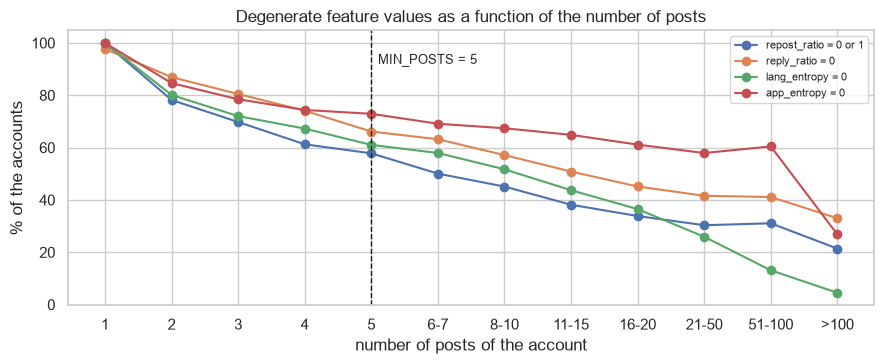

% of IO accounts above the control median, for different minimum numbers of posts:


,repost_ratio,in_network_repost_ratio,dup_text_share,app_entropy,account_age_days,follower_count
minimum posts,,,,,,
2,43.4000,80.7000,82.8000,85.6000,4.3000,14.1000
3,43.9000,81.3000,83.4000,86.3000,4.4000,13.7000
5,43.2000,82.1000,84.1000,87.1000,4.6000,12.8000
10,44.0000,83.9000,85.4000,88.7000,5.0000,12.0000


In [31]:
thr = pd.DataFrame({t: prof.loc[prof['n_posts'] >= t, 'class'].value_counts() for t in [1, 2, 3, 5, 10, 20]}).T
thr.index.name = 'minimum posts'
thr_pct = 100 * thr / prof['class'].value_counts()
display(pd.concat({'accounts kept': thr, '% of the class kept': thr_pct.round(1)}, axis=1))
bk = pd.cut(prof['n_posts'], [0, 1, 2, 3, 4, 5, 7, 10, 15, 20, 50, 100, np.inf],
            labels=['1', '2', '3', '4', '5', '6-7', '8-10', '11-15', '16-20', '21-50', '51-100', '>100'])
degen = prof.groupby(bk, observed=True).agg(
    accounts=('n_posts', 'size'),
    repost_0_or_1=('repost_ratio', lambda s: 100 * s.isin([0, 1]).mean()),
    reply_0=('reply_ratio', lambda s: 100 * (s == 0).mean()),
    lang_entropy_0=('lang_entropy', lambda s: 100 * (s == 0).mean()),
    app_entropy_0=('app_entropy', lambda s: 100 * (s == 0).mean()))
degen.index.name = 'posts of the account'
display(degen.round(1))
fig, ax = plt.subplots(figsize=(9, 3.8))
for col, lab_ in [('repost_0_or_1', 'repost_ratio = 0 or 1'), ('reply_0', 'reply_ratio = 0'),
                  ('lang_entropy_0', 'lang_entropy = 0'), ('app_entropy_0', 'app_entropy = 0')]:
    ax.plot(degen.index.astype(str), degen[col], marker='o', label=lab_)
ax.axvline(4, color='k', ls='--', lw=1)
ax.text(4.1, 92, 'MIN_POSTS = 5', fontsize=9)
ax.set_xlabel('number of posts of the account')
ax.set_ylabel('% of the accounts')
ax.set_title('Degenerate feature values as a function of the number of posts')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
contrast = {}
for t in [2, 3, 5, 10]:
    pt_ = prof[prof['n_posts'] >= t]
    row = {}
    for f_ in ['repost_ratio', 'in_network_repost_ratio', 'dup_text_share', 'app_entropy', 'account_age_days',
               'follower_count']:
        a_, b_ = pt_.loc[pt_['class'] == 'IO', f_].dropna(), pt_.loc[pt_['class'] == 'Control', f_].dropna()
        row[f_] = 100 * (a_ > b_.median()).mean() + 50 * (a_ == b_.median()).mean()
    contrast[t] = row
print('% of IO accounts above the control median, for different minimum numbers of posts:')
display(pd.DataFrame(contrast).T.rename_axis('minimum posts').round(1))

**Decision: at least 5 posts (`MIN_POSTS = 5`).**

* With 1 post every account has a repost ratio of 0 or 1 and zero entropies; with 2 posts this is still true for about
  80% of the accounts. The share of degenerate values falls quickly over the first posts (repost ratio 0 or 1: 100% → 58%
  at 5 posts) and then decreases slowly and steadily (45% at 8–10 posts, about 30% above 20 posts), partly because many
  accounts really never repost or always use the same client. There is no number of posts at which the features suddenly
  become reliable, so the threshold is a compromise between reliability and coverage.
* **Coverage.** 5 posts keep 91.6% of the IO and 78.2% of the control accounts. 10 posts would remove more than a third of
  the control accounts (64.6% kept) and keep mostly the most active ones, while 2–3 posts would keep accounts whose
  ratios can only be 0, ½ or 1.
* **The conclusions do not depend on the threshold.** Between 2 and 10 posts the share of IO accounts above the control
  median changes by at most about 3 points for the main features (e.g. `app_entropy` 85.6% → 88.7%, `account_age_days`
  4.3% → 5.0%).
* With 5 posts every ratio moves by steps of at most 0.2 and the burstiness is computed on at least 4 waiting times.

In [32]:
MIN_POSTS = 5
FEATURES_A = ['n_posts', 'rel_activity', 'active_days', 'lifespan_days', 'posts_per_active_day', 'max_day_share',
              'max_week_share', 'hour_entropy', 'burstiness']
FEATURES_B = ['repost_ratio', 'reply_ratio', 'original_ratio', 'interaction_ratio', 'broadcast_index',
              'self_repost_ratio', 'in_network_repost_ratio', 'top_reposted_share']
FEATURES_C = ['hashtags_per_post', 'urls_per_post', 'mentions_per_post', 'mean_text_len', 'lang_entropy',
              'n_languages', 'app_entropy', 'n_apps', 'dup_text_share']
FEATURES_D = ['follower_count', 'following_count', 'follower_following_ratio', 'account_age_days', 'desc_len',
              'has_description', 'shared_desc']
ALL_FEATURES = FEATURES_A + FEATURES_B + FEATURES_C + FEATURES_D
GROUP_OF = {f: grp for grp, fs in zip('ABCD', [FEATURES_A, FEATURES_B, FEATURES_C, FEATURES_D]) for f in fs}

prof['enough_posts'] = prof['n_posts'] >= MIN_POSTS
print(pd.crosstab(prof['class'], prof['enough_posts'], margins=True))
na = prof[ALL_FEATURES].isna().sum()
print('Missing values in derived features:', na[na > 0].to_dict(),
      '(burstiness: < 3 posts; top_reposted_share: no reposts; mean_text_len: no text)')

enough_posts  False   True    All
class                            
IO              913  10004  10917
Control       16501  59107  75608
All           17414  69111  86525
Missing values in derived features: {'burstiness': 10616, 'top_reposted_share': 23505} (burstiness: < 3 posts; top_reposted_share: no reposts; mean_text_len: no text)


### 1.5.2 IO vs control on the profiles

For each feature we compare the two classes with medians and quartiles, and with the share of IO accounts whose
value is above the median of the control accounts (50% = no difference; a percentile-based summary, [DU] p. 34).

In [33]:
pe = prof[prof['enough_posts']].copy()
rows = []
for f in ALL_FEATURES:
    a = pe.loc[pe['class'] == 'IO', f].dropna()
    b = pe.loc[pe['class'] == 'Control', f].dropna()
    rows.append({'feature': f, 'group': GROUP_OF[f], 'median IO': a.median(), 'IQR IO': a.quantile(.75) - a.quantile(.25),
                 'median Control': b.median(), 'IQR Control': b.quantile(.75) - b.quantile(.25),
                 '% IO above control median': 100 * (a > b.median()).mean() + 50 * (a == b.median()).mean()})
cmp_tab = pd.DataFrame(rows).set_index('feature')
cmp_tab['distance from 50%'] = (cmp_tab['% IO above control median'] - 50).abs()
display(cmp_tab.sort_values('distance from 50%', ascending=False).round(3))

,group,median IO,IQR IO,median Control,IQR Control,% IO above control median,distance from 50%
feature,,,,,,,
max_day_share,A,0.1110,0.2000,1.0000,0.0000,0.3850,49.6150
active_days,A,30.0000,65.0000,1.0000,0.0000,99.6150,49.6150
max_week_share,A,0.2100,0.2900,1.0000,0.0000,1.2100,48.7900
posts_per_active_day,A,3.7220,4.3170,32.0000,71.4170,1.2690,48.7310
lifespan_days,A,143.0990,324.8610,0.8500,0.5800,98.6110,48.6110
account_age_days,D,95.7610,206.4710,848.6010,"1,275.2150",4.5780,45.4220
hour_entropy,A,0.7290,0.2410,0.4810,0.3030,87.9850,37.9850
follower_count,D,95.0000,219.2500,622.0000,"1,979.0000",12.8350,37.1650
n_apps,C,2.0000,2.0000,1.0000,1.0000,87.1250,37.1250


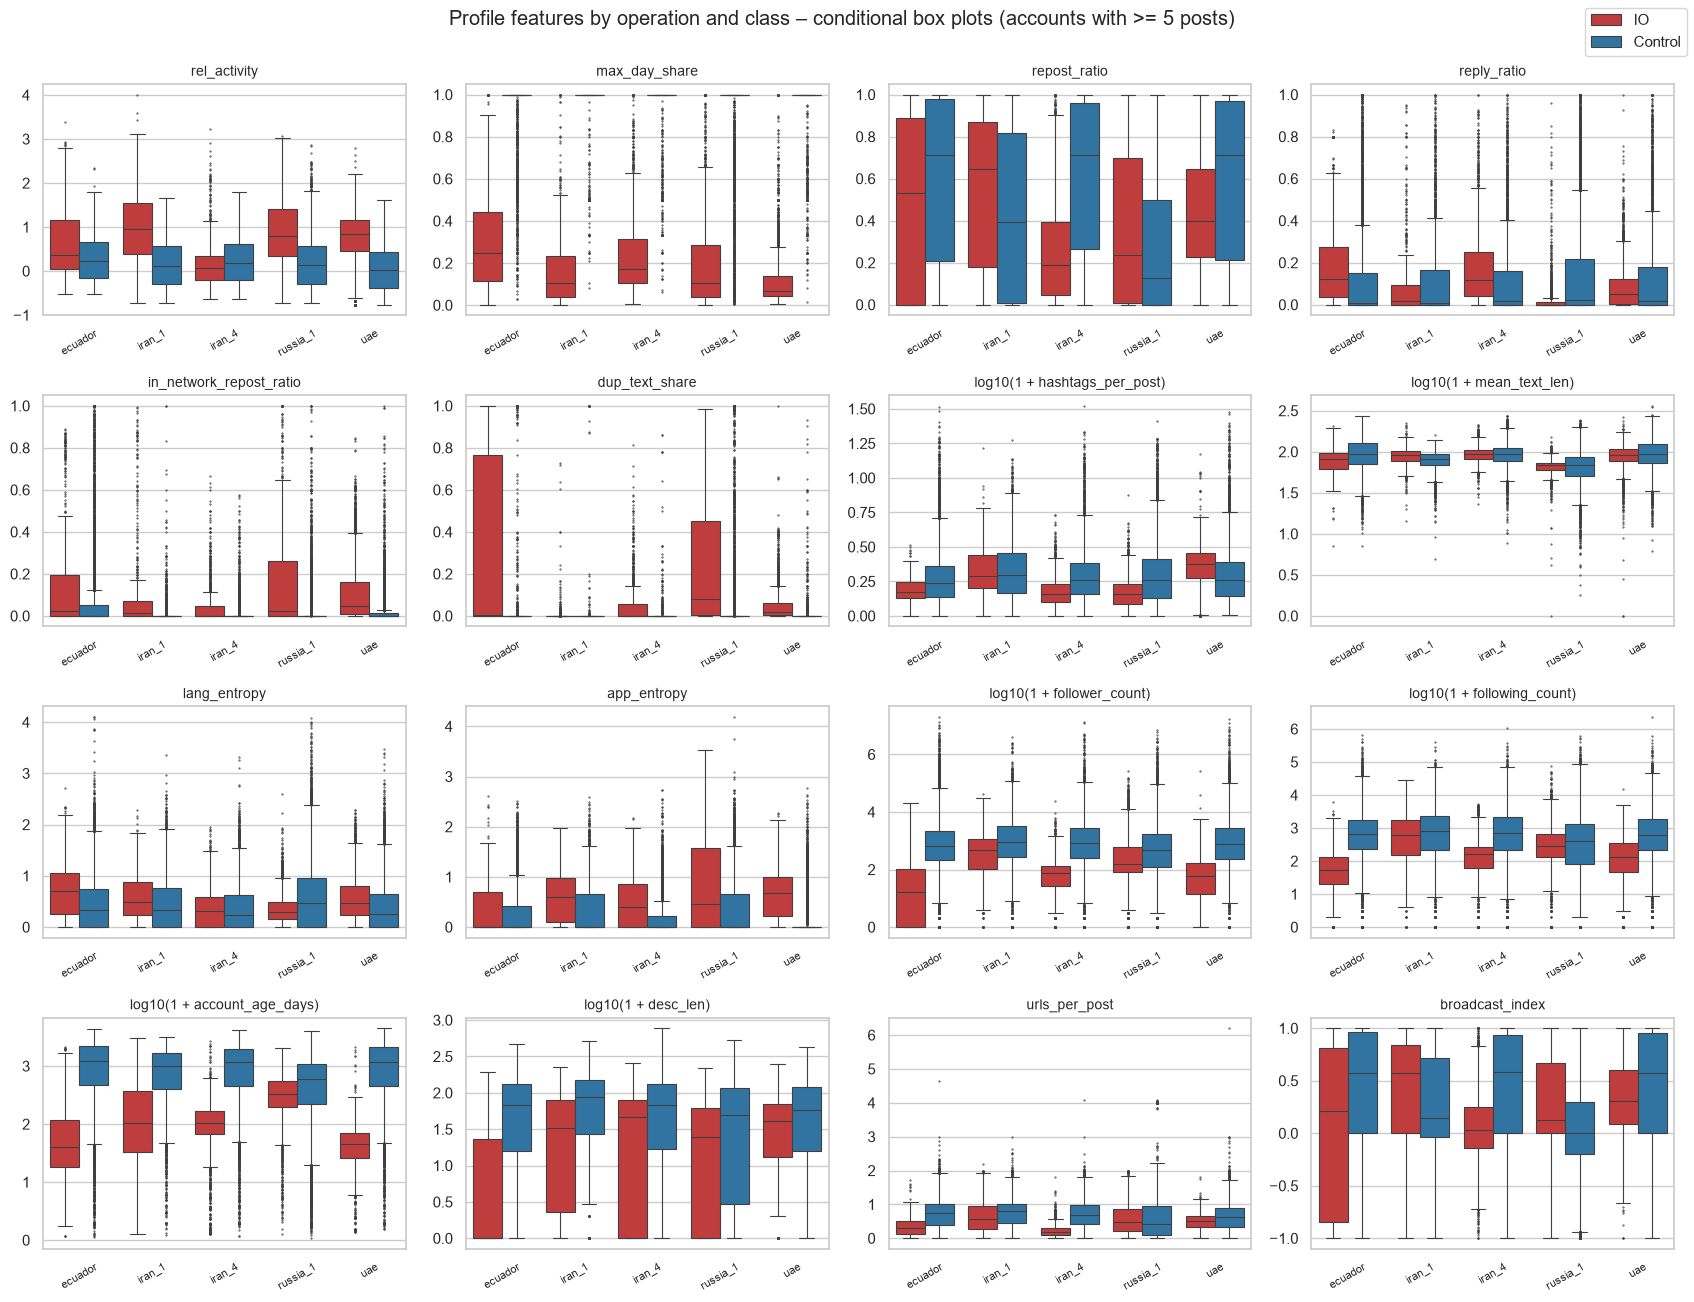

In [34]:
show = ['rel_activity', 'max_day_share', 'repost_ratio', 'reply_ratio', 'in_network_repost_ratio', 'dup_text_share',
        'hashtags_per_post', 'mean_text_len', 'lang_entropy', 'app_entropy', 'follower_count', 'following_count',
        'account_age_days', 'desc_len', 'urls_per_post', 'broadcast_index']
log_feats = {'follower_count', 'following_count', 'account_age_days', 'desc_len', 'hashtags_per_post', 'mean_text_len'}
fig, axes = plt.subplots(4, 4, figsize=(17, 13))
for ax, f in zip(axes.ravel(), show):
    y = np.log10(1 + pe[f]) if f in log_feats else pe[f]
    sns.boxplot(data=pe, x='ioCountry', y=y, hue='class', palette=CLASS_PALETTE, hue_order=CLASS_ORDER,
                ax=ax, fliersize=0.5, linewidth=0.8)
    ax.set_title(f'log10(1 + {f})' if f in log_feats else f, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    ax.legend().remove()
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right')
fig.suptitle('Profile features by operation and class – conditional box plots (accounts with >= 5 posts)', y=1.0)
plt.tight_layout()
plt.show()

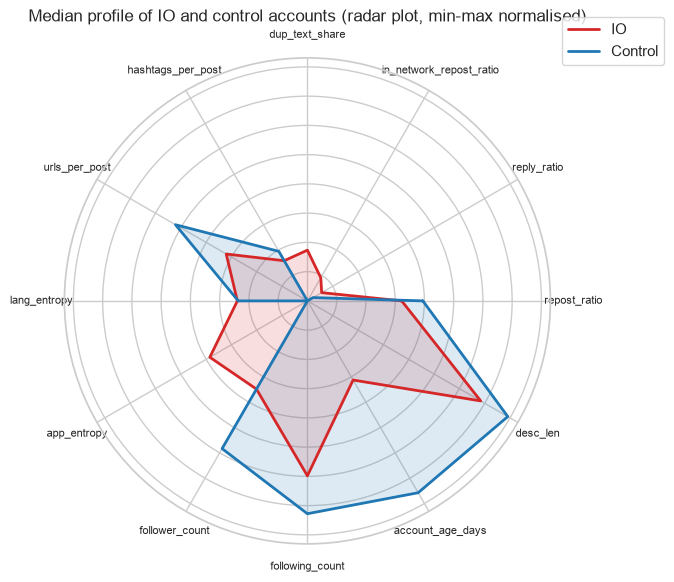

In [35]:
# Radar plot of the median profile of IO and control accounts (features min-max normalised on the class medians)
radar_feats = ['repost_ratio', 'reply_ratio', 'in_network_repost_ratio', 'dup_text_share', 'hashtags_per_post',
               'urls_per_post', 'lang_entropy', 'app_entropy', 'follower_count', 'following_count',
               'account_age_days', 'desc_len']
med = pe.groupby('class', observed=True)[radar_feats].median()
med_log = med.copy()
for f in ['follower_count', 'following_count', 'account_age_days', 'desc_len']:
    med_log[f] = np.log10(1 + med_log[f])
q = pe[radar_feats].copy()
for f in ['follower_count', 'following_count', 'account_age_days', 'desc_len']:
    q[f] = np.log10(1 + q[f])
lo, hi = q.quantile(0.05), q.quantile(0.95)
norm = ((med_log - lo) / (hi - lo).replace(0, 1)).clip(0, 1)     # min-max normalisation on the 5-95% range
angles = np.linspace(0, 2 * np.pi, len(radar_feats), endpoint=False).tolist()
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, polar=True)
for cls in CLASS_ORDER:
    vals = norm.loc[cls].tolist()
    ax.plot(angles + angles[:1], vals + vals[:1], color=CLASS_PALETTE[cls], lw=2, label=cls)
    ax.fill(angles + angles[:1], vals + vals[:1], color=CLASS_PALETTE[cls], alpha=0.15)
ax.set_xticks(angles)
ax.set_xticklabels(radar_feats, fontsize=8)
ax.set_yticklabels([])
ax.set_title('Median profile of IO and control accounts (radar plot, min-max normalised)')
ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1))
plt.tight_layout()
plt.show()

### 1.5.3 Correlations between the derived features

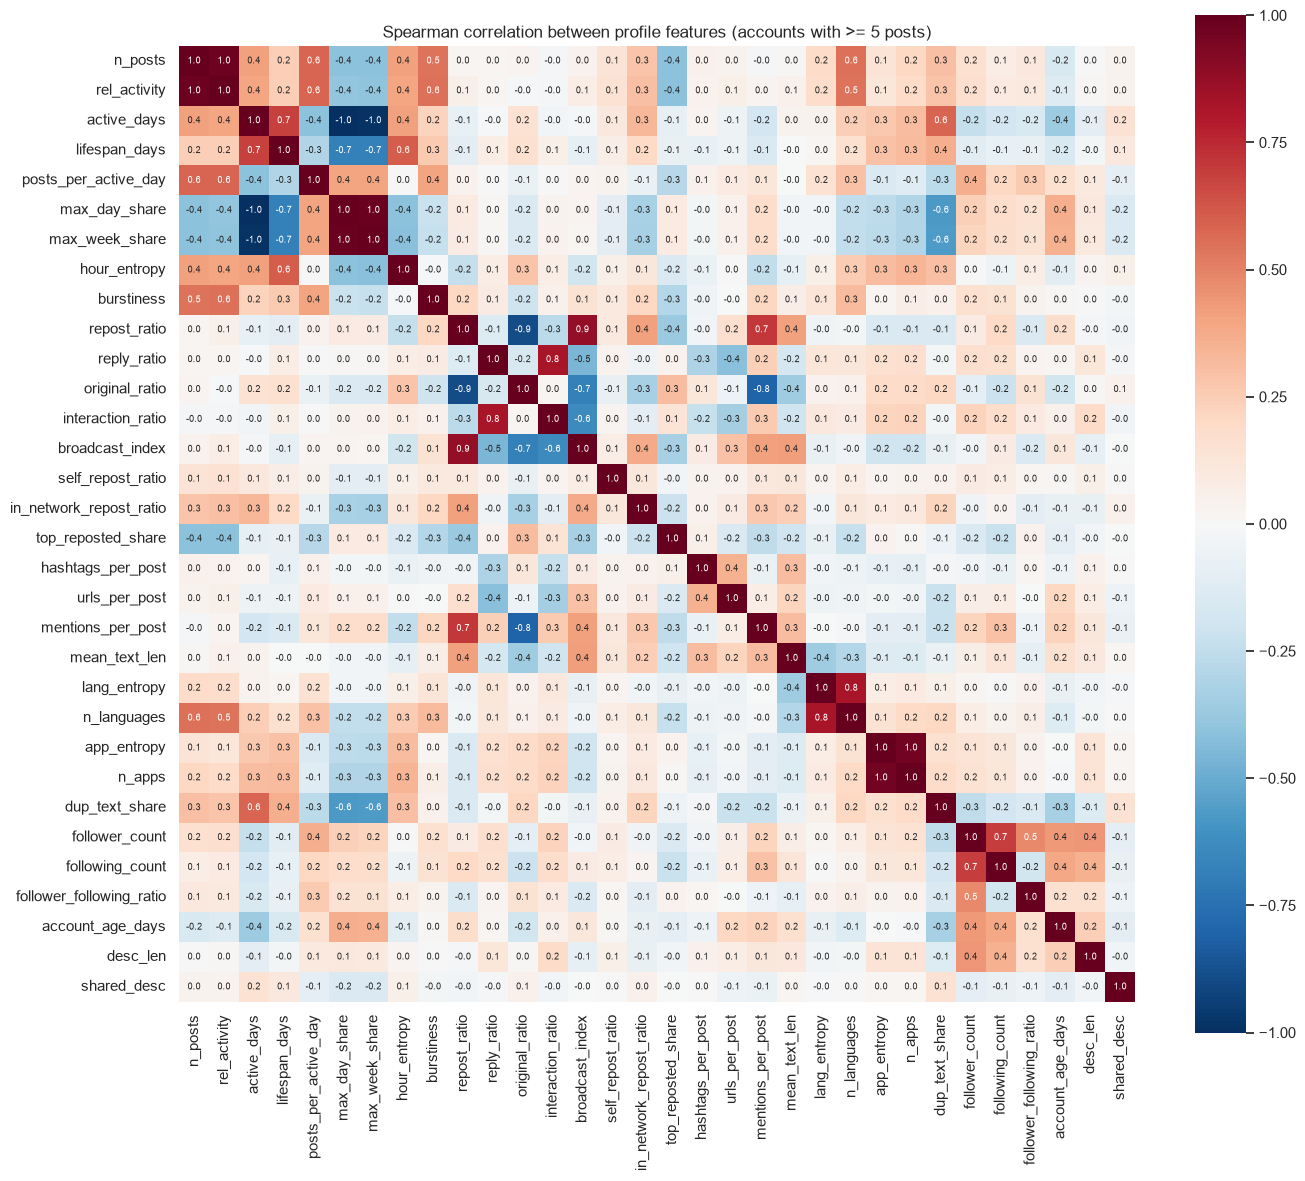

Most correlated pairs of features (|rho| >= 0.7):


,level_0,level_1,rho
0,active_days,max_day_share,-0.9990
1,max_day_share,max_week_share,0.9870
2,active_days,max_week_share,-0.9860
3,n_posts,rel_activity,0.9810
4,app_entropy,n_apps,0.9660
5,repost_ratio,original_ratio,-0.8980
6,repost_ratio,broadcast_index,0.8820
7,reply_ratio,interaction_ratio,0.8230
8,lang_entropy,n_languages,0.8200
9,original_ratio,mentions_per_post,-0.8070


Next pairs, just below the threshold (0.6 <= |rho| < 0.7):


,level_0,level_1,rho
0,follower_count,following_count,0.6950
1,active_days,lifespan_days,0.6860
2,lifespan_days,max_day_share,-0.6850
3,lifespan_days,max_week_share,-0.6840
4,original_ratio,broadcast_index,-0.6810
5,interaction_ratio,broadcast_index,-0.6390
6,lifespan_days,hour_entropy,0.6050


In [36]:
corr_feats = [f for f in ALL_FEATURES if f != 'has_description']
cm = pe[corr_feats].corr(method='spearman')
plt.figure(figsize=(14, 12))
sns.heatmap(cm, cmap='RdBu_r', vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'size': 6.5}, square=True)
plt.title('Spearman correlation between profile features (accounts with >= 5 posts)')
plt.tight_layout()
plt.show()
pairs = (cm.where(np.triu(np.ones(cm.shape, dtype=bool), k=1)).stack().rename('rho').reset_index()
         .assign(abs_rho=lambda d: d['rho'].abs()).sort_values('abs_rho', ascending=False))
print('Most correlated pairs of features (|rho| >= 0.7):')
display(pairs[pairs['abs_rho'] >= 0.7].drop(columns='abs_rho').round(3).reset_index(drop=True))
print('Next pairs, just below the threshold (0.6 <= |rho| < 0.7):')
display(pairs[(pairs['abs_rho'] >= 0.6) & (pairs['abs_rho'] < 0.7)].drop(columns='abs_rho').round(3)
        .reset_index(drop=True))

**Redundant features.** $\rho$ is **Spearman's rank correlation** ([DU] p. 59): Pearson's correlation computed on the
ranks of the values instead of the values themselves. It measures whether two features grow together (monotonic
relation), from −1 (one goes up exactly when the other goes down) to +1, and is not distorted by long tails and
outliers, which is why it is used for the profile features. Two features with $|\rho| \ge 0.7$ order the accounts in
almost the same way, so keeping both would give the same information twice (and twice its weight in a distance). 0.7
is the usual threshold for a "strong" correlation, and the data show a clear gap around it: the pairs above it are
almost definitional, while the next pair, followers–following ($\rho$ = 0.695), describes two different things
(audience and social activity) and both are kept.

| Pair | $\rho$ | Why they are redundant | Kept for the clustering |
|---|---|---|---|
| `active_days` – `max_day_share` – `max_week_share` | −0.999 / 0.987 / −0.986 | more active days ⇔ lower share on the busiest day or week | none (group A, sampling window) |
| `n_posts` – `rel_activity` | 0.981 | `rel_activity` is `n_posts` divided by a constant of the operation (then log) | none (group A) |
| `app_entropy` – `n_apps` | 0.966 | more clients ⇔ higher entropy | `app_entropy`: it also weighs how much each client is used and is bounded |
| `repost_ratio` – `original_ratio` | −0.898 | `original_ratio` = 1 − `repost_ratio` − `reply_ratio` | `repost_ratio` |
| `repost_ratio` – `broadcast_index` | 0.882 | `broadcast_index` = `repost_ratio` − `interaction_ratio` | `repost_ratio` (the index is a combination of two features) |
| `reply_ratio` – `interaction_ratio` | 0.823 | replies are the main part of the interactions | `reply_ratio`: the direct measure |
| `lang_entropy` – `n_languages` | 0.820 | more languages ⇔ higher entropy | `lang_entropy` (same reason as the clients) |
| `original_ratio` – `mentions_per_post` | −0.807 | every repost carries the mention of the original author, so mentions grow with reposts | – |
| `repost_ratio` – `mentions_per_post` | 0.707 | same reason | `repost_ratio` |

Every group is therefore represented by one feature in the clustering (filter method, [DP] p. 18).

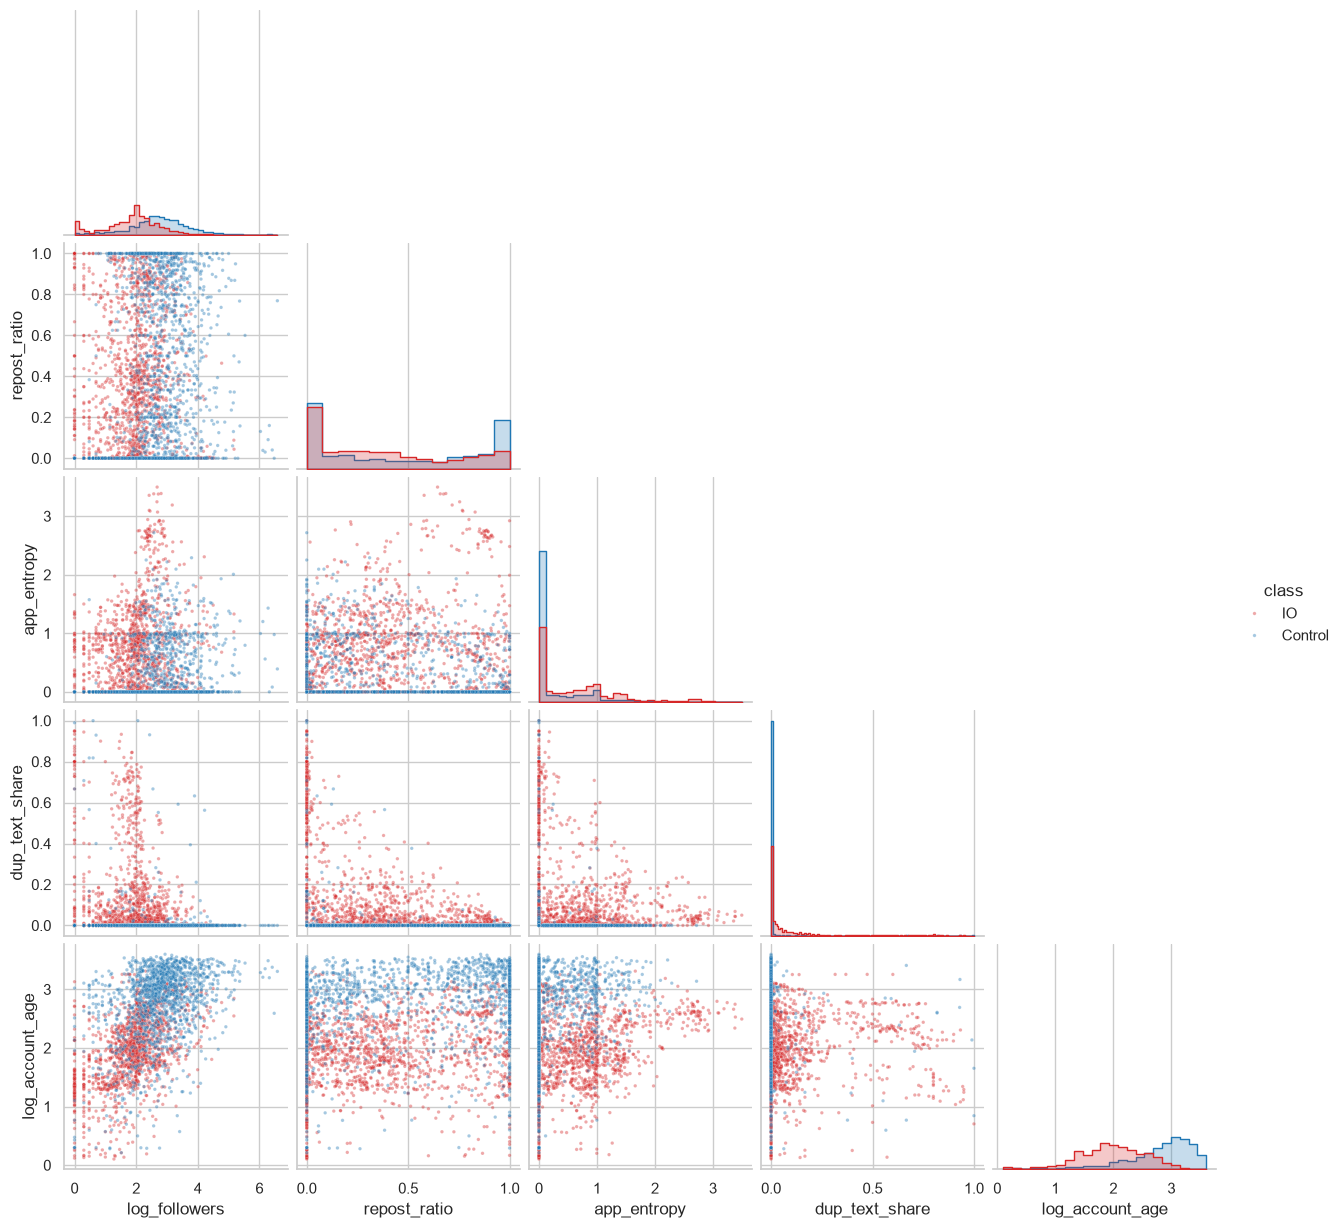

In [37]:
# Scatter matrix of a few key features (random sample of accounts, log scales where needed)
sm_sample = pe.groupby('class', observed=True).sample(1500, random_state=RANDOM_STATE)
sm = pd.DataFrame({'log_followers': np.log10(1 + sm_sample['follower_count']),
                   'repost_ratio': sm_sample['repost_ratio'], 'app_entropy': sm_sample['app_entropy'],
                   'dup_text_share': sm_sample['dup_text_share'],
                   'log_account_age': np.log10(1 + sm_sample['account_age_days']), 'class': sm_sample['class']})
sns.pairplot(sm, hue='class', palette=CLASS_PALETTE, hue_order=CLASS_ORDER, corner=True, diag_kind='hist',
             plot_kws={'s': 6, 'alpha': 0.4}, diag_kws={'common_norm': False, 'element': 'step'})
plt.show()
del sm_sample, sm

### 1.5.4 Shared profile descriptions [Q&A Q15]

The Q&A points out that many users have the same profile description as other users and suggests analysing this
pattern more deeply. We work at account level (one biography per account) and compare normalised biographies
(lower case, collapsed spaces) **inside the same operation**.

In [38]:
bio = prof[['ioCountry', 'class', 'desc_h', 'desc_group_size', 'shared_desc']].copy()
bio['has_bio'] = bio['desc_h'] != 0
empty_as_value = bio.groupby(['ioCountry', bio['desc_h']], observed=True)['desc_h'].transform('size') >= 2
bio_tab = pd.DataFrame({
    '% accounts without biography': 100 * (~bio['has_bio']).groupby(bio['class'], observed=True).mean(),
    '% of the accounts WITH a biography that share it in the operation':
        100 * bio[bio['has_bio']].groupby('class', observed=True)['shared_desc'].mean(),
    '% "sharing" if empty biographies count as one shared value': 100 * empty_as_value.groupby(bio['class'], observed=True).mean(),
})
display(bio_tab.round(1))

groups = (bio[bio['shared_desc'] == 1].groupby(['ioCountry', 'desc_h'], observed=True)
          .agg(size=('class', 'size'), io_share=('class', lambda s: (s == 'IO').mean())))
print(f'Groups of accounts sharing the same biography inside an operation: {len(groups):,} | pure IO: '
      f'{int((groups["io_share"] == 1).sum())} | pure control: {int((groups["io_share"] == 0).sum())} | mixed: '
      f'{int(((groups["io_share"] > 0) & (groups["io_share"] < 1)).sum())} | largest group: {groups["size"].max()} accounts')
display(groups.reset_index().groupby('ioCountry', observed=True)
        .agg(groups=('size', 'size'), accounts=('size', 'sum'), pure_IO_groups=('io_share', lambda s: int((s == 1).sum())))
        .astype(int))
del bio, empty_as_value, groups

,% accounts without biography,% of the accounts WITH a biography that share it in the operation,"% ""sharing"" if empty biographies count as one shared value"
class,,,
IO,28.3000,12.2000,37.1000
Control,22.4000,1.6000,23.7000


Groups of accounts sharing the same biography inside an operation: 692 | pure IO: 366 | pure control: 277 | mixed: 49 | largest group: 40 accounts


,groups,accounts,pure_IO_groups
ioCountry,,,
ecuador,97,263,2
iran_1,14,45,6
iran_4,178,482,149
russia_1,230,691,78
uae,173,434,131


* At account level, **≈23% of the accounts have no biography**; if empty biographies were counted as one shared value,
  about a quarter of the accounts would "share" a description, and at post level almost every record repeats the
  biography of other records (every post carries the biography of its account). Such figures say little.
* Among the accounts **with** a biography, only ≈3% share it with another account of the same operation, but this
  is **much more frequent for IO accounts (12.2%) than for control accounts (1.6%)**: template biographies are a
  further coordination signal. Of the 692 groups of accounts sharing a biography, 366 are purely IO, 277 purely control
  and only 49 mixed; groups are small (at most 40 accounts). The purely IO groups are concentrated in **Iran_4** (149
  of its 178 groups) and **UAE** (131 of 173), whereas in Ecuador almost all the shared biographies belong to control
  accounts.
* The indicator `shared_desc` is therefore added to the profile. Being binary and rare (≈3% of the accounts), it is not
  used as a clustering attribute (it would dominate the Euclidean distance once standardised), but it is used to
  **describe the clusters** in Task 2.

**Main findings on the user profiles**

* The **activity/time features** (group A) show the largest IO–control differences (e.g. `active_days`: median 30
  vs 1; `max_day_share`: 0.11 vs 1.0), but – as shown in 1.2.6 – they mostly describe the different observation
  windows of the two classes, not their behaviour.
* Among the behavioural features, IO accounts are clearly:
  * **younger** when they post (median account age 96 vs 849 days; only 4.6% of IO accounts are older than the
    median control account);
  * **less followed** (median 95 vs 622 followers) and following fewer accounts, with a negative
    follower/following balance;
  * engaged in **copy-paste coordination** (`dup_text_share`: 84% of IO accounts above the control median of 0) and
    in **amplification of their own operation** (`in_network_repost_ratio`: 82%);
  * using **more publishing clients per account** (`n_apps`, `app_entropy`) – partly a consequence of their larger
    number of posts – with fewer mentions, fewer links and shorter biographies (the written texts have the same length:
    median ≈ 80 characters in both classes);
  * using **template biographies** shared with other accounts of their operation much more often (1.5.4).
* Repost/reply ratios and language entropy differ little *globally*, but a lot – and with opposite signs – inside
  the single operations (conditional box plots), so they remain useful to separate behavioural styles.
* **Redundant features** (|ρ| ≥ 0.7): `active_days` / `max_day_share` / `max_week_share`; `n_posts` /
  `rel_activity`; `app_entropy` / `n_apps`; `lang_entropy` / `n_languages`; `repost_ratio` / `original_ratio` /
  `broadcast_index` / `mentions_per_post`; `reply_ratio` / `interaction_ratio`. Only one representative of each group
  is used for clustering (filter method, [DP] p. 18).

---
# Task 2 – Clustering Analysis

Task 2 only needs the user profiles of Task 1 (`data/user_profiles.parquet`): it can be run on its own after the
setup cells of Section 0.

## 2.1 Selection and preparation of the attributes

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Selection of records and attributes; removing irrelevant / redundant features (filter method based on correlation) | [DP] pp. 2, 14, 17–18 |
| Curse of dimensionality (keep the number of attributes small) | [DP] pp. 15–16 |
| Logarithmic transformation | [DP] pp. 64–66 |
| Outlier treatment: IQR rule, substitution with L or U | [DP] p. 68 |
| z-score normalisation; standardisation needed for Euclidean distance | [DP] p. 47; [SIM] p. 4 |
| Pre-processing for K-means (normalise, treat outliers) | [KM] p. 19 |
| PCA (only for visualisation) and PCA plots | [DP] pp. 52–61; [DU] p. 63 |
| Box plots, Spearman correlation matrix | [DU] pp. 34, 59–60 |

In [39]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
from pandas.plotting import parallel_coordinates

# Free the large post-level objects of Task 1 (if they exist)
for _name in ['posts', 'p', 'sample_posts', 'pe', 'acc', 'sc_sample']:
    globals().pop(_name, None)
_ = gc.collect()

MIN_POSTS = 5
prof = pd.read_parquet(PROFILES_PQ)
data = prof[prof['n_posts'] >= MIN_POSTS].reset_index(drop=True)
data['class'] = pd.Categorical(data['class'].astype(str), categories=CLASS_ORDER)
print(f'Accounts available for clustering (>= {MIN_POSTS} posts): {len(data):,}  '
      f'{data["class"].value_counts().to_dict()}')

Accounts available for clustering (>= 5 posts): 69,111  {'Control': 59107, 'IO': 10004}


**Selected attributes** (filter method: non-redundant features describing *behaviour* in a way that is comparable
between IO and control accounts):

| Clustering attribute | From profile feature | Transformation | Why |
|---|---|---|---|
| `repost_ratio` | `repost_ratio` | – (proportion) | amplification (represents the redundant group original / broadcast / mentions) |
| `reply_ratio` | `reply_ratio` | – (proportion) | conversation (represents `interaction_ratio`) |
| `in_network_repost_ratio` | same | – (proportion) | coordinated amplification inside the operation |
| `dup_text_share` | same | – (proportion) | copy-paste coordination |
| `log_hashtags_per_post` | `hashtags_per_post` | log, IQR capping | hashtag campaigning (long tail) |
| `urls_per_post` | same | IQR capping | link sharing |
| `log_mean_text_len` | `mean_text_len` | log, IQR capping | content length |
| `lang_entropy` | same | – (bounded) | multilingual behaviour (represents `n_languages`) |
| `app_entropy` | same | – (bounded) | use of several clients (represents `n_apps`) |
| `log_followers` | `follower_count` | log, IQR capping | audience |
| `log_following` | `following_count` | log, IQR capping | social activity |
| `log_account_age` | `account_age_days` | log, IQR capping | age of the account when posting |
| `log_desc_len` | `desc_len` | log, IQR capping | profile completeness |

**Excluded attributes.** The label and the operation (used only for evaluation); all **activity/time** features of
group A, because the observation windows of IO and control accounts are different by design (1.2.6) and the
clusters would reproduce the data collection instead of behaviour; the redundant features of 1.5.3;
`follower_following_ratio` (a linear combination of two selected attributes); `self_repost_ratio` (almost always 0)
and `top_reposted_share` (undefined without reposts).

**Preparation, and why each step.** Every algorithm of Task 2 compares accounts through the Euclidean distance
$d(x, y) = \sqrt{\sum_j (x_j - y_j)^2}$ ([SIM] p. 4): each attribute adds its squared difference, so an attribute
with a large spread or with a few huge values decides the distance on its own. The three steps remove these effects:

1. **$\log_{10}(1+x)$** ([DP] pp. 64–66) for the counts with a long tail (followers, following, hashtags per post,
   1.3.5) and for the two attributes whose differences are relative rather than absolute: for the **account age**
   a 10-day-old and a 100-day-old account differ much more than a 3,000- and a 3,090-day-old one, and for the
   **biography and text length** 0, 10 and 100 characters are three different kinds of profile while 100 and 190 are
   the same kind. On the log scale equal ratios become equal distances.
2. **IQR capping** ([DP] p. 68): for the attributes without a natural upper bound, values outside
   $[L, U] = [Q_1 - 1.5\,IQR, Q_3 + 1.5\,IQR]$ are replaced by $L$ or $U$, so that the few remaining extreme accounts
   cannot pull centroids and stretch distances. Proportions and entropies are bounded by construction and are not
   capped: their extreme values (e.g. accounts whose posts are almost all copies) are exactly the behaviour we want to
   find ([DU] p. 61), and many of them are 0 for most accounts, so the IQR would be 0 and every positive value would be
   cut.
3. **z-score** ([DP] p. 47): every attribute gets mean 0 and standard deviation 1, so that a difference of one
   standard deviation weighs the same in every attribute of the distance.

The effect of each step is shown after the computation of the clustering matrix.

**Why the z-score and not min-max** (normalisation is part of the evaluation, [Q&A Q6]). Both are in [DP] p. 47.
Min-max rescales every attribute to the same *range*, which is fixed by its two most extreme values – exactly the
outliers of these long-tailed data – so one extreme account can squeeze all the others into a small part of [0, 1].
The z-score gives every attribute the same *variance*, using all the values: after the log transformation and the
IQR capping, a deviation of one standard deviation weighs the same in every attribute of the Euclidean distance.

**Same attributes for every algorithm** [Q&A Q11]. All methods start from these 13 attributes, so that they can be
compared. DBSCAN, whose density estimates are the most affected by the number of dimensions ([DBSCAN] p. 10), is also
tested on other sets of input attributes (2.3.2), and the set that works best is kept.

**All users together** [Q&A Q7]. The main analysis clusters all the accounts of all the operations together:
clustering is unsupervised and needs no label. As a complement, K-means is also run inside every operation (2.2.4).
The binary indicator `shared_desc` (1.5.4) is not a clustering attribute, but it is reported in every cluster
description.

In [40]:
CLUSTER_SPEC = {  # clustering attribute -> (profile column, log-transform?, IQR capping?)
    'repost_ratio': ('repost_ratio', False, False),
    'reply_ratio': ('reply_ratio', False, False),
    'in_network_repost_ratio': ('in_network_repost_ratio', False, False),
    'dup_text_share': ('dup_text_share', False, False),
    'log_hashtags_per_post': ('hashtags_per_post', True, True),
    'urls_per_post': ('urls_per_post', False, True),
    'log_mean_text_len': ('mean_text_len', True, True),
    'lang_entropy': ('lang_entropy', False, False),
    'app_entropy': ('app_entropy', False, False),
    'log_followers': ('follower_count', True, True),
    'log_following': ('following_count', True, True),
    'log_account_age': ('account_age_days', True, True),
    'log_desc_len': ('desc_len', True, True),
}
CLUSTER_FEATURES = list(CLUSTER_SPEC)

feat = pd.DataFrame({name: np.log10(1 + data[col].clip(lower=0)) if use_log else data[col]
                     for name, (col, use_log, _) in CLUSTER_SPEC.items()})
feat = feat.fillna(feat.median())     # mean_text_len is missing only when no post has text
feat_log = feat.copy()                # kept to show the effect of the capping
capped, cap_bounds = {}, {}
for name, (_, _, cap) in CLUSTER_SPEC.items():
    if cap:
        q1, q3 = feat[name].quantile([0.25, 0.75])
        lo_, hi_ = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        capped[name] = int(((feat[name] < lo_) | (feat[name] > hi_)).sum())
        cap_bounds[name] = (lo_, hi_)
        feat[name] = feat[name].clip(lower=lo_, upper=hi_)
print('Values replaced by L or U (IQR rule):', capped)
scaler = StandardScaler()
X = scaler.fit_transform(feat)
print('Clustering matrix:', X.shape)
display(feat.describe().T.round(3))

Values replaced by L or U (IQR rule): {'log_hashtags_per_post': 2082, 'urls_per_post': 135, 'log_mean_text_len': 1776, 'log_followers': 2964, 'log_following': 5288, 'log_account_age': 1854, 'log_desc_len': 0}
Clustering matrix: (69111, 13)


,count,mean,std,min,25%,50%,75%,max
repost_ratio,"69,111.0000",0.4430,0.3840,0.0000,0.0340,0.3750,0.8480,1.0000
reply_ratio,"69,111.0000",0.1210,0.1910,0.0000,0.0000,0.0190,0.1720,1.0000
in_network_repost_ratio,"69,111.0000",0.0410,0.1170,0.0000,0.0000,0.0000,0.0160,1.0000
dup_text_share,"69,111.0000",0.0270,0.1180,0.0000,0.0000,0.0000,0.0000,1.0000
log_hashtags_per_post,"69,111.0000",0.2810,0.1850,0.0000,0.1380,0.2510,0.3850,0.7560
urls_per_post,"69,111.0000",0.5900,0.4140,0.0000,0.2220,0.5830,0.9370,2.0080
log_mean_text_len,"69,111.0000",1.9010,0.1780,1.4770,1.7960,1.9130,2.0090,2.3270
lang_entropy,"69,111.0000",0.5060,0.5290,0.0000,0.0000,0.3690,0.7870,4.0990
app_entropy,"69,111.0000",0.3380,0.5280,0.0000,0.0000,0.0000,0.6400,4.1860
log_followers,"69,111.0000",2.6410,0.9770,0.3120,2.0760,2.6830,3.2510,5.0150


1. Logarithm: the long right tail disappears (mean close to the median, skewness close to 0):

,mean/median before,mean/median after,max/Q3 before,max/Q3 after,skewness before,skewness after
log_hashtags_per_post,1.5300,1.1400,22.5900,3.9500,4.8600,1.2200
log_mean_text_len,1.0600,0.9900,3.5800,1.2700,1.0900,-0.5300
log_followers,25.5100,0.9800,"11,174.2600",2.2500,48.9700,-0.1500
log_following,4.6200,0.9500,"1,606.3100",2.0200,76.6000,-0.8900
log_account_age,1.4000,0.9400,3.1100,1.1600,1.0100,-1.1400
log_desc_len,1.2800,0.8100,6.6600,1.4000,0.8500,-0.8400


2. IQR capping: how many values are replaced and how much the spread changes:


,L (original units),U (original units),replaced by L,replaced by U,% replaced,% IO among the replaced,std before,std after
attribute,,,,,,,,
log_hashtags_per_post,0.0000,4.7010,0,2082,3.0130,1.1530,0.2000,0.1850
urls_per_post,0.0000,2.0080,0,135,0.1950,0.7410,0.4220,0.4140
log_mean_text_len,29.0050,211.5430,1412,364,2.5700,4.2230,0.1860,0.1780
log_followers,1.0520,"103,407.8990",2153,811,4.2890,28.1380,1.0100,0.9770
log_following,2.4810,"53,147.1700",5001,287,7.6510,8.3020,0.9850,0.8970
log_account_age,8.4030,"29,643.6110",1854,0,2.6830,25.9980,0.6810,0.6480
log_desc_len,0.0000,"4,681.3580",0,0,0.0000,NaN,0.8270,0.8270


3. z-score: share of the total variance (= of the average squared Euclidean distance) due to each attribute (%):


,original units,after log and capping,after z-score
repost_ratio,0.0000,3.8200,7.6900
reply_ratio,0.0000,0.9400,7.6900
in_network_repost_ratio,0.0000,0.3500,7.6900
dup_text_share,0.0000,0.3600,7.6900
log_hashtags_per_post,0.0000,0.8900,7.6900
urls_per_post,0.0000,4.4200,7.6900
log_mean_text_len,0.0000,0.8200,7.6900
lang_entropy,0.0000,7.2300,7.6900
app_entropy,0.0000,7.2100,7.6900
log_followers,99.5300,24.6400,7.6900


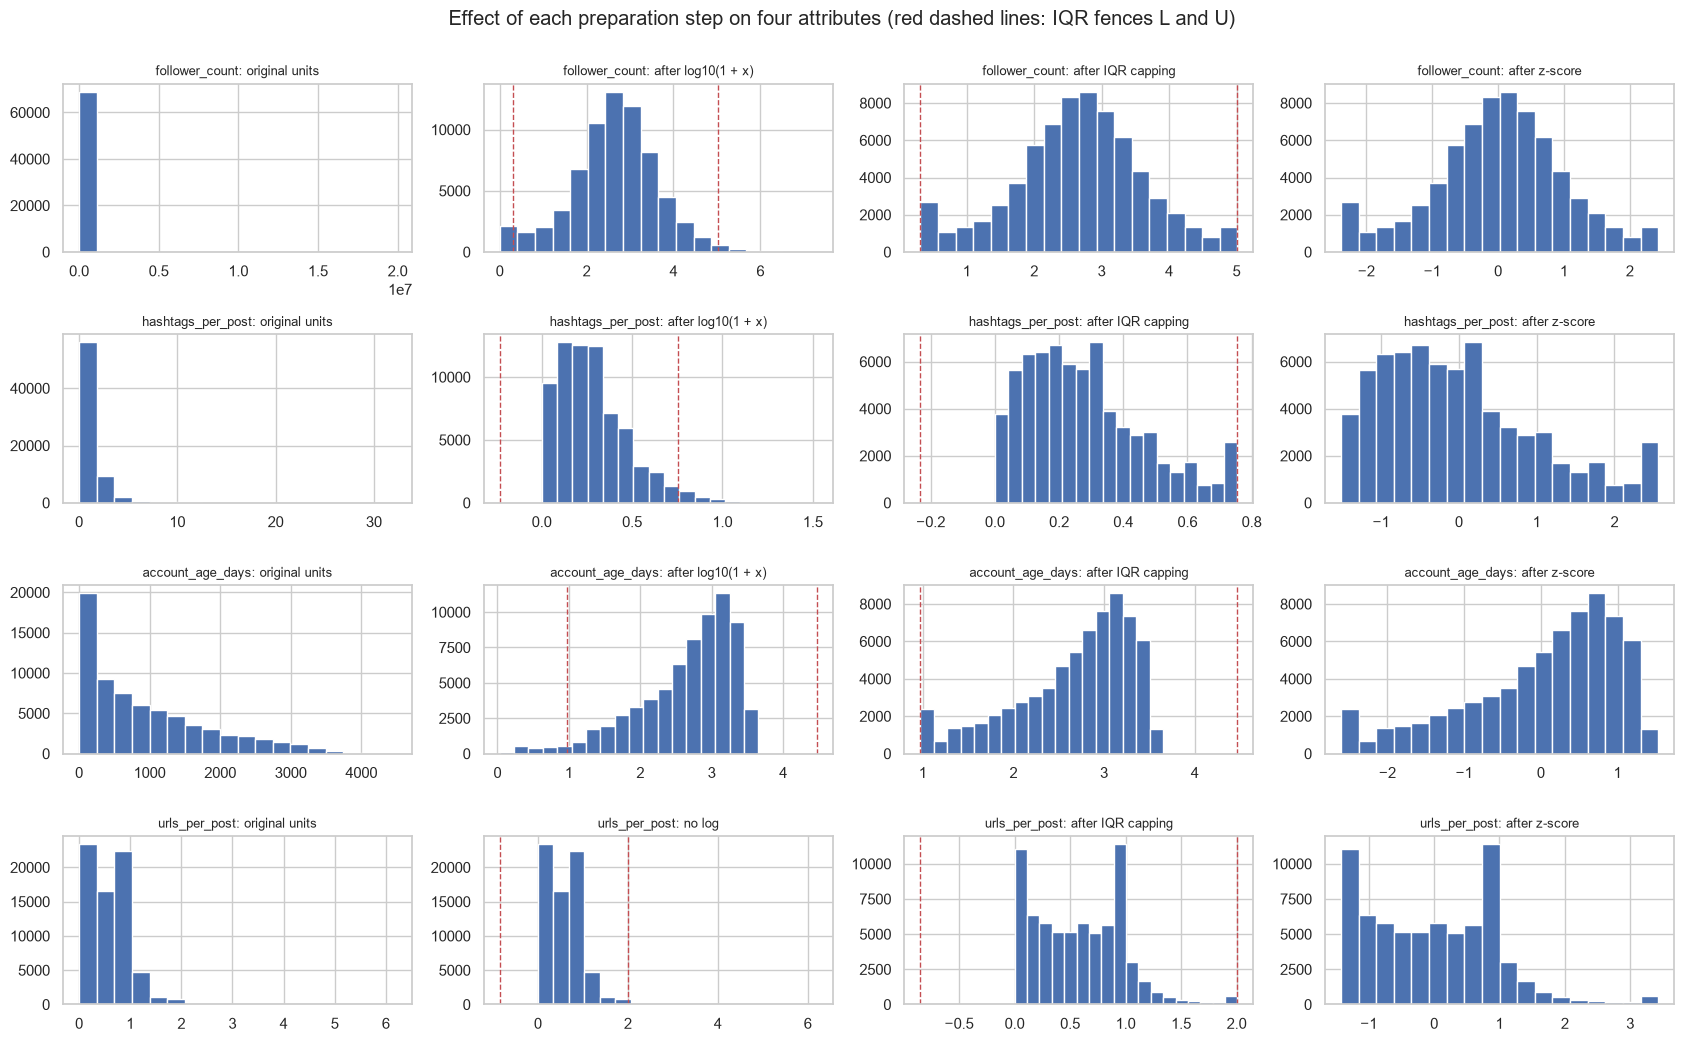

In [41]:
# Effect of every preparation step
raw_units = pd.DataFrame({name: data[col].astype(float) for name, (col, _, _) in CLUSTER_SPEC.items()})
raw_units = raw_units.fillna(raw_units.median())
log_attrs = [n for n, (_, lg, _) in CLUSTER_SPEC.items() if lg]
eff_log = pd.DataFrame({
    'mean/median before': raw_units[log_attrs].mean() / raw_units[log_attrs].median(),
    'mean/median after': feat_log[log_attrs].mean() / feat_log[log_attrs].median(),
    'max/Q3 before': raw_units[log_attrs].max() / raw_units[log_attrs].quantile(0.75),
    'max/Q3 after': feat_log[log_attrs].max() / feat_log[log_attrs].quantile(0.75),
    'skewness before': raw_units[log_attrs].skew(), 'skewness after': feat_log[log_attrs].skew()})
print('1. Logarithm: the long right tail disappears (mean close to the median, skewness close to 0):')
display(eff_log.round(2))
cap_rows = []
for n_, (lo_, hi_) in cap_bounds.items():
    low_, high_ = feat_log[n_] < lo_, feat_log[n_] > hi_
    back = (lambda v: 10 ** v - 1) if CLUSTER_SPEC[n_][1] else (lambda v: v)
    cap_rows.append({'attribute': n_, 'L (original units)': max(back(lo_), 0), 'U (original units)': back(hi_),
                     'replaced by L': int(low_.sum()), 'replaced by U': int(high_.sum()),
                     '% replaced': 100 * (low_ | high_).mean(),
                     '% IO among the replaced': 100 * (data.loc[low_ | high_, 'class'] == 'IO').mean()
                     if (low_ | high_).any() else np.nan,
                     'std before': feat_log[n_].std(), 'std after': feat[n_].std()})
print('2. IQR capping: how many values are replaced and how much the spread changes:')
display(pd.DataFrame(cap_rows).set_index('attribute').round(3))
Xdf = pd.DataFrame(X, columns=CLUSTER_FEATURES)
var_share = pd.DataFrame({'original units': 100 * raw_units.var() / raw_units.var().sum(),
                          'after log and capping': 100 * feat.var() / feat.var().sum(),
                          'after z-score': 100 * Xdf.var() / Xdf.var().sum()})
print('3. z-score: share of the total variance (= of the average squared Euclidean distance) due to each attribute (%):')
display(var_share.round(2))
SHOW_STEPS = ['log_followers', 'log_hashtags_per_post', 'log_account_age', 'urls_per_post']
fig, axes = plt.subplots(len(SHOW_STEPS), 4, figsize=(17, 2.6 * len(SHOW_STEPS)))
for row, n_ in zip(axes, SHOW_STEPS):
    stages = [('original units', raw_units[n_]), ('after log10(1 + x)' if CLUSTER_SPEC[n_][1] else 'no log',
                                                  feat_log[n_]), ('after IQR capping', feat[n_]),
              ('after z-score', Xdf[n_])]
    for ax, (title, v) in zip(row, stages):
        ax.hist(v, bins=sturges_bins(len(v)), color='#4c72b0')
        ax.set_title(f'{CLUSTER_SPEC[n_][0]}: {title}', fontsize=9)
    if n_ in cap_bounds:
        for ax in row[1:3]:
            for b in cap_bounds[n_]:
                ax.axvline(b, color='r', ls='--', lw=1)
fig.suptitle('Effect of each preparation step on four attributes (red dashed lines: IQR fences L and U)', y=1.0)
plt.tight_layout()
plt.show()

**What each step does** (tables and figure above).

* **Logarithm.** For the long-tailed counts it removes the tail: the skewness of the followers drops from 49 to −0.15, of
  the followed accounts from 77 to −0.9, of the hashtags per post from 4.9 to 1.2, and the maximum of the followers,
  11,174 times the third quartile, becomes 2.3 times it. For the account age and the two lengths the log is not about a
  tail (skewness about 1 before, −0.5 to −1.1 after) but about **relative differences**: on a linear scale the youngest
  quarter of the accounts (less than 192 days old when posting) occupies 4% of the range 0–4,493 days, on the log scale
  63% of it – the scale spends its resolution on the first months of life of an account, where the IO accounts are.
  Likewise, 0, 10 and 100 characters of biography (no profile, a stub, a complete profile) become 0, 1.0 and 2.0.
* **IQR capping** replaces between 0% and 7.7% of the values of an attribute with $L$ or $U$ – e.g. the 2,153 accounts
  without followers are raised to $L$ ≈ 1 follower and the 811 accounts with more than 103k followers lowered to $U$ –
  and slightly reduces the spread (standard deviation of `log_following` 0.99 → 0.90). The replaced values are mostly
  control accounts at the extremes (celebrities, hashtag spammers); among the accounts without followers or posting in
  their first days about a quarter are IO.
* **z-score.** Before it, the Euclidean distance would be decided by a few attributes: in original units the followers
  alone make 99.5% of the total variance; after log and capping the four account attributes still make 74% of it
  (followers 25%, following 21%, biography 18%, age 11%), while the coordination signals `in_network_repost_ratio` and
  `dup_text_share` make less than 0.4% each. After the z-score every attribute has variance 1 and contributes 1/13 =
  7.7% of the distance.

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(feat.corr(method='spearman'), cmap='RdBu_r', vmin=-1, vmax=1, annot=True, fmt='.2f',
            annot_kws={'size': 7}, ax=axes[0])
axes[0].set_title('Spearman correlation of the clustering attributes')
axes[1].boxplot(X, orientation='horizontal', tick_labels=CLUSTER_FEATURES, flierprops={'markersize': 1})
axes[1].set_title('Standardised clustering attributes (z-scores)')
plt.tight_layout()
plt.show()

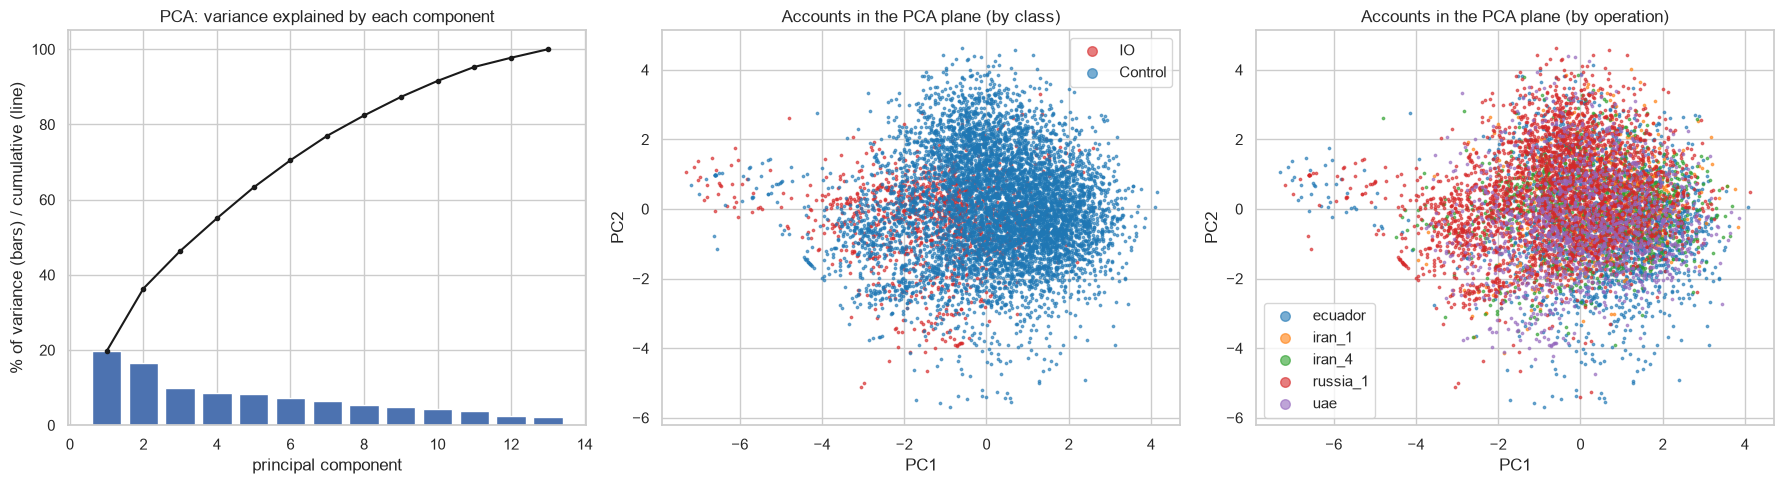

Explained variance (first 5 PCs): [19.7 16.7 10.   8.7  8.2] | 2 PCs together: 36.4 %


,repost_ratio,reply_ratio,in_network_repost_ratio,dup_text_share,log_hashtags_per_post,urls_per_post,log_mean_text_len,lang_entropy,app_entropy,log_followers,log_following,log_account_age,log_desc_len
PC1,0.2600,-0.0400,0.0300,-0.2800,0.0400,0.2100,0.2800,-0.1300,0.0600,0.4800,0.4600,0.4000,0.3300
PC2,-0.3400,0.4300,-0.3100,0.0200,-0.3300,-0.3500,-0.3900,0.1700,0.1500,0.2600,0.2100,0.1100,0.2200


In [42]:
# PCA: used only to VISUALISE the accounts (every algorithm works in the full 13-dimensional space)
pca = PCA(random_state=RANDOM_STATE).fit(X)
X_pca = pca.transform(X)[:, :2]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].bar(range(1, len(CLUSTER_FEATURES) + 1), pca.explained_variance_ratio_ * 100)
axes[0].plot(range(1, len(CLUSTER_FEATURES) + 1), np.cumsum(pca.explained_variance_ratio_) * 100, 'k.-')
axes[0].set_xlabel('principal component')
axes[0].set_ylabel('% of variance (bars) / cumulative (line)')
axes[0].set_title('PCA: variance explained by each component')
vis_idx = rng.choice(len(X), size=8000, replace=False)          # sample of points used in the scatter plots
for cls in CLASS_ORDER:
    m = (data['class'].to_numpy()[vis_idx] == cls)
    axes[1].scatter(X_pca[vis_idx][m, 0], X_pca[vis_idx][m, 1], s=3, color=CLASS_PALETTE[cls], label=cls, alpha=0.6)
axes[1].set_title('Accounts in the PCA plane (by class)')
axes[1].legend(markerscale=4)
for i, op in enumerate(data['ioCountry'].cat.categories):
    m = (data['ioCountry'].to_numpy()[vis_idx] == op)
    axes[2].scatter(X_pca[vis_idx][m, 0], X_pca[vis_idx][m, 1], s=3, color=plt.cm.tab10(i), label=op, alpha=0.6)
axes[2].set_title('Accounts in the PCA plane (by operation)')
axes[2].legend(markerscale=4)
for ax in axes[1:]:
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
plt.tight_layout()
plt.show()
print('Explained variance (first 5 PCs):', (pca.explained_variance_ratio_[:5] * 100).round(1),
      '| 2 PCs together:', round(pca.explained_variance_ratio_[:2].sum() * 100, 1), '%')
display(pd.DataFrame(pca.components_[:2].T, index=CLUSTER_FEATURES, columns=['PC1', 'PC2']).round(2).T)

In [43]:
# Helper functions shared by all the clustering methods
def cluster_names(labels, noise_label=-1):
    return pd.Series(np.asarray(labels)).map(lambda c: 'noise' if c == noise_label else f'C{c}')


def name_order(names):
    return sorted(set(names), key=lambda s: (s == 'noise', int(s[1:]) if s != 'noise' else 0))


def entropy_purity(labels, classes, noise_label=-1):
    """External validity ([VAL] p. 20): total entropy e = sum_j m_j/m * e_j and purity = sum_j m_j/m * max_i p_ij,
    computed on the clustered points (noise excluded)."""
    lab, cl = np.asarray(labels), np.asarray(classes)
    m = lab != noise_label
    ct = pd.crosstab(lab[m], cl[m]).to_numpy().astype(float)
    pij = ct / ct.sum(1, keepdims=True)
    with np.errstate(divide='ignore', invalid='ignore'):
        e_j = -np.nansum(np.where(pij > 0, pij * np.log2(pij), 0), axis=1)
    w = ct.sum(1) / ct.sum()
    return float((w * e_j).sum()), float((w * pij.max(1)).sum())


def cluster_summary(labels, name, noise_label=-1, idx=None):
    """Size, share of IO accounts, operation mix, entropy and purity (w.r.t. the class) of every cluster."""
    d = data if idx is None else data.iloc[idx]
    lab = cluster_names(labels, noise_label).set_axis(d.index)
    is_io = d['class'].eq('IO')
    summ = pd.DataFrame({'size': lab.value_counts(), 'size %': 100 * lab.value_counts(normalize=True),
                         'IO accounts': is_io.groupby(lab).sum(), 'control accounts': (~is_io).groupby(lab).sum(),
                         '% IO': 100 * is_io.groupby(lab).mean()})
    summ = summ.join((pd.crosstab(lab, d['ioCountry'], normalize='index') * 100).add_prefix('% '))
    summ['% of all IO accounts'] = 100 * is_io.groupby(lab).sum() / is_io.sum()
    summ['% shared bio'] = 100 * d['shared_desc'].groupby(lab).mean()        # description only, not an input
    p_io = summ['% IO'] / 100
    with np.errstate(divide='ignore', invalid='ignore'):
        summ['class entropy'] = -(np.where(p_io > 0, p_io * np.log2(p_io), 0)
                                  + np.where(p_io < 1, (1 - p_io) * np.log2(1 - p_io), 0))
    summ['class purity'] = np.maximum(p_io, 1 - p_io)
    e_tot, p_tot = entropy_purity(labels, d['class'], noise_label)
    print(f'{name}: {len(summ) - ("noise" in summ.index)} clusters | total class entropy = {e_tot:.3f} bits, '
          f'purity = {p_tot:.3f} (noise excluded)')
    return summ.loc[name_order(summ.index)].round(3)


def cluster_profiles(labels, name, noise_label=-1, idx=None):
    """Parallel-coordinates plot of the mean z-score of every attribute in every cluster ([DU] p. 45) and table
    of the medians in original units (log attributes back-transformed)."""
    Xs = X if idx is None else X[idx]
    fs = feat if idx is None else feat.iloc[idx]
    lab = cluster_names(labels, noise_label).to_numpy()
    z = pd.DataFrame(Xs, columns=CLUSTER_FEATURES).groupby(lab).mean()
    z = z.loc[name_order(z.index)]
    fig, ax = plt.subplots(figsize=(15, 4.5))
    parallel_coordinates(z.reset_index().rename(columns={'index': 'cluster'}), 'cluster', ax=ax,
                         color=[plt.cm.tab10(i % 10) if c != 'noise' else '#999999' for i, c in enumerate(z.index)],
                         lw=2)
    ax.axhline(0, color='k', lw=0.6)
    ax.set_ylabel('mean z-score')
    ax.set_title(f'{name}: cluster profiles (parallel coordinates of the cluster means)')
    ax.tick_params(axis='x', rotation=30)
    plt.tight_layout()
    plt.show()
    med = fs.reset_index(drop=True).groupby(lab).median()
    for col, (_, use_log, _) in CLUSTER_SPEC.items():
        if use_log:
            med[col] = 10 ** med[col] - 1
    med.columns = [CLUSTER_SPEC[c][0] if CLUSTER_SPEC[c][1] else c for c in CLUSTER_FEATURES]
    return med.loc[name_order(med.index)].round(3)


def internal_scores(Xs, labels, noise_label=-1, sample=None):
    """SSE (cohesion), BSS (separation) and average silhouette ([VAL] pp. 14-19); noise points excluded."""
    lab = np.asarray(labels)
    m = lab != noise_label
    Xm, lm = Xs[m], lab[m]
    if len(set(lm)) < 2:
        return {'SSE': np.nan, 'BSS': np.nan, 'silhouette': np.nan}
    overall = Xm.mean(0)
    sse = bss = 0.0
    for c in np.unique(lm):
        pts = Xm[lm == c]
        cen = pts.mean(0)
        sse += ((pts - cen) ** 2).sum()
        bss += len(pts) * ((cen - overall) ** 2).sum()
    sil = silhouette_score(Xm, lm, sample_size=sample, random_state=RANDOM_STATE)
    return {'SSE': sse, 'BSS': bss, 'silhouette': sil}


def scatter_pca(labels, title, ax, idx=None, noise_label=-1):
    """Clusters in the PCA plane (noise in light grey)."""
    pos = vis_idx if idx is None else idx
    lab = np.asarray(labels) if idx is not None else np.asarray(labels)[vis_idx]
    xy = X_pca[pos]
    for c in sorted(set(lab)):
        m = lab == c
        ax.scatter(xy[m, 0], xy[m, 1], s=3 if c <= 0 else 6, label='noise' if c == noise_label else f'C{c}',
                   color='lightgrey' if c == noise_label else plt.cm.tab10(c % 10), zorder=1 if c <= 0 else 3)
    ax.set_title(title)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(markerscale=4, fontsize=8)

## 2.2 K-means

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Basic K-means algorithm (centroid = mean, Euclidean distance) | [KM] pp. 3–6 |
| Random initial centroids and multiple runs | [KM] pp. 6, 20–29 |
| SSE and choice of the number of clusters (SSE curve) | [KM] pp. 7–8; [VAL] pp. 14–15 |
| Cohesion (SSE) and separation (BSS) | [VAL] pp. 16–18 |
| Silhouette coefficient (points, clusters, clustering) | [VAL] p. 19 |
| Statistical framework: SSE compared with random data | [VAL] pp. 4, 21–22 |
| External validity: entropy and purity w.r.t. the class | [VAL] p. 20 |
| Limitations of K-means (sizes, densities, shapes, outliers) | [KM] pp. 10–16 |
| Parallel coordinates, PCA plot | [DU] pp. 45, 63 |

### 2.2.1 Choice of k

K-means is run for $k = 2, \dots, 12$ with **random initial centroids and 10 runs** for every k (the run with the
lowest SSE is kept). For each k we record the SSE, the BSS and the average silhouette (computed on a random sample
of 10,000 accounts).

,SSE,BSS,silhouette
k,,,
2,"784,800.1820","113,642.8180",0.1300
3,"703,726.7590","194,716.2410",0.1250
4,"646,946.6550","251,496.3450",0.1390
5,"596,125.7350","302,317.2650",0.1510
6,"556,540.1690","341,902.8310",0.1470
7,"530,962.5020","367,480.4980",0.1490
8,"508,107.1690","390,335.8310",0.1400
9,"486,915.4500","411,527.5500",0.1460
10,"466,386.0560","432,056.9440",0.1410


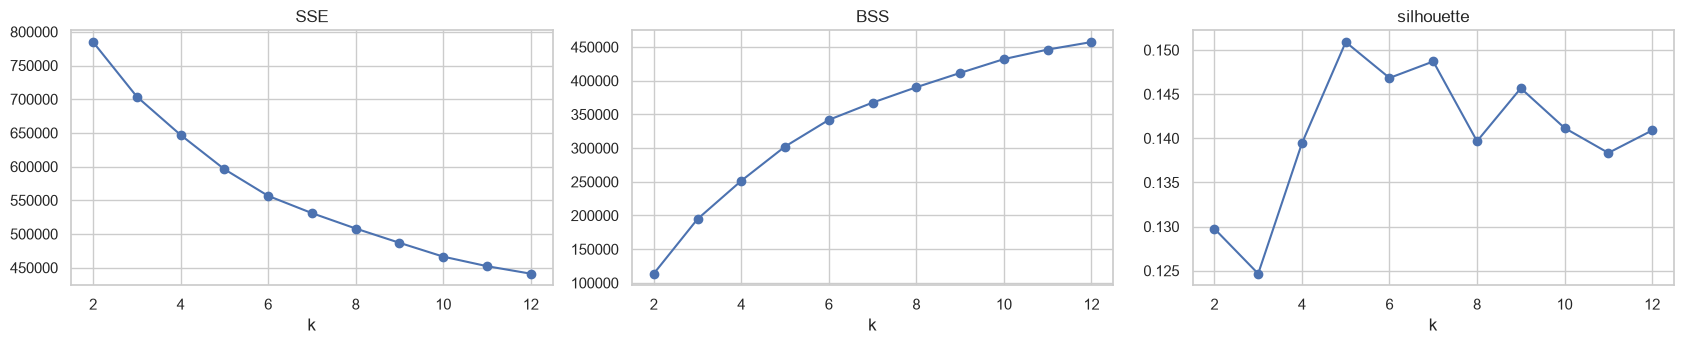

In [44]:
K_RANGE = range(2, 13)
km_rows, km_models = [], {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, init='random', n_init=10, random_state=RANDOM_STATE).fit(X)
    km_models[k] = km
    sc = internal_scores(X, km.labels_, sample=10_000)
    km_rows.append({'k': k, **sc})
km_eval = pd.DataFrame(km_rows).set_index('k')
display(km_eval.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, col in zip(axes, ['SSE', 'BSS', 'silhouette']):
    ax.plot(km_eval.index, km_eval[col], marker='o')
    ax.set_title(col)
    ax.set_xlabel('k')
plt.tight_layout()
plt.show()

**Choice of k.** The SSE decreases smoothly, without a sharp elbow (BSS grows by the same amount, since
SSE + BSS is constant, [VAL] p. 18): its curvature is strongest between k = 4 and k = 6, typical of behavioural data
without well-separated groups. The silhouette is low for every k (0.125–0.151: the clusters overlap) but reaches its
**maximum at k = 5** (0.151). Larger values of k reduce the SSE only marginally while fragmenting the groups. We
therefore select **k = 5**.

### 2.2.2 Is the structure better than random? (statistical framework for the SSE)

Following [VAL] pp. 21–22, we compare the SSE of the chosen clustering with the SSE obtained by K-means (same k) on
**random data** with the same marginal distributions: every attribute is shuffled independently, which keeps each
distribution but destroys the joint structure.

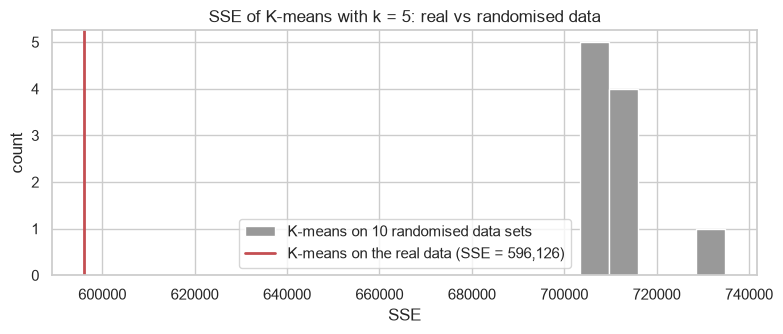

Random data: SSE between 703,451 and 734,761; real data: 596,126 (16.2% lower)


In [45]:
K_BEST = 5
kmeans = km_models[K_BEST]
labels_km = kmeans.labels_
rand_sse = []
for r in range(10):
    perm_rng = np.random.default_rng(100 + r)            # one generator: a different permutation for every column
    Xr = np.column_stack([perm_rng.permutation(X[:, j]) for j in range(X.shape[1])])
    rand_sse.append(KMeans(n_clusters=K_BEST, init='random', n_init=5, random_state=r).fit(Xr).inertia_)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(rand_sse, bins=sturges_bins(len(rand_sse)), color='#999999', label='K-means on 10 randomised data sets')
ax.axvline(kmeans.inertia_, color='r', lw=2, label=f'K-means on the real data (SSE = {kmeans.inertia_:,.0f})')
ax.set_xlabel('SSE')
ax.set_ylabel('count')
ax.legend()
ax.set_title(f'SSE of K-means with k = {K_BEST}: real vs randomised data')
plt.tight_layout()
plt.show()
print(f'Random data: SSE between {min(rand_sse):,.0f} and {max(rand_sse):,.0f}; real data: {kmeans.inertia_:,.0f} '
      f'({100 * (1 - kmeans.inertia_ / np.mean(rand_sse)):.1f}% lower)')
del Xr

### 2.2.3 Final K-means model: centroids and interpretation

K-means centroids in original units (log attributes back-transformed):


,repost_ratio,reply_ratio,in_network_repost_ratio,dup_text_share,hashtags_per_post,urls_per_post,mean_text_len,lang_entropy,app_entropy,follower_count,following_count,account_age_days,desc_len
C0,0.8450,0.0240,0.4620,0.0230,0.9640,0.7800,93.8470,0.3100,0.7420,132.1240,186.4050,266.3200,8.6670
C1,0.0480,0.0610,0.0110,0.6610,0.7570,0.1380,63.2640,0.5500,0.1420,38.6160,72.1500,129.0030,4.4180
C2,0.2210,0.3060,0.0080,0.0060,0.4760,0.2790,58.3620,0.6490,0.4730,793.7200,539.5830,556.5900,36.4880
C3,0.3120,0.0480,0.0190,0.0180,1.2810,0.6460,75.3850,0.5330,0.2250,49.7220,43.9500,126.7000,7.9310
C4,0.6550,0.0520,0.0250,0.0030,1.0610,0.7820,98.6810,0.4100,0.2740,"1,478.4350","1,121.4800","1,022.9730",46.4210


K-means (k=5): 5 clusters | total class entropy = 0.483 bits, purity = 0.864 (noise excluded)


,size,size %,IO accounts,control accounts,% IO,% ecuador,% iran_1,% iran_4,% russia_1,% uae,% of all IO accounts,% shared bio,class entropy,class purity
C0,3550,5.1370,1771,1779,49.8870,39.6060,2.9300,3.1550,31.1830,23.1270,17.7030,3.2390,1.0000,0.5010
C1,1933,2.7970,1271,662,65.7530,18.5720,0.8280,3.1560,74.5470,2.8970,12.7050,9.3120,0.9270,0.6580
C2,19453,28.1470,1499,17954,7.7060,19.6680,5.4080,9.3150,54.5370,11.0730,14.9840,1.6190,0.3920,0.9230
C3,16767,24.2610,4390,12377,26.1820,12.0830,5.8450,13.6400,47.9510,20.4810,43.8820,4.5800,0.8290,0.7380
C4,27408,39.6580,1073,26335,3.9150,32.8960,8.9350,14.4920,25.1860,18.4910,10.7260,1.1240,0.2380,0.9610


Medians of the attributes in every cluster (original units):


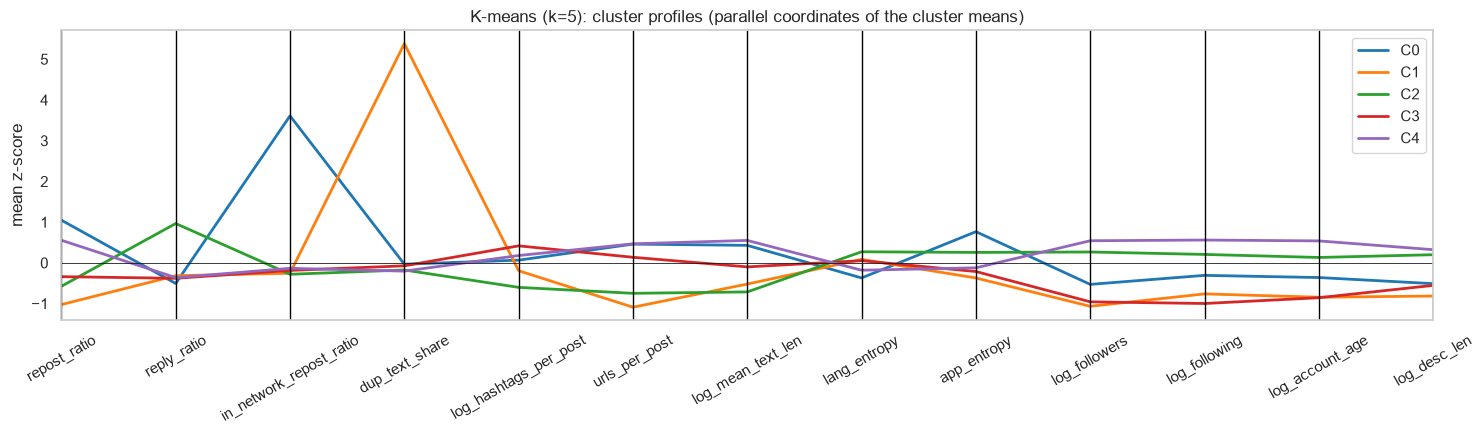

,repost_ratio,reply_ratio,in_network_repost_ratio,dup_text_share,hashtags_per_post,urls_per_post,mean_text_len,lang_entropy,app_entropy,follower_count,following_count,account_age_days,desc_len
C0,0.9090,0.0010,0.4000,0.0000,0.9630,0.8150,90.2080,0.2420,0.1530,145.0000,205.0000,332.7400,15.0000
C1,0.0000,0.0000,0.0000,0.6360,0.7010,0.0920,65.0210,0.2670,0.0000,54.0000,113.0000,195.1460,0.0000
C2,0.1710,0.2680,0.0000,0.0000,0.3750,0.2000,59.3750,0.5570,0.2290,696.0000,561.0000,714.9440,60.0000
C3,0.1080,0.0000,0.0000,0.0000,1.0920,0.6770,79.8570,0.4000,0.0000,62.0000,60.0000,125.5450,15.0000
C4,0.8000,0.0000,0.0000,0.0000,0.9090,0.7880,95.1460,0.2760,0.0000,"1,246.0000","1,162.0000","1,313.5900",88.0000


In [46]:
cent = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=CLUSTER_FEATURES,
                    index=[f'C{i}' for i in range(K_BEST)])
for col, (_, use_log, _) in CLUSTER_SPEC.items():
    if use_log:
        cent[col] = 10 ** cent[col] - 1
cent.columns = [CLUSTER_SPEC[c][0] if CLUSTER_SPEC[c][1] else c for c in CLUSTER_FEATURES]
print('K-means centroids in original units (log attributes back-transformed):')
display(cent.round(3))
km_name = f'K-means (k={K_BEST})'
display(cluster_summary(labels_km, km_name))
print('Medians of the attributes in every cluster (original units):')
display(cluster_profiles(labels_km, km_name))

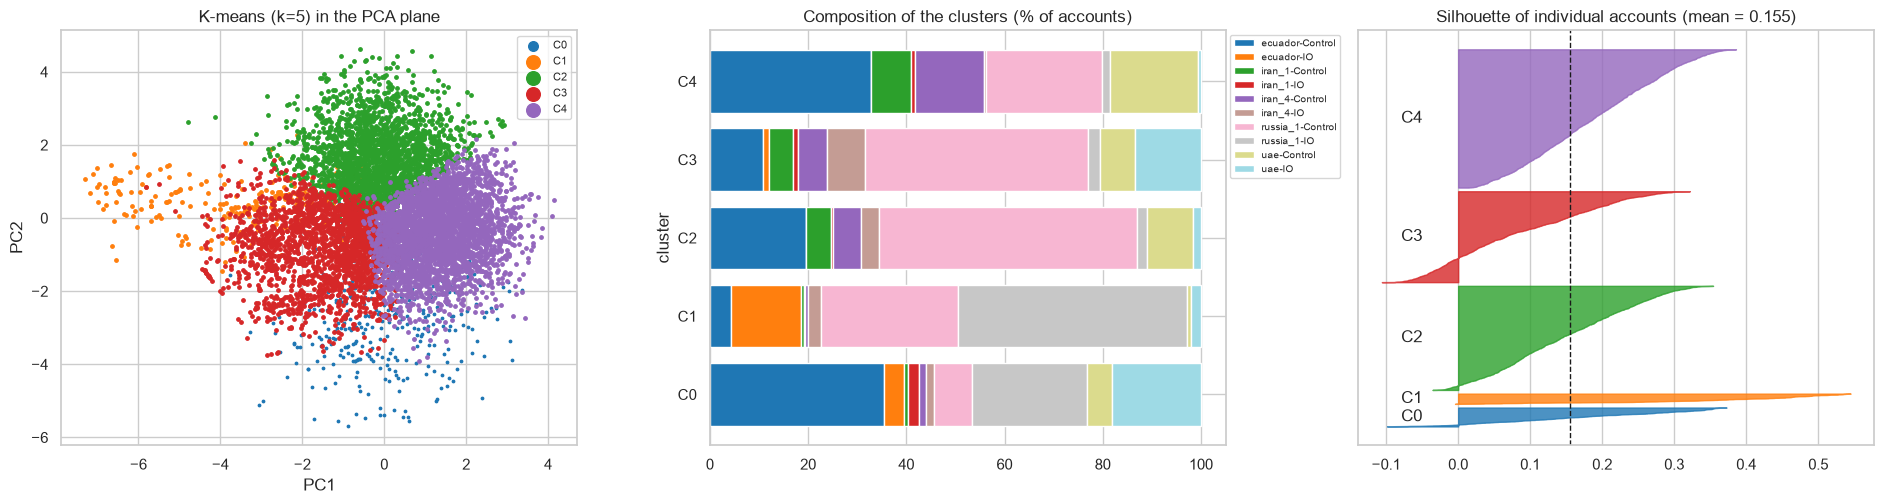

Average silhouette per cluster: {'C0': 0.169, 'C1': 0.362, 'C2': 0.148, 'C3': 0.082, 'C4': 0.19}


In [47]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
scatter_pca(labels_km, f'{km_name} in the PCA plane', axes[0])
op_class = (data['ioCountry'].astype(str) + '-' + data['class'].astype(str)).rename('operation-class')
comp = pd.crosstab(cluster_names(labels_km).set_axis(data.index).rename('cluster'), op_class, normalize='index') * 100
comp.plot(kind='barh', stacked=True, ax=axes[1], colormap='tab20', width=0.8, legend=False)
axes[1].set_title('Composition of the clusters (% of accounts)')
axes[1].legend(bbox_to_anchor=(1.0, 1.0), fontsize=7)
sil_idx = rng.choice(len(X), size=5000, replace=False)
sil_vals = silhouette_samples(X[sil_idx], labels_km[sil_idx])
y0 = 0
for c in range(K_BEST):
    v = np.sort(sil_vals[labels_km[sil_idx] == c])
    axes[2].fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=plt.cm.tab10(c), alpha=0.8)
    axes[2].text(-0.05, y0 + len(v) / 2, f'C{c}', ha='right', va='center')
    y0 += len(v) + 50
axes[2].axvline(sil_vals.mean(), color='k', ls='--', lw=1)
axes[2].set_title(f'Silhouette of individual accounts (mean = {sil_vals.mean():.3f})')
axes[2].set_yticks([])
plt.tight_layout()
plt.show()
print('Average silhouette per cluster:',
      pd.Series(sil_vals).groupby(labels_km[sil_idx]).mean().rename(lambda c: f'C{c}').round(3).to_dict())

In [48]:
# Activity/time features (NOT used for clustering) inside every cluster, for interpretation only
display(data.groupby(cluster_names(labels_km).to_numpy())[
    ['n_posts', 'active_days', 'max_day_share', 'hour_entropy', 'mentions_per_post', 'n_languages', 'n_apps']]
    .median().round(2))

,n_posts,active_days,max_day_share,hour_entropy,mentions_per_post,n_languages,n_apps
C0,83.5000,3.0000,0.5000,0.6200,1.0900,3.0000,2.0000
C1,80.0000,5.0000,0.4400,0.5900,0.0600,3.0000,1.0000
C2,32.0000,1.0000,1.0000,0.5200,0.7800,3.0000,2.0000
C3,37.0000,1.0000,1.0000,0.5600,0.3600,2.0000,1.0000
C4,40.0000,1.0000,1.0000,0.4800,1.1300,2.0000,1.0000


**Interpretation of the K-means clusters** (medians in original units in the table above):

| Cluster | Size | % IO | Profile | Label |
|---|---|---|---|---|
| C4 | 40% | 4% | oldest accounts (≈3.6 years), ≈1.2k followers / 1.2k following, complete biographies, repost-oriented (≈80% reposts) with hashtags and links, the longest written texts (≈95 characters) | **established organic users** |
| C2 | 28% | 8% | ≈27% of the posts are replies, the most multilingual cluster, ≈700 followers, ≈2 years old, short written texts; 55% of its accounts are Russian | **conversational users** |
| C3 | 24% | 26% | ≈60 followers and following, ≈4 months old, short biographies, many hashtags (≈1.1 per post), few reposts; holds **44% of all IO accounts** | **low-profile young accounts** |
| C0 | 5% | 50% | ≈91% reposts, ≈40% of the posts are reposts of *other accounts of the same operation*, the highest mean client entropy, ≈11 months old, ≈145 followers; Ecuador, Russia and UAE | **network amplifiers** (coordinated retweeting) |
| C1 | 3% | 66% | no reposts, **≈64% of the posts are verbatim copies** of texts published by other accounts of the operation, no biography; 75% Russia | **copy-paste broadcasters** |

* The structure is **not random**: the SSE of the real data is ≈16% lower than on randomised data with the same
  marginal distributions ([VAL] pp. 21–22), but the low silhouettes show that, apart from C1 (silhouette ≈ 0.36),
  the clusters are partitions of a continuum rather than well-separated groups ([KM] pp. 10–16: K-means always
  returns k convex groups).
* The two smallest clusters (C0, C1) are **IO-dominated** and correspond to two known coordination strategies:
  retweet networks and copy-pasta. IO accounts are nevertheless spread over all the clusters (44% look like
  low-profile young accounts, 15% like conversational users, 11% like established users): IO behaviour is a **mix of
  strategies**, several of which resemble those of genuine users. Overall the class entropy drops only from 0.60 to
  0.48 bits and the purity rises only from 0.855 (all accounts in one cluster) to 0.864.
* The activity/time features (not used for clustering) confirm the picture: C0 and C1 accounts have more active days
  and lower daily concentration, i.e. the full timelines typical of IO accounts.
* Biographies shared with other accounts of the same operation (1.5.4, not used for clustering) are most frequent
  among the copy-paste broadcasters C1 (9.3% of the accounts, against 1–5% in the other clusters): the accounts that
  copy their posts also tend to copy their profile.

### 2.2.4 K-means inside each operation [Q&A Q7]

Clustering can also be applied to each group of users separately; the result then describes something different
(behavioural styles *within* one operation). We run K-means (random initial centroids, 10 runs) on the accounts of every
operation, on the same standardised attributes, choose k in 2..8 with the silhouette, and compare the result with the
global K-means restricted to the same accounts.

In [49]:
op_rows, op_best = [], {}
for op in data['ioCountry'].cat.categories:
    pos = np.flatnonzero(data['ioCountry'].to_numpy() == op)
    Xo = X[pos]
    best = None
    for k in range(2, 9):
        km_o = KMeans(n_clusters=k, init='random', n_init=10, random_state=RANDOM_STATE).fit(Xo)
        s = silhouette_score(Xo, km_o.labels_, sample_size=min(5000, len(pos)), random_state=RANDOM_STATE)
        if best is None or s > best[1]:
            best = (k, s, km_o.labels_)
    k_o, s_o, lab_o = best
    op_best[op] = (pos, lab_o)
    io = data['class'].to_numpy()[pos] == 'IO'
    cls_o = np.where(io, 'IO', 'Control')
    own_share = pd.Series(io).groupby(lab_o).mean()
    glob_share = pd.Series(io).groupby(labels_km[pos]).mean()
    op_rows.append({
        'operation': op, 'accounts': len(pos), '% IO': 100 * io.mean(), 'k (max silhouette)': k_o, 'silhouette': s_o,
        'class entropy – own': entropy_purity(lab_o, cls_o)[0],
        'class entropy – global K-means': entropy_purity(labels_km[pos], cls_o)[0],
        '% IO in IO-majority clusters – own': 100 * io[pd.Series(lab_o).map(own_share).to_numpy() > 0.5].sum() / io.sum(),
        '% IO in IO-majority clusters – global': 100 * io[pd.Series(labels_km[pos]).map(glob_share).to_numpy() > 0.5].sum() / io.sum(),
        'IO-majority global clusters': ', '.join(f'C{c}' for c in glob_share.index[glob_share > 0.5]) or '–',
        'max % IO of a cluster – own': 100 * own_share.max()})
display(pd.DataFrame(op_rows).set_index('operation').round(3))

# The most IO-dominated cluster of every operation (medians in original units)
rows = []
for op, (pos, lab_o) in op_best.items():
    io = data['class'].to_numpy()[pos] == 'IO'
    share = pd.Series(io).groupby(lab_o).mean()
    c = share.idxmax()
    m = lab_o == c
    med = feat.iloc[pos[m]].median()
    rows.append({'operation': op, 'size': int(m.sum()), '% IO': 100 * share[c],
                 '% of the IO accounts of the operation': 100 * io[m].sum() / io.sum(),
                 'repost_ratio': med['repost_ratio'], 'reply_ratio': med['reply_ratio'],
                 'in_network_repost_ratio': med['in_network_repost_ratio'], 'dup_text_share': med['dup_text_share'],
                 'app_entropy': med['app_entropy'], 'hashtags_per_post': 10 ** med['log_hashtags_per_post'] - 1,
                 'follower_count': 10 ** med['log_followers'] - 1, 'account_age_days': 10 ** med['log_account_age'] - 1,
                 '% shared bio': 100 * data['shared_desc'].to_numpy()[pos[m]].mean()})
display(pd.DataFrame(rows).set_index('operation').round(3))

,accounts,% IO,k (max silhouette),silhouette,class entropy – own,class entropy – global K-means,% IO in IO-majority clusters – own,% IO in IO-majority clusters – global,IO-majority global clusters,max % IO of a cluster – own
operation,,,,,,,,,,
ecuador,16633,4.2750,3,0.1920,0.2160,0.1530,0.0000,38.8190,C1,10.0890
iran_1,4601,13.4750,2,0.1750,0.5560,0.5260,0.0000,13.0650,C0,20.6100
iran_4,8244,26.7100,2,0.1870,0.4690,0.5950,96.5940,63.3970,"C0, C1, C3",61.7060
russia_1,28100,10.7400,3,0.1810,0.4230,0.3390,30.5830,57.4880,"C0, C1",62.4490
uae,11533,29.9400,2,0.1880,0.3650,0.5430,98.2330,85.4330,"C0, C1, C3",74.7470


,size,% IO,% of the IO accounts of the operation,repost_ratio,reply_ratio,in_network_repost_ratio,dup_text_share,app_entropy,hashtags_per_post,follower_count,account_age_days,% shared bio
operation,,,,,,,,,,,,
ecuador,1239,10.0890,17.5810,1.0000,0.0000,0.5420,0.0000,0.0000,1.0000,124.0000,598.9900,2.2600
iran_1,1509,20.6100,50.1610,0.1490,0.0000,0.0000,0.0000,0.0000,1.8890,195.0000,284.7630,1.8560
iran_4,3447,61.7060,96.5940,0.2000,0.1100,0.0000,0.0000,0.0000,0.5000,85.0000,118.2290,11.1400
russia_1,1478,62.4490,30.5830,0.0000,0.0000,0.0000,0.6010,0.0000,0.6760,69.0000,225.7000,10.5550
uae,4538,74.7470,98.2330,0.4220,0.0390,0.0280,0.0090,0.4910,1.2720,62.0000,48.3270,7.2940


**Interpretation of the clusterings per operation.**

* Inside each operation the silhouette selects only 2–3 clusters (silhouette 0.175–0.192, slightly higher than the 0.151
  of the global clustering, because each operation is more homogeneous).
* In **Iran_4** and **UAE** the clustering of the operation separates the IO accounts best: a single cluster holds
  97–98% of the IO accounts of the operation (62% and 75% IO; class entropy 0.47 and 0.37 bits, against 0.60 and 0.54
  for the global clustering restricted to the same accounts). Its accounts are young (median ≈4 months in Iran_4,
  ≈1.5 months in UAE) and have few followers (≈60–85); in UAE they also repost more (≈42% of the posts) and use more
  than one client. The global clustering also works well here (63% and 85% of the IO accounts in clusters that are
  IO-majority inside the operation: amplifiers, copy-paste and low-profile young accounts), but it needs three
  clusters for what the operation-level clustering captures with one.
* In **Russia** the most IO-dominated cluster of the operation is the copy-paste group (median 60% duplicated texts,
  62% IO), but it holds only 31% of the Russian IO accounts, while the global clustering puts 57% of them in
  IO-majority clusters: the network amplifiers C0 and the copy-paste broadcasters C1.
* In **Ecuador** and **Iran_1**, where IO accounts are a small minority (4% and 13% of the profiles), no cluster of the
  operation has an IO majority (at most 10% and 21% IO): with only 2–3 clusters the small coordinated groups are
  merged with ordinary accounts. The global clustering isolates them better, because it groups them with similar
  accounts of other operations: 39% of the Ecuadorian IO accounts fall in the copy-paste cluster C1 and 13% of the
  Iran_1 IO accounts in the amplifier cluster C0, both IO-majority among the accounts of their operation.
* The two analyses are therefore complementary [Q&A Q7]: the global clustering finds the coordination behaviours shared
  by several operations (amplifiers, copy-paste broadcasters), the clustering of a single operation follows the main
  differences inside that operation – for Iran_4 and UAE, account age and audience, which separate IO accounts from
  the control accounts of the same country (consistently with Task 1, where IO accounts are younger and less followed).

## 2.3 Density-based clustering: DBSCAN

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| DBSCAN: density, Eps, MinPts (point itself counted), core / border / noise points | [DBSCAN] pp. 2–8 |
| When DBSCAN works / does not work (varying densities, high dimensionality) | [DBSCAN] pp. 9–10 |
| Choice of Eps and MinPts with the sorted k-th nearest-neighbour distance plot | [DBSCAN] p. 11 |
| Stratified sampling (representative sample) | [DP] pp. 9–13 |
| Density-based clusters | [CL-INTRO] p. 14 |
| Internal (SSE, silhouette) and external (entropy, purity) validity | [VAL] pp. 14–20 |

DBSCAN computes the Eps-neighbourhood of every point; to keep memory and time under control it is run on a
**stratified random sample of 20,000 accounts**: the accounts are split into the 10 strata operation × class and
the same fraction (20,000 / 69,111 ≈ 29%) is drawn at random, without replacement, from every stratum
([DP] pp. 9–13), so that the sample keeps the proportions of operations and classes of the whole set. The cost
of the neighbourhoods, and the stability of the result on other samples, are measured below. We proceed in three
steps:

1. **k-distance plots** ([DBSCAN] p. 11): for MinPts = k, the distance of every point to its k-th nearest
   neighbour (the point itself included, as in the definition of a core point) is sorted; the sharp increase
   ("knee") separates points inside dense regions from noise;
2. a **grid search** on (Eps, MinPts) recording number of clusters, noise share, size of the largest cluster and
   silhouette (noise excluded);
3. the same analysis on **other sets of input attributes** [Q&A Q11, Q12], before deciding on the final configuration.

**The three values of MinPts.** The slides choose Eps from the plot of the distance of every point to its $k$-th
nearest neighbour, with $k$ = MinPts ([DBSCAN] p. 11), and use small values (MinPts = 4–7) on two-dimensional
examples. In 13 dimensions points are farther apart and more neighbours are needed to call a region dense, so we
examine three levels: **10** (a low threshold that reveals the finest structure), **26** = 2 × the number of
attributes (a common rule of thumb for MinPts) and **50** ≈ 4 × the number of attributes (a strict threshold:
only regions where every core point has at least 50 accounts within Eps). For each MinPts, Eps is read where its
own $k$-distance curve bends (the "knee"): we take the point of the sorted curve farthest from the straight line
joining its first and last point, which is where the curve switches from slow growth (points inside dense regions)
to the steep final part (isolated points).

### 2.3.1 k-distance plots and grid search on the 13 attributes

In [50]:
db_idx = np.sort(data.groupby(['ioCountry', 'class'], observed=True)
                 .sample(frac=20_000 / len(data), random_state=RANDOM_STATE).index.to_numpy())
Xd = X[db_idx]
print('DBSCAN sample:', Xd.shape, data.loc[db_idx, 'class'].value_counts().to_dict())
strata = pd.DataFrame({'all accounts': data.groupby(['ioCountry', 'class'], observed=True).size(),
                       'DBSCAN sample': data.loc[db_idx].groupby(['ioCountry', 'class'], observed=True).size()})
strata['% of all accounts'] = 100 * strata['all accounts'] / strata['all accounts'].sum()
strata['% of the sample'] = 100 * strata['DBSCAN sample'] / strata['DBSCAN sample'].sum()
display(strata.round(2).T)

DBSCAN sample: (19998, 13) {'Control': 17104, 'IO': 2894}


ioCountry          ecuador               iran_1                iran_4              russia_1                    uae           
class                   IO     Control       IO    Control         IO    Control         IO     Control         IO    Control
all accounts      711.0000 15,922.0000 620.0000 3,981.0000 2,202.0000 6,042.0000 3,018.0000 25,082.0000 3,453.0000 8,080.0000
DBSCAN sample     206.0000  4,608.0000 179.0000 1,152.0000   637.0000 1,748.0000   873.0000  7,258.0000   999.0000 2,338.0000
% of all accounts   1.0300     23.0400   0.9000     5.7600     3.1900     8.7400     4.3700     36.2900     5.0000    11.6900
% of the sample     1.0300     23.0400   0.9000     5.7600     3.1900     8.7400     4.3700     36.2900     5.0000    11.6900

In [51]:
# Why a sample: DBSCAN needs the Eps-neighbourhood of every point. Size of the neighbourhoods (pairs of points closer
# than Eps), memory needed to store them (8 bytes per neighbour index) and time, on samples of growing size
cost_rows = []
for n_s in [5_000, 10_000, len(Xd)]:
    sub = Xd[np.random.default_rng(0).choice(len(Xd), n_s, replace=False)]
    nn_s = NearestNeighbors().fit(sub)
    for eps in [1.6, 2.5]:
        t0 = time.time()
        nb = nn_s.radius_neighbors(sub, radius=eps, return_distance=False)
        n_pairs = int(sum(len(a) for a in nb))
        cost_rows.append({'accounts': f'{n_s:,}', 'Eps': eps, 'neighbour pairs (millions)': n_pairs / 1e6,
                          'mean neighbourhood size': n_pairs / n_s, 'memory of the lists (GB)': n_pairs * 8 / 1e9,
                          'time (s)': time.time() - t0})
        del nb
    if n_s == len(Xd):
        for eps in [1.6, 2.5]:
            n_pairs = [r for r in cost_rows if r['accounts'] == f'{len(Xd):,}' and r['Eps'] == eps][0]['neighbour pairs (millions)']
            est = n_pairs * (len(X) / len(Xd)) ** 2             # pairs grow with the square of the number of points
            cost_rows.append({'accounts': f'{len(X):,} (estimate)', 'Eps': eps, 'neighbour pairs (millions)': est,
                              'mean neighbourhood size': est * 1e6 / len(X), 'memory of the lists (GB)': est * 8e6 / 1e9,
                              'time (s)': np.nan})
display(pd.DataFrame(cost_rows).set_index(['accounts', 'Eps']).round(2))
del sub, nn_s

neighbour pairs (millions)  mean neighbourhood size  memory of the lists (GB)  time (s)
accounts          Eps                                                                                            
5,000             1.6000                      0.0700                  13.4900                    0.0000    0.4600
                  2.5000                      0.8000                 160.0300                    0.0100    0.5800
10,000            1.6000                      0.2700                  26.6700                    0.0000    1.6300
                  2.5000                      3.2800                 327.9300                    0.0300    2.2900
19,998            1.6000                      1.0200                  51.0300                    0.0100    6.0600
                  2.5000                     12.8500                 642.6400                    0.1000    9.5400
69,111 (estimate) 1.6000                     12.1900                 176.3500                    0.1000       NaN
                  2.5000                    153.4900               2,220.8900                    1.2300       NaN

**Why a sample, and is it representative?** The table shows the cost: the number of neighbour pairs grows with the
square of the number of accounts. On the 19,998-account sample, Eps = 2.5 (the upper end of the grid) already gives
12.9 million pairs (642 neighbours per account) and takes about 10 s on this machine; on all 69,111 accounts the same
run would produce
≈154 million pairs (1.2 GB of index lists alone) and take roughly 12 times longer – for each of the 67 configurations
of the parameter study below (27 on the 13 attributes, 40 on other attribute sets), i.e. hours instead of minutes.
The sample is stratified: its composition is exactly that of the whole set (first table: every stratum operation ×
class has the same share). The density threshold depends on the size of the data: with 3.46 times more accounts an
Eps-neighbourhood contains about 3.46 times more points, so MinPts = 50 on the sample corresponds to MinPts ≈ 173 on
all the accounts. Whether the result depends on the particular sample is checked after the final model (2.3.3), by
repeating DBSCAN on four other stratified samples.

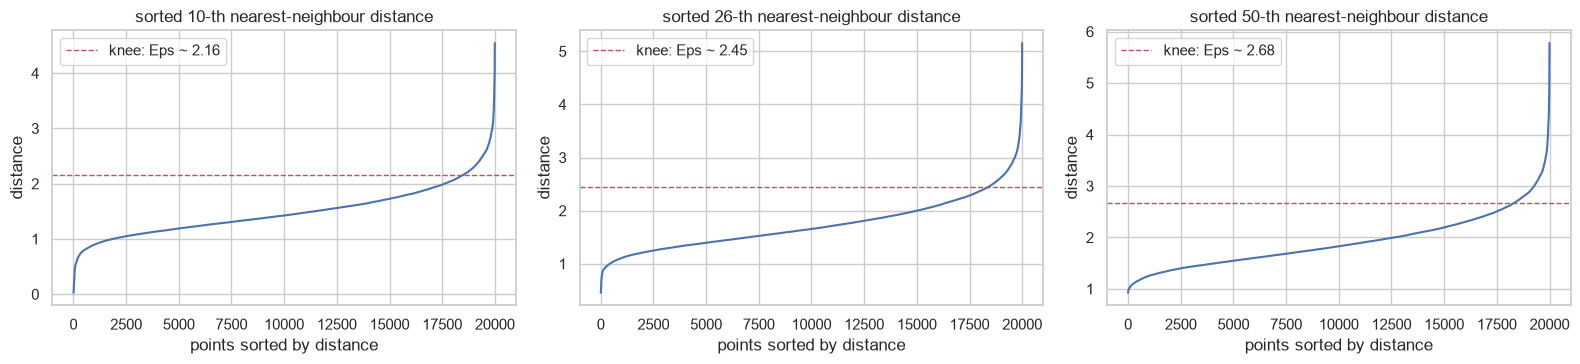

Knee of the k-distance curves: {10: 2.159, 26: 2.453, 50: 2.676}


In [52]:
def knee_point(y):
    """Index of the point of a sorted curve with the largest distance from the chord joining its extremes."""
    x = np.linspace(0, 1, len(y))
    yn = (y - y.min()) / (y.max() - y.min())
    return int(np.argmax(np.abs(yn - x)))


MIN_PTS_GRID = [10, 26, 50]            # 26 = 2 x number of attributes (a common rule of thumb)
fig, axes = plt.subplots(1, len(MIN_PTS_GRID), figsize=(16, 3.8))
knees = {}
for ax, mp in zip(axes, MIN_PTS_GRID):
    dist, _ = NearestNeighbors(n_neighbors=mp).fit(Xd).kneighbors(Xd)
    kd = np.sort(dist[:, -1])
    kn = knee_point(kd)
    knees[mp] = kd[kn]
    ax.plot(kd)
    ax.axhline(kd[kn], color='r', ls='--', lw=1, label=f'knee: Eps ~ {kd[kn]:.2f}')
    ax.set_title(f'sorted {mp}-th nearest-neighbour distance')
    ax.set_xlabel('points sorted by distance')
    ax.set_ylabel('distance')
    ax.legend()
plt.tight_layout()
plt.show()
print('Knee of the k-distance curves:', {k: round(float(v), 3) for k, v in knees.items()})

,MinPts,Eps,clusters,noise %,largest cluster %,silhouette (no noise),% IO in noise
0,10,0.8000,29,94.4690,1.9050,0.4400,13.5720
1,10,1.0000,61,80.1230,8.2260,0.1420,13.2560
2,10,1.2000,37,54.3650,39.1090,-0.1390,14.1740
3,10,1.4000,27,31.6080,64.7610,-0.1110,15.8360
4,10,1.6000,13,16.2270,82.7680,0.0690,17.6890
5,10,1.8000,5,8.1510,91.2490,0.1700,19.9390
6,10,2.0000,3,3.8550,95.9750,0.2300,19.5850
7,10,2.2000,1,1.9000,98.1000,NaN,18.1580
8,10,2.5000,1,0.6950,99.3050,NaN,11.5110
9,26,0.8000,4,99.0900,0.3550,0.7550,14.4080


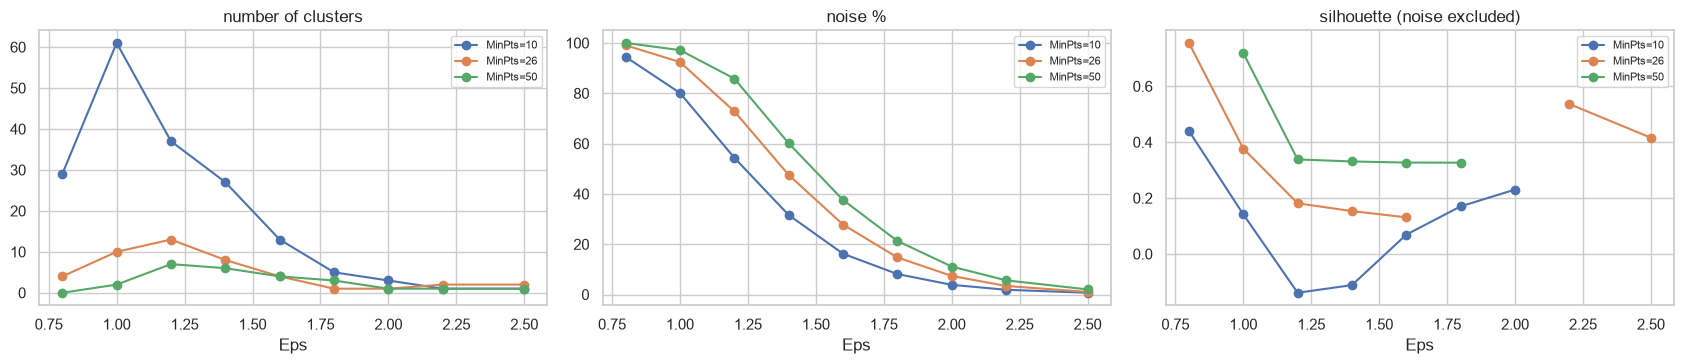

In [53]:
EPS_GRID = [0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.5]
db_rows = []
for mp in MIN_PTS_GRID:
    for eps in EPS_GRID:
        lab = DBSCAN(eps=eps, min_samples=mp).fit_predict(Xd)
        sizes = pd.Series(lab[lab >= 0]).value_counts()
        sc = internal_scores(Xd, lab, sample=5000)
        db_rows.append({'MinPts': mp, 'Eps': eps, 'clusters': len(sizes), 'noise %': 100 * (lab == -1).mean(),
                        'largest cluster %': 100 * sizes.max() / len(lab) if len(sizes) else 0,
                        'silhouette (no noise)': sc['silhouette'],
                        '% IO in noise': 100 * data.loc[db_idx[lab == -1], 'class'].eq('IO').mean()
                        if (lab == -1).any() else np.nan})
db_grid = pd.DataFrame(db_rows)
display(db_grid.round(3))
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for mp in MIN_PTS_GRID:
    d = db_grid[db_grid['MinPts'] == mp]
    for ax, col in zip(axes, ['clusters', 'noise %', 'silhouette (no noise)']):
        ax.plot(d['Eps'], d[col], marker='o', label=f'MinPts={mp}')
for ax, t in zip(axes, ['number of clusters', 'noise %', 'silhouette (noise excluded)']):
    ax.set_title(t)
    ax.set_xlabel('Eps')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 2.3.2 Other sets of input attributes [Q&A Q11, Q12]

The Q&A asks to try different parameters **and** different input features before concluding whether DBSCAN works.
Besides the 13 attributes we test two subsets (feature subset selection, [DP] pp. 14–19) and a projection on the first
principal components (dimensionality reduction against the curse of dimensionality, [DP] pp. 15–16, 49–61):

* **BEHAVIOUR (9)** – interaction and content attributes only, without the account attributes;
* **COORDINATION (6)** – reposting, in-network reposting, copied texts, client diversity, followers, account age;
* **PCA (5)** – the first five principal components of the 13 attributes.

Distances have different scales in different spaces, so for every set Eps is expressed as a fraction of the knee of
its own k-distance curve (MinPts = 2 × number of dimensions, and 50). Besides the internal measures, the table reports
– as an external check – how many clusters contain ≥ 90% IO accounts (with ≥ 20 accounts) and which share of all the IO
accounts of the sample they hold.

In [54]:
FEATURE_SETS = {
    'ALL (13)': CLUSTER_FEATURES,
    'BEHAVIOUR (9)': ['repost_ratio', 'reply_ratio', 'in_network_repost_ratio', 'dup_text_share', 'log_hashtags_per_post',
                      'urls_per_post', 'log_mean_text_len', 'lang_entropy', 'app_entropy'],
    'COORDINATION (6)': ['repost_ratio', 'in_network_repost_ratio', 'dup_text_share', 'app_entropy', 'log_followers',
                         'log_account_age'],
}
col_pos = {c: i for i, c in enumerate(CLUSTER_FEATURES)}
fs_mats = {name: Xd[:, [col_pos[c] for c in cols]] for name, cols in FEATURE_SETS.items()}
pca5 = PCA(n_components=5, random_state=RANDOM_STATE).fit(X)
fs_mats['PCA (5)'] = pca5.transform(Xd)
print(f'The first 5 principal components explain {100 * pca5.explained_variance_ratio_.sum():.1f}% of the variance')
io_d = data['class'].to_numpy()[db_idx] == 'IO'
fs_rows = []
for name, M in fs_mats.items():
    for mp in sorted({2 * M.shape[1], 50}):
        kd = np.sort(NearestNeighbors(n_neighbors=mp).fit(M).kneighbors(M)[0][:, -1])
        knee = kd[knee_point(kd)]
        for frac in [0.5, 0.6, 0.7, 0.8, 1.0]:
            lab = DBSCAN(eps=knee * frac, min_samples=mp).fit_predict(M)
            sizes = pd.Series(lab[lab >= 0]).value_counts()
            dense_io = [c for c in sizes.index if sizes[c] >= 20 and io_d[lab == c].mean() >= 0.9]
            m = lab >= 0
            fs_rows.append({
                'feature set': name, 'MinPts': mp, 'Eps / knee': frac, 'Eps': knee * frac, 'clusters': len(sizes),
                'noise %': 100 * (lab == -1).mean(), 'largest cluster %': 100 * sizes.max() / len(lab) if len(sizes) else 0,
                'silhouette (no noise)': silhouette_score(M[m], lab[m], sample_size=min(4000, int(m.sum())),
                                                          random_state=RANDOM_STATE) if len(sizes) > 1 else np.nan,
                'clusters with >= 90% IO': len(dense_io),
                '% of IO accounts in them': 100 * sum(io_d[lab == c].sum() for c in dense_io) / io_d.sum()})
fs_eval = pd.DataFrame(fs_rows)
display(fs_eval.round(3))
display(fs_eval.groupby('feature set', sort=False).agg(
    best_silhouette=('silhouette (no noise)', 'max'), max_clusters_with_90pct_IO=('clusters with >= 90% IO', 'max'),
    max_share_of_IO_in_them=('% of IO accounts in them', 'max'), min_noise_pct=('noise %', 'min')).round(3))

The first 5 principal components explain 63.3% of the variance


,feature set,MinPts,Eps / knee,Eps,clusters,noise %,largest cluster %,silhouette (no noise),clusters with >= 90% IO,% of IO accounts in them
0,ALL (13),26,0.5000,1.2270,11,69.2570,23.9370,0.1840,5,13.6140
1,ALL (13),26,0.6000,1.4720,6,39.6740,57.7510,0.1120,5,17.6230
2,ALL (13),26,0.7000,1.7170,4,19.2920,79.1980,0.0590,1,7.8090
3,ALL (13),26,0.8000,1.9630,2,8.4260,91.4040,0.1770,1,1.1750
4,ALL (13),26,1.0000,2.4530,2,1.2000,98.7000,0.4110,1,0.6570
5,ALL (13),50,0.5000,1.3380,8,68.6670,26.2030,0.1580,4,8.8460
6,ALL (13),50,0.6000,1.6060,4,37.0140,60.9460,0.3320,3,13.9250
7,ALL (13),50,0.7000,1.8730,3,17.0520,80.9530,0.3110,2,13.2000
8,ALL (13),50,0.8000,2.1410,1,6.8110,93.1890,NaN,0,0.0000
9,ALL (13),50,1.0000,2.6760,2,0.9600,98.7500,0.5240,0,0.0000


,best_silhouette,max_clusters_with_90pct_IO,max_share_of_IO_in_them,min_noise_pct
feature set,,,,
ALL (13),0.5240,5,17.6230,0.9600
BEHAVIOUR (9),0.5540,3,7.2910,1.7000
COORDINATION (6),0.5910,4,10.2970,5.4160
PCA (5),0.4840,3,7.5330,1.3050


**Result of the experiment with other input attributes.**

* No input set makes the bulk of the accounts separable: for every set, an Eps close to the knee gives one giant
  cluster (> 90% of the accounts), and smaller values fragment the data into small groups and noise – the same
  behaviour as with the 13 attributes.
* The reduced sets reach higher silhouettes (up to 0.55 for BEHAVIOUR and 0.59 for COORDINATION, against 0.52 for ALL),
  but only because one small group is cut off from one big cluster; their dense groups contain fewer IO accounts (at
  most 7–10% of all the IO accounts in clusters with ≥ 90% IO, against 18% with all the attributes). The PCA projection
  gives 7.5%: the first five components keep 63% of the variance but lose part of the information that distinguishes
  the coordinated groups.
* Removing attributes or dimensions therefore does not help DBSCAN: the difficulty is not mainly the number of
  dimensions but the structure of the data – one dense continuum that contains small, much denser groups. The **13
  attributes are kept** for DBSCAN too, as for the other methods [Q&A Q11].

### 2.3.3 Final configuration

**Choice of the parameters.**

* The knees of the k-distance curves (Eps ≈ 2.2–2.7) are where almost every account becomes a core point: with these
  values DBSCAN returns one giant cluster (> 90% of the accounts) and at most a couple of tiny ones – the accounts
  form one continuous dense region, as already suggested by K-means.
* Small values of Eps (≤ 1.2) fragment the data into many micro-clusters and most accounts become noise.
* In between, **MinPts = 50, Eps = 1.6** gives a stable and interpretable solution: one main cluster plus a few small
  but **very dense** groups that are separated from it (with Eps = 1.8 one of them already merges into the main
  cluster). A large MinPts (≈4 × the number of attributes) guarantees that these groups are really dense regions and
  not chance agglomerations; the price is a large share of noise. As warned in [DBSCAN] p. 10, regions of very
  different density make a single Eps a compromise, and 2.3.2 shows that fewer dimensions do not remove it.
* In the terms of 2.3.2 this configuration is Eps ≈ 0.6 × knee, the region of the grid where the almost purely IO
  groups appear (with MinPts = 50: three groups with ≈14% of the IO accounts; with MinPts = 26 there are five, with
  ≈18%). We keep MinPts = 50, i.e. the stricter definition of a dense region.

Point types ([DBSCAN] p. 2): {'noise': 7517, 'border': 6528, 'core': 5953}
DBSCAN (Eps=1.6, MinPts=50): 4 clusters | total class entropy = 0.418 bits, purity = 0.915 (noise excluded)


,size,size %,IO accounts,control accounts,% IO,% ecuador,% iran_1,% iran_4,% russia_1,% uae,% of all IO accounts,% shared bio,class entropy,class purity
C0,12082,60.4160,1060,11022,8.7730,25.2940,7.0930,13.6480,36.5670,17.3980,36.6280,1.8710,0.4290,0.9120
C1,134,0.6700,134,0,100.0000,0.0000,0.0000,0.0000,100.0000,0.0000,4.6300,0.7460,-0.0000,1.0000
C2,198,0.9900,195,3,98.4850,0.0000,0.0000,2.0200,97.9800,0.0000,6.7380,16.6670,0.1130,0.9850
C3,67,0.3350,65,2,97.0150,4.4780,0.0000,0.0000,1.4930,94.0300,2.2460,5.9700,0.1940,0.9700
noise,7517,37.5890,1440,6077,19.1570,23.3470,6.3060,9.7380,45.0180,15.5910,49.7580,2.4880,0.7050,0.8080


Medians of the attributes in every cluster (original units):


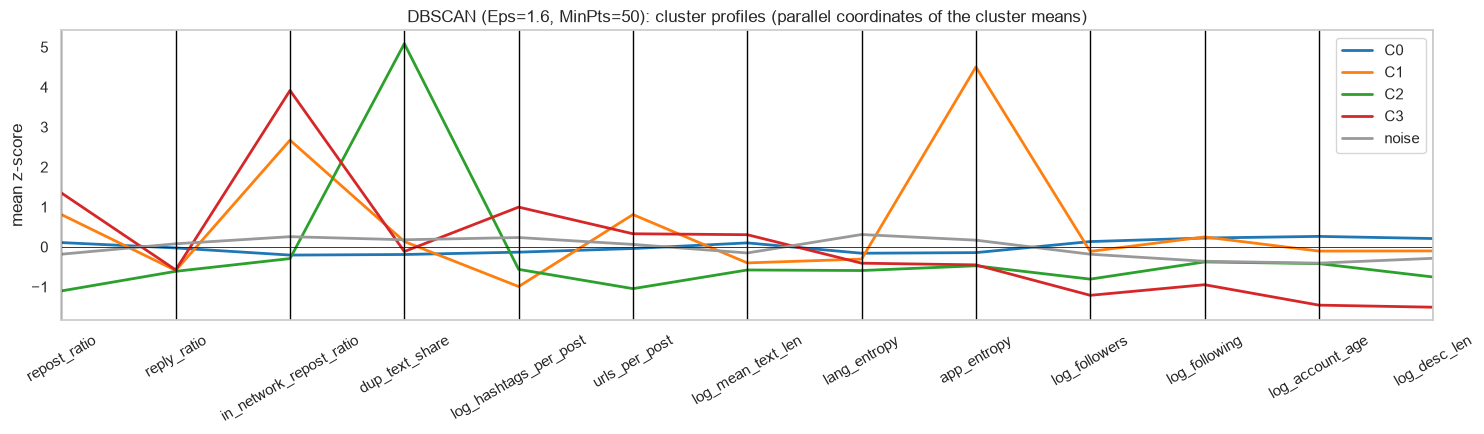

,repost_ratio,reply_ratio,in_network_repost_ratio,dup_text_share,hashtags_per_post,urls_per_post,mean_text_len,lang_entropy,app_entropy,follower_count,following_count,account_age_days,desc_len
C0,0.4610,0.0330,0.0000,0.0000,0.6870,0.5730,83.5710,0.3290,0.0000,631.0000,625.0000,917.4080,68.0000
C1,0.8080,0.0070,0.3580,0.0370,0.2340,0.9470,68.4630,0.3040,2.7250,293.9980,458.9300,401.9540,27.0000
C2,0.0000,0.0000,0.0000,0.6260,0.5130,0.1420,63.2000,0.1780,0.0000,73.4980,152.4990,221.2690,5.0000
C3,0.9780,0.0060,0.4770,0.0050,1.8950,0.7190,91.0490,0.2820,0.0000,29.0000,50.0000,53.7560,0.0000
noise,0.2270,0.0020,0.0000,0.0000,1.0000,0.5870,76.7220,0.5390,0.0000,268.0000,203.0000,365.5770,30.0000


Contingency table DBSCAN clusters x K-means clusters (DBSCAN sample):


K-means,C0,C1,C2,C3,C4
DBSCAN,,,,,
C0,38,0,3684,2087,6273
C1,133,0,1,0,0
C2,0,198,0,0,0
C3,67,0,0,0,0
noise,780,365,2012,2771,1589


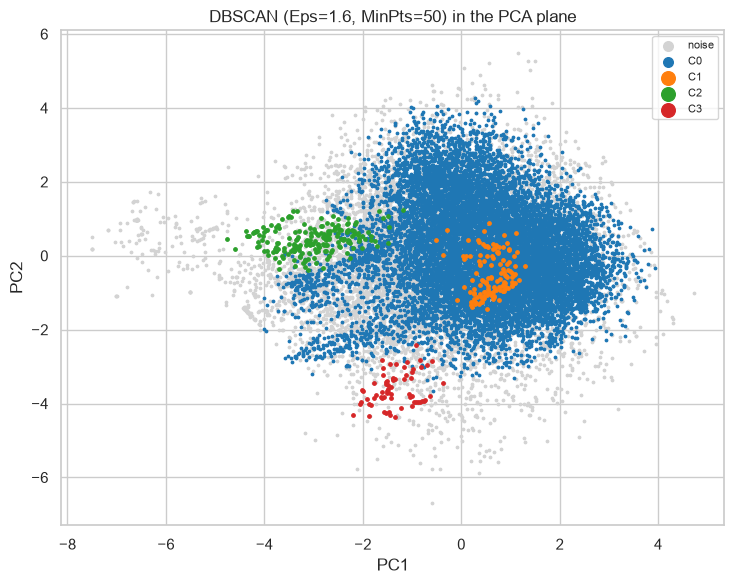

In [55]:
DB_EPS, DB_MIN_PTS = 1.6, 50
dbscan = DBSCAN(eps=DB_EPS, min_samples=DB_MIN_PTS).fit(Xd)
labels_db_sample = dbscan.labels_
is_core = np.zeros(len(Xd), dtype=bool)
is_core[dbscan.core_sample_indices_] = True
point_type = np.where(is_core, 'core', np.where(labels_db_sample == -1, 'noise', 'border'))
print('Point types ([DBSCAN] p. 2):', pd.Series(point_type).value_counts().to_dict())
labels_db = np.full(len(data), -2)          # -2 = account not in the DBSCAN sample
labels_db[db_idx] = labels_db_sample
db_name = f'DBSCAN (Eps={DB_EPS}, MinPts={DB_MIN_PTS})'
display(cluster_summary(labels_db_sample, db_name, idx=db_idx))
print('Medians of the attributes in every cluster (original units):')
display(cluster_profiles(labels_db_sample, db_name, idx=db_idx))
print('Contingency table DBSCAN clusters x K-means clusters (DBSCAN sample):')
display(pd.crosstab(cluster_names(labels_db_sample).rename('DBSCAN'),
                    cluster_names(labels_km[db_idx]).rename('K-means')))
fig, ax = plt.subplots(figsize=(7.5, 6))
scatter_pca(labels_db_sample, f'{db_name} in the PCA plane', ax, idx=db_idx)
plt.tight_layout()
plt.show()

In [56]:
# Who are the noise points? Comparison of noise, main cluster and small dense clusters
dd = data.iloc[db_idx].reset_index(drop=True)
zs = pd.DataFrame(Xd, columns=CLUSTER_FEATURES)
grp_db = pd.Series(np.where(labels_db_sample == -1, 'noise',
                            np.where(labels_db_sample == 0, 'C0 (main cluster)', 'C1-C3 (small dense clusters)')))
dist_core = NearestNeighbors(n_neighbors=1).fit(Xd[is_core]).kneighbors(Xd)[0][:, 0]
noise_cmp = pd.DataFrame({
    'accounts': grp_db.value_counts(),
    '% IO': 100 * dd['class'].eq('IO').groupby(grp_db).mean(),
    'mean |z| (how atypical)': zs.abs().mean(axis=1).groupby(grp_db).median(),
    'largest |z| of the account': zs.abs().max(axis=1).groupby(grp_db).median(),
    'distance to the nearest core point': pd.Series(dist_core).groupby(grp_db).median(),
    'median posts': dd['n_posts'].groupby(grp_db).median(),
    '% shared biography': 100 * dd['shared_desc'].groupby(grp_db).mean()})
display(noise_cmp.round(3))
print(f'Eps = {DB_EPS}: a noise point is farther than Eps from every core point by definition ([DBSCAN] p. 2)')
# Which attribute makes each noise point atypical (largest |z|), and in which direction?
zn = zs[labels_db_sample == -1]
top_attr = zn.abs().idxmax(axis=1)
direction = np.where(zn.to_numpy()[np.arange(len(zn)), zn.columns.get_indexer(top_attr)] > 0, 'high', 'low')
why = (top_attr + ' (' + direction + ')').rename('most atypical attribute')
why_tab = (pd.crosstab(why, dd.loc[labels_db_sample == -1, 'class'].astype(str).to_numpy(), normalize='columns') * 100)
why_tab['all noise'] = why.value_counts(normalize=True) * 100
display(why_tab.sort_values('all noise', ascending=False).head(10).round(1))
print('Share of noise points in every operation and class (%):')
display(pd.crosstab(dd['ioCountry'], dd['class'], values=(labels_db_sample == -1), aggfunc='mean').mul(100).round(1))
del zn

,accounts,% IO,mean |z| (how atypical),largest |z| of the account,distance to the nearest core point,median posts,% shared biography
C0 (main cluster),12082,8.7730,0.6480,1.5530,0.7680,34.0000,1.8710
C1-C3 (small dense clusters),399,98.7470,1.0020,4.6010,0.7760,178.0000,9.5240
noise,7517,19.1570,0.8530,2.3800,2.2070,40.0000,2.4880


Eps = 1.6: a noise point is farther than Eps from every core point by definition ([DBSCAN] p. 2)


col_0,Control,IO,all noise
most atypical attribute,,,
log_account_age (low),9.7000,22.4000,12.2000
in_network_repost_ratio (high),8.2000,17.7000,10.0000
lang_entropy (high),11.3000,4.4000,10.0000
reply_ratio (high),10.8000,4.7000,9.7000
log_following (low),10.0000,1.6000,8.4000
app_entropy (high),7.5000,11.0000,8.2000
log_desc_len (low),7.8000,7.8000,7.8000
log_hashtags_per_post (high),9.1000,1.5000,7.6000
dup_text_share (high),3.9000,14.4000,5.9000


Share of noise points in every operation and class (%):


class,IO,Control
ioCountry,,
ecuador,90.3000,34.0000
iran_1,59.2000,31.9000
iran_4,42.5000,26.4000
russia_1,43.9000,41.3000
uae,49.4000,29.0000


In [57]:
# Is the result stable? The same DBSCAN (Eps = 1.6, MinPts = 50) on four other stratified samples of 20,000 accounts
stab_rows = []
for seed in [RANDOM_STATE, 1, 2, 3, 4]:
    idx_s = db_idx if seed == RANDOM_STATE else np.sort(
        data.groupby(['ioCountry', 'class'], observed=True).sample(frac=20_000 / len(data), random_state=seed)
        .index.to_numpy())
    lab_s = labels_db_sample if seed == RANDOM_STATE else DBSCAN(eps=DB_EPS, min_samples=DB_MIN_PTS).fit_predict(X[idx_s])
    sizes = pd.Series(lab_s[lab_s >= 0]).value_counts()
    small = []
    for c in sizes.index[1:]:
        d_ = data.iloc[idx_s[lab_s == c]]
        small.append(f"{len(d_)} acc. {100 * d_['class'].eq('IO').mean():.0f}% IO {d_['ioCountry'].value_counts().idxmax()} "
                     f"[copies {d_['dup_text_share'].median():.2f}, clients {d_['app_entropy'].median():.1f}, "
                     f"reposts {d_['repost_ratio'].median():.2f}]")
    stab_rows.append({'sample': 'main' if seed == RANDOM_STATE else f'seed {seed}', 'clusters': len(sizes),
                      'noise %': 100 * (lab_s == -1).mean(), 'largest cluster %': 100 * sizes.iloc[0] / len(lab_s),
                      '% IO in noise': 100 * (data['class'].to_numpy()[idx_s][lab_s == -1] == 'IO').mean(),
                      'shared accounts with the main sample %': 100 * len(np.intersect1d(idx_s, db_idx)) / len(idx_s),
                      'small dense clusters (size, % IO, main operation, medians)': ' | '.join(small)})
with pd.option_context('display.max_colwidth', 260):
    display(pd.DataFrame(stab_rows).set_index('sample').round(1))
del dd, zs

,clusters,noise %,largest cluster %,% IO in noise,shared accounts with the main sample %,"small dense clusters (size, % IO, main operation, medians)"
sample,,,,,,
main,4,37.6000,60.4000,19.2000,100.0000,"198 acc. 98% IO russia_1 [copies 0.63, clients 0.0, reposts 0.00] | 134 acc. 100% IO russia_1 [copies 0.04, clients 2.7, reposts 0.81] | 67 acc. 97% IO uae [copies 0.01, clients 0.0, reposts 0.98]"
seed 1,4,37.5000,58.2000,19.6000,28.8000,"518 acc. 0% IO russia_1 [copies 0.00, clients 0.0, reposts 0.00] | 211 acc. 100% IO russia_1 [copies 0.62, clients 0.0, reposts 0.00] | 141 acc. 100% IO russia_1 [copies 0.04, clients 2.8, reposts 0.80]"
seed 2,4,37.4000,60.7000,19.6000,29.0000,"189 acc. 98% IO russia_1 [copies 0.63, clients 0.0, reposts 0.00] | 133 acc. 100% IO russia_1 [copies 0.04, clients 2.7, reposts 0.82] | 50 acc. 30% IO russia_1 [copies 0.00, clients 0.0, reposts 0.00]"
seed 3,4,36.8000,61.0000,19.2000,28.9000,"232 acc. 99% IO russia_1 [copies 0.62, clients 0.0, reposts 0.00] | 136 acc. 100% IO russia_1 [copies 0.04, clients 2.7, reposts 0.82] | 72 acc. 94% IO uae [copies 0.01, clients 0.0, reposts 0.98]"
seed 4,5,37.1000,58.0000,18.7000,29.0000,"541 acc. 0% IO russia_1 [copies 0.00, clients 0.0, reposts 0.00] | 194 acc. 98% IO russia_1 [copies 0.64, clients 0.0, reposts 0.00] | 143 acc. 100% IO russia_1 [copies 0.04, clients 2.7, reposts 0.80] | 84 acc. 92% IO uae [copies 0.01, clients 0.0, repost..."


**Interpretation of the DBSCAN clusters** (19,998-account sample, 14.5% IO; 5,953 core, 6,528 border and 7,517
noise points):

| Cluster | Size | % IO | Profile |
|---|---|---|---|
| C0 | 60% | 9% | the dense **core of ordinary behaviour**: it absorbs K-means clusters C2, C3 and C4 (contingency table) |
| C1 | 134 | **100%** (Russia) | reposting accounts (≈81% reposts, ≈36% in-network) that use **many different clients** (app entropy ≈ 2.7 bits): a retweet network operated through many applications – a dense core inside K-means C0 |
| C2 | 198 | **98%** (Russia) | **copy-paste broadcasters**: ≈63% duplicated texts, no reposts – the dense core of K-means C1 (all 198 accounts are in K-means C1); 17% share a template biography |
| C3 | 67 | **97%** (UAE) | a **retweet farm**: accounts ≈2 months old, ≈30 followers, no biography, ≈98% reposts, ≈48% in-network, ≈1.9 hashtags per post |
| noise | 38% | 19% | accounts in sparse regions (analysed below) |

* **Every dense region outside the core is almost purely IO**: coordinated accounts are behaviourally
  *near-identical* (they are run with the same tools and scripts), which is exactly what a density-based method
  detects. DBSCAN therefore gives the purest IO clusters of all methods (class purity of the clustered points 0.915).
* The price is coverage: the three pure clusters contain only ≈14% of the IO accounts of the sample, while ≈50% of
  the IO accounts are **noise**.
* **Who are the noise accounts?** Noise is the class that only DBSCAN has: accounts that are neither core points nor
  within Eps of one. They lie far from every dense region (median distance to the nearest core point 2.2, against
  Eps = 1.6 and ≤ 0.8 for the clustered accounts) and are more atypical (median of the mean |z| 0.85 against 0.65 in
  the main cluster; median of the largest |z| 2.4 against 1.6): each of them is extreme in one or two attributes.
  Noise is not "garbage" here: IO accounts are over-represented in it (19% against 14.5%), and what makes a noise
  account atypical depends on the class. For **IO** noise accounts it is mostly **coordination or youth** – a very
  young account (22%), many in-network reposts (18%), copied texts (14%), many clients (11%): coordinated behaviour
  that does not reach the density threshold of 50 accounts within Eps. For **control** noise accounts it is the
  **variety of ordinary behaviour** – many languages (11%), many replies (11%), very few followed accounts (10%), a
  young account (10%), many hashtags (9%). 90% of the Ecuadorian IO accounts of the sample are noise: they are
  amplifiers spread over a sparse region rather than a dense group.
* **Stability.** On four other stratified samples (each sharing ≈29% of its accounts with the main one) DBSCAN with the
  same parameters gives 4–5 clusters, 36.8–37.6% noise, a main cluster of 58–61% and 18.7–19.6% IO in the noise. The
  copy-paste group (189–232 accounts, 98–99% IO) and the multi-client retweet network (133–143 accounts, 100% IO)
  appear in every sample; the UAE retweet farm (67–84 accounts, 92–97% IO) in 3 of the 5 samples, because it is just
  at the density threshold; in two samples a dense group of ≈520–540 Russian control accounts without reposts and
  copies is also found. The findings do not depend on the particular sample.
* Shared biographies (1.5.4, not used for clustering) are most frequent in the copy-paste cluster C2 (17% of its
  accounts, against ≈2% in the core and in the noise): these accounts copy both their posts and their profile.

**Does DBSCAN work on these data? [Q&A Q12]** Only for one purpose. We tested 27 (Eps, MinPts) pairs on the 13
attributes and 40 configurations on four input sets (2.3.1–2.3.2): DBSCAN never partitions the bulk of the accounts.
The profiles form one dense continuum, so every Eps large enough to connect it gives one giant cluster, and every
smaller Eps turns a large share of the accounts into noise – the situation described in [DBSCAN] p. 10 (regions of
different density). The large noise share is therefore a property of the data (outside a few groups there is no
separated dense structure), not a wrong choice of parameters. DBSCAN is not suited to describe all the profiles,
but it is the most effective of our methods at detecting the small groups of near-identical coordinated accounts,
which are much denser than everything else.

## 2.4 Hierarchical (agglomerative) clustering

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Agglomerative algorithm on the proximity matrix | [HIER] pp. 2–9 |
| Inter-cluster proximity: MIN (single link), MAX (complete link), group average, Ward's method | [HIER] pp. 10–27 |
| Dendrogram and cutting the dendrogram to obtain k clusters | [HIER] pp. 2–3, 16, 20, 24 |
| O(N²) space / O(N³) time → sampling | [HIER] p. 30; [DP] pp. 9–12 |
| Limitations (irreversible merges, noise, sizes, shapes) | [HIER] p. 31 |
| Validity via correlation between proximity matrix and ideal (incidence) similarity matrix | [VAL] pp. 7–8 |
| Silhouette, entropy and purity | [VAL] pp. 19–20 |

**Whole profile set or sample?** The Q&A asks to try the whole set of user profiles first and to sample only in case of
computational problems, preferably with a stratified sample that exploits `ioCountry` and `is_control`
[Q&A Q13, Q7]. The agglomerative algorithm stores the proximity matrix: O(N²) space ([HIER] p. 30). The cell below
computes this requirement for all the profiles; since it does not fit in the 16 GB of memory of the computer used,
hierarchical clustering is run on a **stratified sample of 10,000 accounts**: from every stratum operation × class
of the DBSCAN sample the same fraction (10,000 / 19,998 ≈ 50%) is drawn at random without replacement ([DP]
pp. 12–13). Drawing it from the DBSCAN sample makes the hierarchical accounts a subset of the DBSCAN accounts, so all
the methods can be compared on the same 10,000 accounts (2.5). 10,000 accounts need 0.4 GB for the distances and
leave room for the copies made by the four linkages; the table below checks that the sample keeps the composition of
the whole set, and the end of the section repeats Ward's method on other samples to check that the result does not
depend on the particular sample.

Distances are Euclidean on the standardised attributes. For every linkage we cut the dendrogram into $k = 2..10$
clusters and record the silhouette, the size of the largest cluster and the **correlation between the proximity
(distance) matrix and the ideal similarity matrix** ([VAL] p. 7: entry 1 if two points are in the same cluster, 0
otherwise). With distances, a good clustering gives a **strongly negative** correlation (points of the same cluster are
close).

Proximity matrix of all 69,111 profiles: 2,388,130,605 distances = 19.1 GB in float64 (before the copies made by the algorithm) -> not feasible with 16 GB of RAM; a stratified sample is used.
Hierarchical sample: 10,001 accounts, 50,005,000 distances (0.40 GB) | classes: {'Control': 8552, 'IO': 1449}


ioCountry             ecuador         iran_1         iran_4         russia_1            uae        
class                      IO Control     IO Control     IO Control       IO Control     IO Control
all accounts %         1.0300 23.0400 0.9000  5.7600 3.1900  8.7400   4.3700 36.2900 5.0000 11.6900
DBSCAN sample %        1.0300 23.0400 0.9000  5.7600 3.1900  8.7400   4.3700 36.2900 5.0000 11.6900
hierarchical sample %  1.0300 23.0400 0.9000  5.7600 3.1900  8.7400   4.3700 36.2900 5.0000 11.6900

silhouette                        largest cluster %                          corr(proximity, incidence)                         
linkage    average complete single   ward           average complete  single    ward                    average complete  single    ward
k                                                                                                                                       
2           0.5850   0.4560 0.5850 0.0880           99.9900  98.6800 99.9900 64.3240                    -0.0660  -0.4270 -0.0660 -0.1220
3           0.5000   0.4150 0.2720 0.0940           99.9400  97.7900 99.9800 46.0150                    -0.1250  -0.5310 -0.0590 -0.2520
4           0.3390   0.0600 0.2480 0.0970           96.9400  83.7020 99.9700 46.0150                    -0.4060  -0.2450 -0.0630 -0.2780
5           0.2880   0.0410 0.2470 0.1010           96.9300  51.8950 99.9500 46.0150                    -0.4060  -0.2020 -0.0840 -0.3170
6           0.2860   0.0430 0.2190 0.1090           96.9300  50.3150 99.9400 32.2070                    -0.4060  -0.2270 -0.0840 -0.3320
7           0.2240   0.0450 0.1560 0.1030           96.8100  42.7760 99.9300 32.2070                    -0.4100  -0.2410 -0.0830 -0.3380
8           0.1900   0.0390 0.1480 0.1050           95.8200  42.7760 99.9200 32.2070                    -0.4320  -0.2430 -0.0940 -0.3460
9           0.1860   0.0430 0.0960 0.0950           92.1910  42.7760 99.9100 27.5770                    -0.5100  -0.2660 -0.0910 -0.3270
10          0.1520   0.0320 0.0800 0.0890           91.7210  42.7760 99.9000 27.5770                    -0.5160  -0.2710 -0.0920 -0.3100

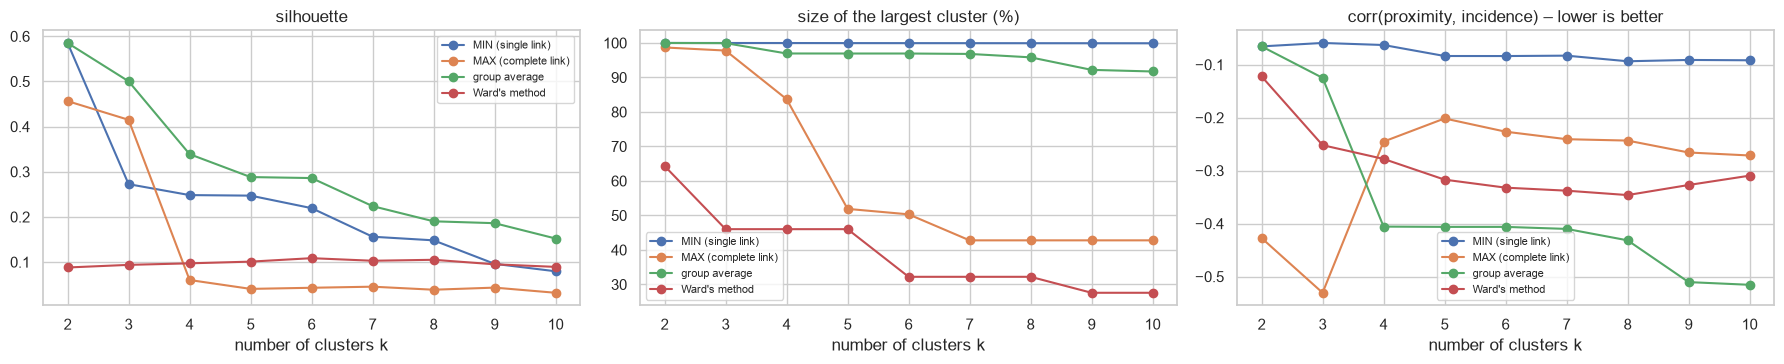

In [58]:
n_all = len(data)
pairs_all = n_all * (n_all - 1) // 2
print(f'Proximity matrix of all {n_all:,} profiles: {pairs_all:,} distances = {pairs_all * 8 / 1e9:.1f} GB in float64 '
      f'(before the copies made by the algorithm) -> not feasible with 16 GB of RAM; a stratified sample is used.')
H_N = 10_000
h_idx = np.sort(data.loc[db_idx].groupby(['ioCountry', 'class'], observed=True)
                .sample(frac=H_N / len(db_idx), random_state=RANDOM_STATE).index.to_numpy())
pairs_h = len(h_idx) * (len(h_idx) - 1) // 2
print(f'Hierarchical sample: {len(h_idx):,} accounts, {pairs_h:,} distances ({pairs_h * 8 / 1e9:.2f} GB) | classes: '
      f'{data.loc[h_idx, "class"].value_counts().to_dict()}')
comp_share = pd.DataFrame({
    'all accounts %': 100 * data.groupby(['ioCountry', 'class'], observed=True).size() / len(data),
    'DBSCAN sample %': 100 * data.loc[db_idx].groupby(['ioCountry', 'class'], observed=True).size() / len(db_idx),
    'hierarchical sample %': 100 * data.loc[h_idx].groupby(['ioCountry', 'class'], observed=True).size() / len(h_idx)})
display(comp_share.round(2).T)
Xh = X[h_idx]
Dh = pdist(Xh)                       # condensed Euclidean proximity matrix (N(N-1)/2 entries)


def incidence_correlation(labels, D=Dh, noise_label=None):
    """Pearson correlation between the proximity (distance) matrix and the ideal similarity (incidence) matrix
    ([VAL] pp. 7-8). Noise points, if any, are treated as singleton clusters."""
    lab = np.asarray(labels).astype(float).copy()
    if noise_label is not None:
        noise = lab == noise_label
        lab[noise] = -1000 - np.arange(noise.sum())          # every noise point is its own cluster
    same = 1.0 - pdist(lab.reshape(-1, 1), metric='hamming')  # 1 if same cluster, 0 otherwise
    return float(np.corrcoef(D, same)[0, 1])


LINKAGES = {'single': 'MIN (single link)', 'complete': 'MAX (complete link)', 'average': 'group average',
            'ward': "Ward's method"}
Z, h_rows = {}, []
for method in LINKAGES:
    Z[method] = linkage(Xh, method='ward') if method == 'ward' else linkage(Dh, method=method)
    for k in range(2, 11):
        lab = fcluster(Z[method], t=k, criterion='maxclust') - 1
        sizes = np.bincount(lab)
        h_rows.append({'linkage': method, 'k': k, 'silhouette': silhouette_score(Xh, lab) if len(sizes) > 1 else np.nan,
                       'largest cluster %': 100 * sizes.max() / len(lab),
                       'corr(proximity, incidence)': incidence_correlation(lab)})
h_eval = pd.DataFrame(h_rows)
display(h_eval.pivot(index='k', columns='linkage',
                     values=['silhouette', 'largest cluster %', 'corr(proximity, incidence)']).round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
for method in LINKAGES:
    d = h_eval[h_eval['linkage'] == method]
    for ax, col in zip(axes, ['silhouette', 'largest cluster %', 'corr(proximity, incidence)']):
        ax.plot(d['k'], d[col], marker='o', label=LINKAGES[method])
for ax, col in zip(axes, ['silhouette', 'size of the largest cluster (%)', 'corr(proximity, incidence) – lower is better']):
    ax.set_title(col)
    ax.set_xlabel('number of clusters k')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

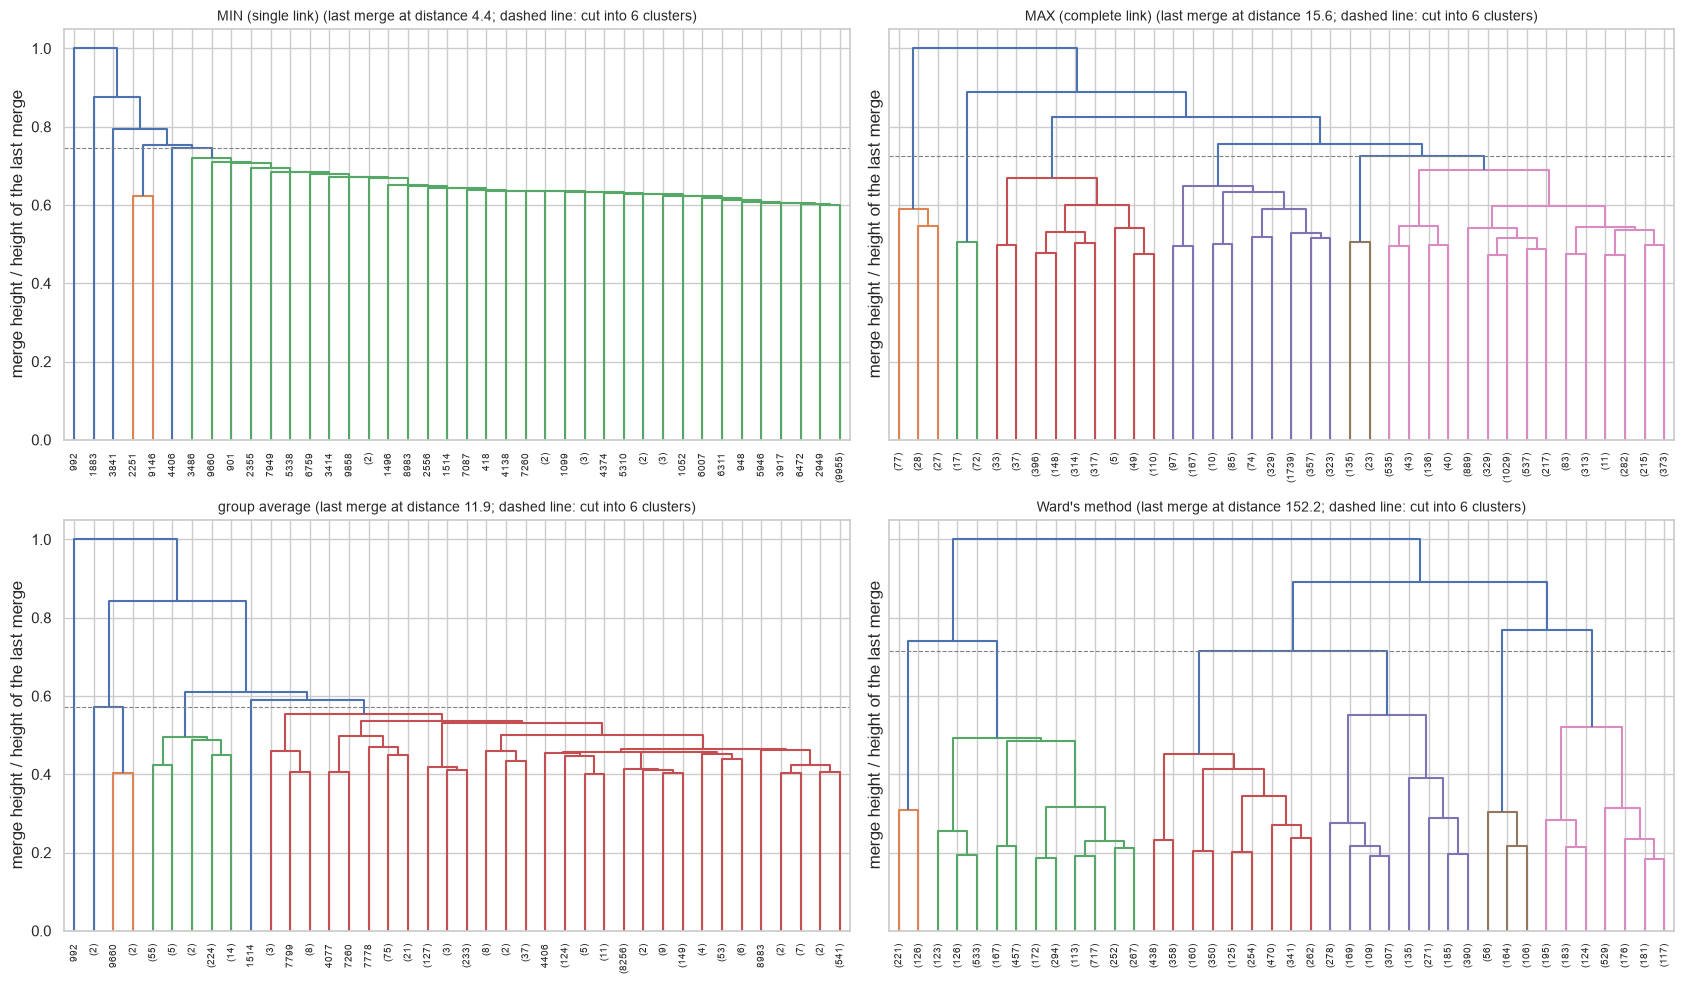

Ward's method – height gap of the merge that reduces k clusters to k-1 (a large gap suggests cutting at k):


,2,3,4,5,6,7,8,9,10
height gap,16.6500,18.6200,4.2200,3.8200,24.7700,4.8700,4.4000,1.0000,5.0200


In [59]:
# Dendrograms (truncated to the last 40 merges; numbers in brackets = accounts in a leaf). The four linkages measure
# the distance between clusters in different ways, so their merge heights have different scales: every height is
# divided by the height of the last merge of its tree, and all panels share the same y axis from 0 to 1.
# The MIN tree is very deep (chaining), hence the higher recursion limit.
import sys
sys.setrecursionlimit(max(sys.getrecursionlimit(), 20_000))
H_K = 6                                          # cut chosen below (gaps and silhouette)
fig, axes = plt.subplots(2, 2, figsize=(17, 10), sharey=True)
for ax, method in zip(axes.ravel(), LINKAGES):
    Zn = Z[method].copy()
    h_max = Zn[:, 2].max()
    Zn[:, 2] /= h_max
    cut = Zn[-(H_K - 1), 2] - 1e-9                # height that leaves H_K clusters
    dendrogram(Zn, truncate_mode='lastp', p=40, ax=ax, show_contracted=False, color_threshold=cut,
               leaf_rotation=90, leaf_font_size=7)
    ax.axhline(cut, color='grey', ls='--', lw=0.8)
    ax.set_ylim(0, 1.05)
    ax.set_title(f'{LINKAGES[method]} (last merge at distance {h_max:.1f}; dashed line: cut into {H_K} clusters)',
                 fontsize=10)
    ax.set_ylabel('merge height / height of the last merge')
plt.tight_layout()
plt.show()
ward_h = Z['ward'][:, 2]
gaps = pd.Series({k: ward_h[-(k - 1)] - ward_h[-k] for k in range(2, 11)}, name='height gap')
print("Ward's method – height gap of the merge that reduces k clusters to k-1 (a large gap suggests cutting at k):")
display(gaps.to_frame().T.round(2))

**Comparison of the linkages** ([HIER] pp. 15–27). The dendrograms are drawn on a common scale: every merge height is
divided by the height of the last merge of its tree, because the four linkages measure the distance between clusters
in different ways (the last MIN merge happens at a much smaller distance than the last Ward merge).

* **MIN (single link)**: one cluster with ≥ 99.9% of the accounts for every k – the *chaining* effect and the
  sensitivity to noise described in [HIER] p. 18: its tree is a long staircase of merges of single accounts.
* **Group average**: also one giant cluster (≥ 91.7% for every k, 96.9% for k = 6) plus one small group and a few
  isolated outliers. Its silhouette (0.29 for k = 6) and its proximity–incidence correlation (−0.41, down to −0.52 for
  larger k) look good only because the outliers are very far from everything else; the partition is useless to
  describe the profiles.
* **MAX (complete link)**: for k = 6 the sizes are more balanced (largest cluster 50%), but the silhouette is the
  lowest of all linkages (0.03–0.06 for k ≥ 4) and the correlation is weak (−0.23): complete link tends to break large
  clusters ([HIER] p. 22) and here it cuts the continuum at arbitrary places.
* **Ward's method** (the hierarchical analogue of K-means, [HIER] p. 26) gives balanced and interpretable clusters.
  The largest height gap of its dendrogram is at **k = 6** (24.8, against 18.6 at k = 3 and 16.7 at k = 2: six clusters
  remain unchanged over the widest range of heights), and the silhouette, flat around 0.09–0.11, also has its
  **maximum at k = 6** (0.109); the proximity–incidence correlation keeps improving slowly up to k = 8 (−0.33 at k = 6,
  −0.35 at k = 8) without a clear break. We therefore cut the Ward dendrogram at **k = 6**.

Cluster sizes (sorted) when every dendrogram is cut into k = 6 clusters:


,#1,#2,#3,#4,#5,#6
MIN (single link),9995,2,1,1,1,1
MAX (complete link),5032,3181,1409,158,132,89
group average,9694,300,3,2,1,1
Ward's method,3221,2758,1844,1505,347,326


Hierarchical, Ward's method (k=6): 6 clusters | total class entropy = 0.481 bits, purity = 0.861 (noise excluded)


,size,size %,IO accounts,control accounts,% IO,% ecuador,% iran_1,% iran_4,% russia_1,% uae,% of all IO accounts,% shared bio,class entropy,class purity
C0,347,3.4700,156,191,44.9570,50.4320,4.8990,4.3230,10.9510,29.3950,10.7660,2.3050,0.9930,0.5500
C1,3221,32.2070,170,3051,5.2780,34.5860,7.3890,14.5300,24.1230,19.3730,11.7320,1.2730,0.2980,0.9470
C2,2758,27.5770,136,2622,4.9310,22.1170,5.9460,11.3850,49.0570,11.4940,9.3860,1.1970,0.2830,0.9510
C3,1844,18.4380,214,1630,11.6050,19.1970,9.4900,7.8630,51.8980,11.5510,14.7690,1.1390,0.5180,0.8840
C4,326,3.2600,194,132,59.5090,11.0430,0.9200,7.9750,77.3010,2.7610,13.3890,10.4290,0.9740,0.5950
C5,1505,15.0480,579,926,38.4720,7.8410,4.5850,14.9500,45.7810,26.8440,39.9590,5.7140,0.9610,0.6150


Medians of the attributes in every cluster (original units):


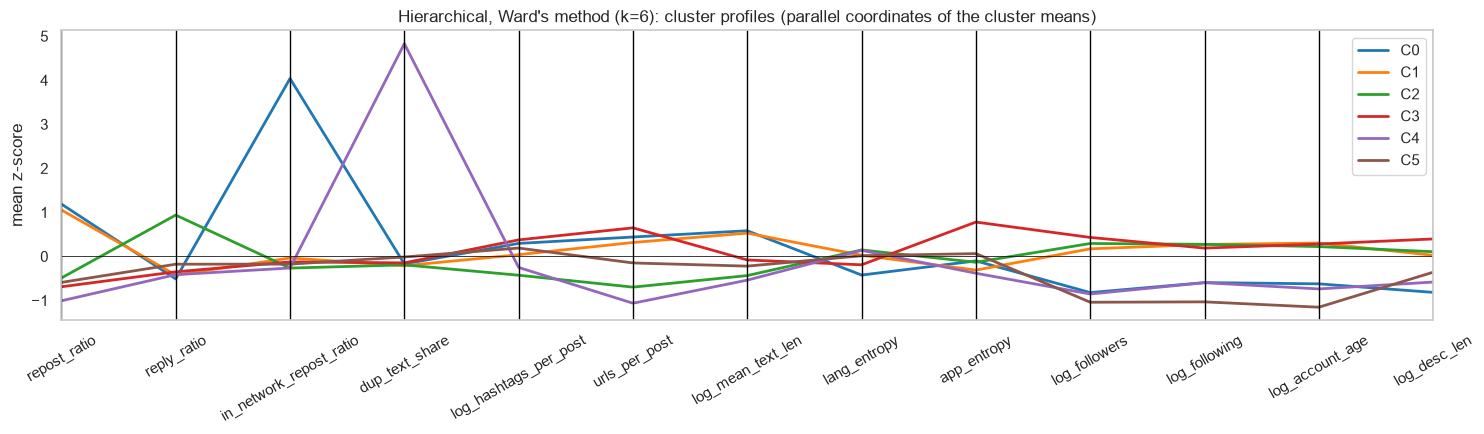

,repost_ratio,reply_ratio,in_network_repost_ratio,dup_text_share,hashtags_per_post,urls_per_post,mean_text_len,lang_entropy,app_entropy,follower_count,following_count,account_age_days,desc_len
C0,0.9670,0.0000,0.4650,0.0000,1.1710,0.7780,93.3270,0.1790,0.0000,67.0000,102.0000,150.8240,0.0000
C1,0.9170,0.0000,0.0000,0.0000,0.8480,0.7370,95.7860,0.3400,0.0000,643.0000,720.0000,"1,094.6980",57.0000
C2,0.1900,0.2730,0.0000,0.0000,0.4520,0.2300,67.5950,0.5030,0.0000,741.0000,609.0000,785.8360,59.0000
C3,0.0300,0.0000,0.0000,0.0000,1.0000,0.9660,76.4470,0.2860,0.6800,892.0000,601.5000,873.2710,81.0000
C4,0.0000,0.0000,0.0000,0.5820,0.6870,0.0950,64.3070,0.2520,0.0000,65.0000,146.4990,199.1370,10.4890
C5,0.0910,0.0100,0.0000,0.0000,1.0000,0.4510,78.1430,0.4050,0.0000,44.0000,49.0000,63.9910,29.0000


Contingency table Ward clusters x K-means clusters (hierarchical sample):


K-means,C0,C1,C2,C3,C4
Ward,,,,,
C0,317,0,0,29,1
C1,62,0,141,518,2500
C2,2,0,1992,255,509
C3,107,3,456,380,898
C4,0,269,21,30,6
C5,9,9,239,1178,70


In [60]:
labels_h = {m: fcluster(Z[m], t=H_K, criterion='maxclust') - 1 for m in LINKAGES}
sizes_tab = pd.DataFrame({LINKAGES[m]: pd.Series(np.sort(np.bincount(l))[::-1]) for m, l in labels_h.items()})
sizes_tab = sizes_tab.fillna(0).astype(int).set_axis([f'#{i + 1}' for i in range(len(sizes_tab))])
print(f'Cluster sizes (sorted) when every dendrogram is cut into k = {H_K} clusters:')
display(sizes_tab.T)
labels_ward = labels_h['ward']
ward_name = f"Hierarchical, Ward's method (k={H_K})"
display(cluster_summary(labels_ward, ward_name, idx=h_idx))
print('Medians of the attributes in every cluster (original units):')
display(cluster_profiles(labels_ward, ward_name, idx=h_idx))
print('Contingency table Ward clusters x K-means clusters (hierarchical sample):')
display(pd.crosstab(cluster_names(labels_ward).rename('Ward'), cluster_names(labels_km[h_idx]).rename('K-means')))

**Interpretation of the Ward clusters** (stratified sample of 10,001 accounts, 14.5% IO; medians in the table above):

| Cluster | Size | % IO | Profile | K-means counterpart |
|---|---|---|---|---|
| C1 | 32% | 5% | **established reposters**: ≈92% reposts, ≈640 followers, ≈3 years old, complete biographies | mostly C4 (2,500 of 3,221) |
| C2 | 28% | 5% | **conversational users**: ≈27% replies, the most multilingual, ≈740 followers, ≈2 years old | mostly C2 (1,992 of 2,758) |
| C3 | 18% | 12% | **link and hashtag sharers**: almost no reposts, ≈1 link and 1 hashtag per post, several clients, ≈890 followers, the longest biographies | C4, C2 and C3 |
| C5 | 15% | 38% (**40% of all IO accounts**) | **low-profile young accounts**: ≈2 months old, ≈45 followers and following, short biographies, mostly original posts | C3 (1,178 of 1,505) |
| C0 | 3% | 45% (50% Ecuador) | **network amplifiers**: ≈97% reposts, ≈47% of the posts are reposts of other accounts of the operation, ≈5 months old, ≈67 followers, no biography | C0 (317 of 347) |
| C4 | 3% | 60% (77% Russia) | **copy-paste broadcasters**: ≈58% duplicated texts, no reposts, short texts; 10% shared biographies | C1 (269 of 326) |

* Ward finds the behaviours of K-means (established, conversational, low-profile young, amplifiers, copy-paste) and
  splits the ordinary accounts differently: its sixth cluster separates the accounts that share links and hashtags with
  original posts from the established reposters, and its low-profile cluster is younger and more IO-dominated (38% IO)
  than the K-means one. Class entropy 0.481 bits and purity 0.861 (one cluster: 0.597 and 0.855).
* Ward and K-means share the most information among the methods (2.5) and recover the same two groups in which IO
  accounts are strongly over-represented (amplifiers and copy-paste broadcasters), which makes them **robust
  findings**. The amplifier cluster of Ward is smaller and less IO-dominated (45% IO, 50% Ecuadorian accounts) than the
  K-means one: Ward keeps only the most extreme reposters in it.

In [61]:
# Does Ward's result depend on the sample? Ward's method (k = 5) on three other stratified samples of 10,000 accounts,
# drawn this time directly from all the accounts (strata operation x class)
ward_rows = []
for seed in [RANDOM_STATE, 1, 2, 3]:
    if seed == RANDOM_STATE:
        idx_s, lab_s = h_idx, labels_ward
    else:
        idx_s = np.sort(data.groupby(['ioCountry', 'class'], observed=True)
                        .sample(frac=H_N / len(data), random_state=seed).index.to_numpy())
        lab_s = fcluster(linkage(X[idx_s], method='ward'), t=H_K, criterion='maxclust') - 1
    d_ = data.iloc[idx_s]
    med_ = d_.groupby(lab_s)[['repost_ratio', 'in_network_repost_ratio', 'dup_text_share']].median()
    size_ = pd.Series(lab_s).value_counts(normalize=True).mul(100)
    io_ = pd.Series(d_['class'].eq('IO').to_numpy()).groupby(lab_s).mean().mul(100)
    amp, cp = med_['in_network_repost_ratio'].idxmax(), med_['dup_text_share'].idxmax()
    ward_rows.append({
        'sample': 'main (subset of the DBSCAN sample)' if seed == RANDOM_STATE else f'seed {seed}',
        'cluster sizes % (largest first)': ' / '.join(f'{v:.0f}' for v in size_.values),
        'amplifier cluster: size, % IO, median in-network reposts':
            f'{size_[amp]:.1f}%, {io_[amp]:.0f}% IO, {med_.at[amp, "in_network_repost_ratio"]:.2f}',
        'copy-paste cluster: size, % IO, median copied texts':
            f'{size_[cp]:.1f}%, {io_[cp]:.0f}% IO, {med_.at[cp, "dup_text_share"]:.2f}',
        'class entropy': entropy_purity(lab_s, d_['class'])[0],
        'agreement with K-means, I / log2(min(nX, nY))': mutual_information_bits(lab_s, labels_km[idx_s]) / np.log2(min(H_K, K_BEST))})
with pd.option_context('display.max_colwidth', 80):
    display(pd.DataFrame(ward_rows).set_index('sample').round(3))
del d_

,cluster sizes % (largest first),"amplifier cluster: size, % IO, median in-network reposts","copy-paste cluster: size, % IO, median copied texts",class entropy,"agreement with K-means, I / log2(min(nX, nY))"
sample,,,,,
main (subset of the DBSCAN sample),32 / 28 / 18 / 15 / 3 / 3,"3.5%, 45% IO, 0.46","3.3%, 60% IO, 0.58",0.4810,0.3240
seed 1,33 / 24 / 18 / 15 / 7 / 3,"7.0%, 36% IO, 0.33","3.0%, 60% IO, 0.60",0.4610,0.3600
seed 2,29 / 27 / 21 / 16 / 5 / 3,"4.6%, 54% IO, 0.40","3.0%, 61% IO, 0.61",0.4860,0.3810
seed 3,30 / 24 / 24 / 15 / 4 / 3,"4.2%, 63% IO, 0.43","2.6%, 66% IO, 0.66",0.4840,0.3760


**Stability.** On three other stratified samples of 10,000 accounts, drawn directly from all the accounts, Ward's method
(k = 6) gives clusters of similar sizes (largest 29–33%, two small clusters of 3–7%), and the two coordinated groups
reappear every time: an amplifier cluster of 3.5–7% of the accounts (36–63% IO, median in-network reposts 0.33–0.46)
and a copy-paste cluster of 2.6–3.3% (60–66% IO, median copied texts 0.58–0.66). The class entropy (0.46–0.49) and
the agreement with K-means (0.32–0.38 of the maximum mutual information) are also stable: the hierarchical result does
not depend on the particular sample.

## 2.5 Comparison of the clustering solutions

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Aspects of cluster validation; internal, external and relative indices | [VAL] pp. 3–6 |
| Internal: SSE (cohesion), BSS (separation), silhouette | [VAL] pp. 14–19 |
| Correlation between proximity and ideal similarity (incidence) matrices | [VAL] pp. 7–8 |
| Similarity matrix ordered by cluster label (visual inspection) | [VAL] pp. 9–13 |
| External: entropy and purity | [VAL] p. 20 |
| Agreement between two clusterings: contingency table, mutual information (max = log2(min(nX, nY))) | [SIM] pp. 23–24 |
| Strengths and limitations of each algorithm | [KM] pp. 10–16; [DBSCAN] pp. 9–10; [HIER] pp. 17–31 |

All solutions are compared on the **same 10,000 accounts** of the stratified hierarchical sample (K-means labels come
from the model trained on all accounts, DBSCAN labels from the model trained on the 20,000-account sample). External
measures use information that was **not** used for clustering: the class (IO / control) and the operation. As
recommended in [Q&A Q8], the quantitative measures support the comparison but are not its only basis: every final
cluster of every method has been characterised and interpreted on the user-profile attributes (2.2–2.4, 2.6).

Reference: entropy of the class in the sample = 0.597 bits, purity of a single cluster = 0.855


,clusters,noise %,SSE,BSS,silhouette,"corr(proximity, incidence)",class entropy,class purity,operation entropy,operation purity,% IO in IO-majority clusters,max % IO of a cluster (>=1% size)
K-means (k=5),5.0000,0.0000,"85,941.7450","43,241.7080",0.1520,-0.4140,0.4810,0.8650,1.9940,0.4410,30.2280,62.6330
"DBSCAN (Eps=1.6, MinPts=50)",4.0000,37.3560,"51,401.4060","6,836.0690",0.3380,-0.4510,0.4160,0.9150,2.0620,0.3890,14.0100,98.0950
Ward (k=6),6.0000,0.0000,"89,310.7020","39,872.7500",0.1090,-0.3320,0.4810,0.8610,1.9760,0.4540,13.3890,59.5090
Group average (k=6),6.0000,0.0000,"119,067.5550","10,115.8980",0.2860,-0.4060,0.5700,0.8620,2.0630,0.4070,12.8360,61.3330
MAX / complete (k=6),6.0000,0.0000,"101,907.8770","27,275.5760",0.0430,-0.2270,0.5600,0.8620,2.0320,0.4110,12.3530,67.0890


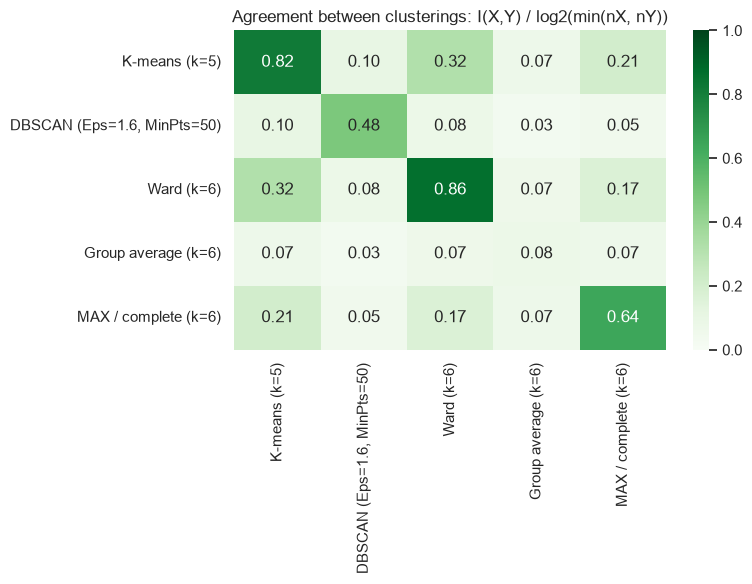

In [62]:
methods = {
    f'K-means (k={K_BEST})': labels_km[h_idx],
    f'DBSCAN (Eps={DB_EPS}, MinPts={DB_MIN_PTS})': labels_db[h_idx],
    f"Ward (k={H_K})": labels_ward,
    f'Group average (k={H_K})': labels_h['average'],
    f'MAX / complete (k={H_K})': labels_h['complete'],
}
y_class = data.iloc[h_idx]['class'].astype(str).to_numpy()
y_op = data.iloc[h_idx]['ioCountry'].astype(str).to_numpy()


def compare_row(lab):
    lab = np.asarray(lab)
    noise = -1 if (lab == -1).any() else None
    sc = internal_scores(Xh, lab)
    e_cls, p_cls = entropy_purity(lab, y_class)
    e_op, p_op = entropy_purity(lab, y_op)
    s = pd.DataFrame({'lab': lab, 'io': y_class == 'IO'})
    s_nn = s[s['lab'] != -1]
    io_share = s_nn.groupby('lab')['io'].mean()
    big = s_nn['lab'].value_counts()
    big = big[big >= 0.01 * len(s)].index
    return {'clusters': int(len(set(lab)) - (noise is not None)), 'noise %': 100 * (lab == -1).mean(), **sc,
            'corr(proximity, incidence)': incidence_correlation(lab, noise_label=noise),
            'class entropy': e_cls, 'class purity': p_cls, 'operation entropy': e_op, 'operation purity': p_op,
            '% IO in IO-majority clusters': 100 * s_nn['io'][s_nn['lab'].map(io_share) > 0.5].sum() / s['io'].sum(),
            'max % IO of a cluster (>=1% size)': 100 * io_share[big].max()}


comparison = pd.DataFrame({name: compare_row(lab) for name, lab in methods.items()}).T
print(f'Reference: entropy of the class in the sample = {entropy_bits(pd.Series(y_class).value_counts()):.3f} bits, '
      f'purity of a single cluster = {(y_class == "Control").mean():.3f}')
display(comparison.round(3))


def mi_matrix(meths):
    """Mutual information between every pair of clusterings, relative to its maximum log2(min(nX, nY))."""
    out = pd.DataFrame(index=meths, columns=meths, dtype=float)
    for a in meths:
        for b in meths:
            na_, nb_ = len(set(meths[a])), len(set(meths[b]))
            out.loc[a, b] = mutual_information_bits(meths[a], meths[b]) / np.log2(min(na_, nb_))
    return out


plt.figure(figsize=(8, 6))
sns.heatmap(mi_matrix(methods), annot=True, fmt='.2f', cmap='Greens', vmin=0, vmax=1)
plt.title('Agreement between clusterings: I(X,Y) / log2(min(nX, nY))')
plt.tight_layout()
plt.show()

**How to read the similarity matrices** ([VAL] pp. 9–13). We take 1,200 accounts of the common sample and compute
the similarity of every pair, $s = 1 - d/d_{max}$, where $d$ is their Euclidean distance on the standardised
attributes and $d_{max}$ the largest distance between two of these accounts: $s = 1$ for identical profiles, $s = 0$
for the two most different ones. The $1{,}200 \times 1{,}200$ matrix is drawn as an image in which **row $i$ and
column $i$ are the same account**, and the accounts are **sorted by cluster** (white lines separate the clusters,
the labels on the axes name the blocks with at least 20 accounts; DBSCAN noise is last). The **colour** is the similarity: **dark red** = very
similar profiles, yellow/green = intermediate, **dark blue** = very different profiles (colour scale on the right;
similarities below 0.4 are drawn in the darkest blue). The diagonal is red because every account is identical to
itself. If the clustering is good, every cluster appears as a **red square block on the diagonal** (its members are
similar to each other) and the areas outside the blocks are blue (members of different clusters are different).

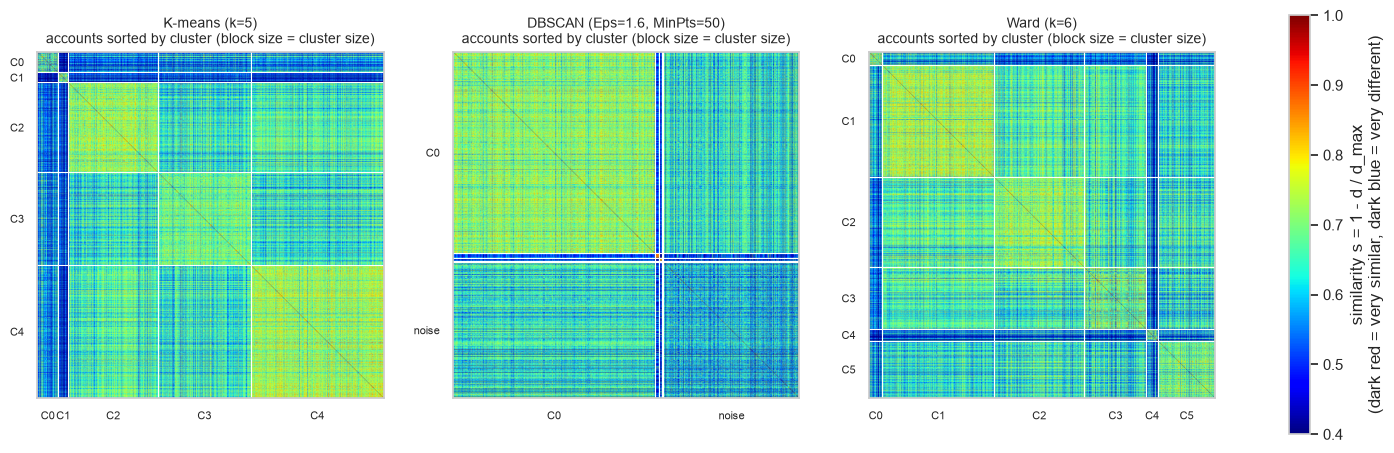

In [63]:
# Similarity matrices ordered by cluster label ([VAL] pp. 9-13), on 1,200 accounts of the common sample
sub = np.sort(np.random.default_rng(1).choice(len(h_idx), size=1200, replace=False))
D_sub = pdist(Xh[sub])
from scipy.spatial.distance import squareform
S_sub = 1 - squareform(D_sub) / D_sub.max()              # similarity in [0, 1]
fig, axes = plt.subplots(1, 3, figsize=(19, 6.4))
for ax, name in zip(axes, list(methods)[:3]):
    lab = np.asarray(methods[name])[sub]
    key = np.where(lab == -1, lab.max() + 1, lab)            # noise last
    order = np.argsort(key, kind='stable')
    im = ax.imshow(S_sub[np.ix_(order, order)], cmap='jet', vmin=0.4, vmax=1)
    ax.grid(False)                                           # only the white lines mark cluster boundaries
    counts = pd.Series(key).value_counts().sort_index()
    ends = np.cumsum(counts.to_numpy())
    for b in ends[:-1]:
        ax.axhline(b - 0.5, color='w', lw=0.8)
        ax.axvline(b - 0.5, color='w', lw=0.8)
    centres = ends - counts.to_numpy() / 2
    names_ = ['noise' if (lab == -1).any() and k_ == key.max() else f'C{k_}' for k_ in counts.index]
    big = counts.to_numpy() >= 20                           # label only the blocks large enough to be seen
    ax.set_xticks(centres[big])
    ax.set_xticklabels(np.array(names_)[big], fontsize=8)
    ax.set_yticks(centres[big])
    ax.set_yticklabels(np.array(names_)[big], fontsize=8)
    ax.set_title(f'{name}\naccounts sorted by cluster (block size = cluster size)', fontsize=10)
cb = fig.colorbar(im, ax=axes, shrink=0.85)
cb.set_label('similarity s = 1 - d / d_max\n(dark red = very similar, dark blue = very different)')
plt.show()

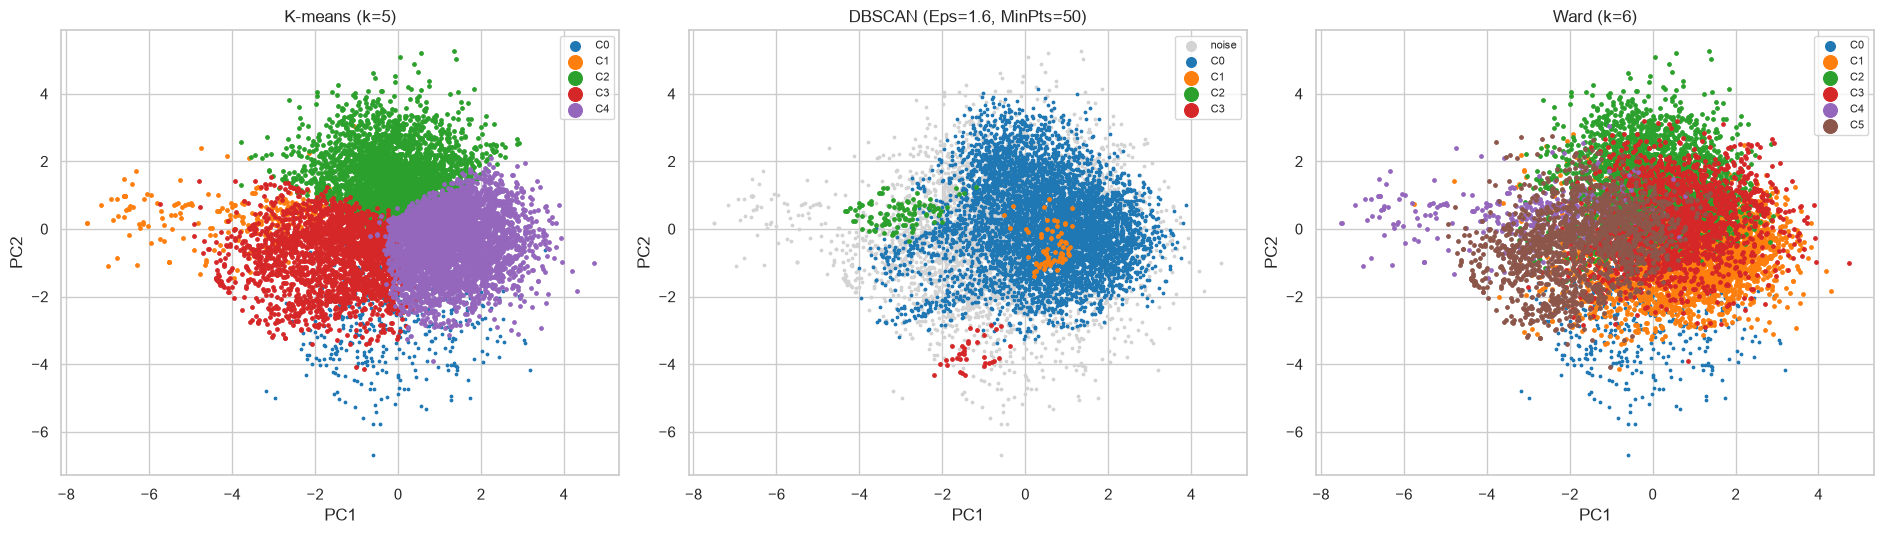

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, name in zip(axes, list(methods)[:3]):
    scatter_pca(methods[name], name, ax, idx=h_idx)
plt.tight_layout()
plt.show()

**Quantitative comparison.**

* *Internal measures.* DBSCAN has the best silhouette (0.34) and proximity–incidence correlation (−0.45), but they are
  computed on the ≈63% of the accounts that are not noise (noise points count as singletons in the correlation) and
  on a solution dominated by one big cluster. Group average looks good (silhouette 0.29, correlation −0.41) only
  because it is one giant cluster (97%) plus one small group and a few outliers. Among the methods producing
  balanced partitions, **K-means** has the lowest SSE, the highest BSS and the best silhouette (0.152) and
  correlation (−0.41) – as expected, since it directly minimises the SSE – followed by Ward (0.109 / −0.33) and,
  far behind, complete link (0.043 / −0.23).
* *External measures.* With a single cluster the class entropy would be 0.597 bits and the purity 0.855. K-means and
  Ward (0.481 / 0.861–0.865) and the other linkages improve these values only slightly, DBSCAN a bit more on its
  clustered points (0.416 / 0.915). The operation is not reproduced either (operation entropy ≈ 2.0 bits of
  log2(5) = 2.32). **No method recovers the IO/control label**: the clusters describe behavioural styles that cut
  across classes and operations.
* *Concentration of IO accounts.* DBSCAN finds the purest IO clusters (97–100% IO) but they cover few IO accounts
  (14% of the IO accounts of the sample are in IO-majority clusters); K-means puts 30% of them in IO-majority
  clusters (amplifiers just at the 50% threshold and copy-paste broadcasters well above it), Ward, group average and
  complete link 12–13% (essentially one IO-majority cluster each; for Ward the copy-paste group).
* *Agreement* (heatmap: the colour and the number in each cell are the mutual information of the two clusterings
  divided by its maximum, from 0 – independent partitions, white – to 1 – one partition determines the other, dark
  green; the diagonal is a clustering compared with itself and is below 1 when its clusters have unequal sizes).
  K-means and Ward share the most information (0.32 of the maximum), then K-means and complete link (0.21); DBSCAN and
  group average share very little with the other methods (≤ 0.10), because their partitions are dominated by one
  giant cluster.
* *Similarity matrices.* For K-means and Ward the diagonal blocks are visible (yellow-green: members of a cluster are
  more similar to each other) but blurred, and the areas between blocks are only slightly bluer: accounts of
  different clusters are also fairly similar – the continuum again. For DBSCAN the main cluster is one large block and
  the noise points (last block) are blue against almost everything: they are dissimilar from the dense core and from
  each other; DBSCAN's three small clusters have fewer than 20 of the 1,200 accounts each, so they appear only as thin
  unlabelled bands between C0 and the noise. The copy-paste clusters (K-means C1, Ward C4) stand out most clearly: a
  small yellow-green square whose rows and columns are dark blue against all the other clusters – members similar to
  each other and very different from every other account (K-means C1 has the highest silhouette, 0.36).

**Strengths and limitations** (as observed on these data, cf. the limitations listed in the slides).

| Method | Strengths | Limitations |
|---|---|---|
| K-means | scales to all 69k accounts; centroids easy to interpret; lowest SSE | k must be chosen and the data have no clear k; assumes globular clusters of similar size; sensitive to outliers (mitigated by log + IQR capping); partitions a continuum ([KM] pp. 10–16) |
| DBSCAN | finds dense groups of any shape and an explicit noise class; isolates near-identical coordinated accounts | very sensitive to Eps / MinPts; one density threshold for regions of very different density; costly neighbourhood queries (sample); distances lose contrast in 13 dimensions ([DBSCAN] p. 10) |
| Hierarchical | no k needed in advance; the dendrogram shows the structure at several scales; Ward consistent with K-means | the linkage is decisive (MIN and group average degenerate into one cluster + outliers); O(N²) memory → 10k stratified sample; merges cannot be undone ([HIER] pp. 30–31) |

**Robust findings across methods.** Two behaviours in which IO accounts are strongly over-represented – **network
amplifiers** (coordinated in-network reposting) and **copy-paste broadcasters** (verbatim duplicated content, no
reposts, often with a shared template biography) – are found by K-means, Ward and DBSCAN (DBSCAN in an even purer
form, revealing also a Russian retweet network run through many clients and a UAE retweet farm). The remaining IO
accounts blend with control accounts, mostly in a group of **low-profile young accounts** (few followers, short or
empty biographies), where behaviour alone does not separate IO accounts from genuine newcomers. Inside single
operations (2.2.4) the picture is sharper: in Iran_4 and UAE one cluster of young, little-followed accounts gathers
97–98% of the IO accounts of the operation (62–75% IO).

## 2.6 Optional: Mixture models and the EM algorithm (Gaussian Mixture Model)

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Model-based (probabilistic) clustering with a mixture of Gaussians | [KM-VAR] pp. 13–27 |
| EM algorithm (soft assignment in the E-step, parameter update in the M-step) | [KM-VAR] pp. 16, 28 |
| Advantages and disadvantages of EM | [KM-VAR] p. 29 |
| Bayesian Information Criterion to choose the number of clusters | [KM-VAR] pp. 7–9 |
| Fuzzy / probabilistic clusterings (membership weights summing to 1) | [CL-INTRO] p. 9 |
| Entropy, purity, mutual information | [VAL] p. 20; [SIM] pp. 23–24 |

The slides on K-means variants present three extensions of K-means (bisecting K-means, X-means and mixture models
fitted with EM). We use the **mixture of Gaussians fitted with EM**, because it is the variant that changes the most
with respect to the mandatory methods: every cluster is a multivariate Gaussian with its own mean and covariance
matrix (clusters of different sizes and shapes, [KM-VAR] p. 29), and every account receives a **probability** of
belonging to each cluster (soft assignment) instead of a hard label.

**The model.** A mixture model assumes that the accounts were generated by $k$ sources, one per cluster
([KM-VAR] pp. 14, 23–26). Source $j$ is a multivariate Gaussian distribution with

* a **mean vector** $\mu_j$ – 13 values, the centre of the cluster (the analogue of a centroid);
* a **covariance matrix** $\Sigma_j$ – 13 × 13 values: the spread of every attribute inside the cluster and how pairs
  of attributes vary together; geometrically, the size, shape and orientation of an ellipsoid;
* a **mixture probability** $\pi_j$ – the share of the accounts generated by that source ($\sum_j \pi_j = 1$).

The probability density of an account $x$ is $p(x \mid \Theta) = \sum_j \pi_j\, \mathcal{N}(x \mid \mu_j, \Sigma_j)$ and
the likelihood of the data is the product of $p(x_i \mid \Theta)$ over all accounts. Clustering means finding the
parameters $\Theta = (\pi_j, \mu_j, \Sigma_j)_{j=1..k}$ that **maximise the likelihood**, and then giving each account to
the source that most probably generated it.

**The EM algorithm, step by step** ([KM-VAR] pp. 16, 27–28):

1. **Initialisation.** The parameters start from random values: $k$ accounts drawn at random are the initial means,
   and the initial covariances and weights are computed from them.
2. **E-step (expectation).** With the current parameters, compute for every account $i$ and component $j$ the
   **membership probability** (Bayes' rule, p. 27):
   $r_{ij} = P(j \mid x_i) = \dfrac{\pi_j\, \mathcal{N}(x_i \mid \mu_j, \Sigma_j)}{\sum_l \pi_l\, \mathcal{N}(x_i \mid \mu_l, \Sigma_l)}$.
   Every account is shared among all the components (*soft* assignment); K-means would give it entirely to the
   nearest centroid (*hard* assignment).
3. **M-step (maximisation).** Re-estimate the parameters, using the membership probabilities as weights (p. 28):
   $\pi_j = \frac{1}{n}\sum_i r_{ij}$ (the expected share of the cluster),
   $\mu_j = \sum_i r_{ij}\, x_i / \sum_i r_{ij}$ (a weighted mean),
   $\Sigma_j = \sum_i r_{ij}\,(x_i - \mu_j)(x_i - \mu_j)^T / \sum_i r_{ij}$ (a weighted covariance).
4. **Repeat** E and M until the log-likelihood $\sum_i \log \sum_j \pi_j \mathcal{N}(x_i \mid \mu_j, \Sigma_j)$ grows by
   less than $10^{-3}$. Each iteration can only increase the likelihood, but EM can stop in a local maximum, so – as
   with the multiple runs of K-means – it is restarted from several random initialisations and the solution with the
   highest likelihood is kept.
5. **Final clusters.** Each account goes to the component with the largest $r_{ij}$; this largest probability says
   how sure the assignment is.

K-means is the limit case of EM in which all clusters are spheres of the same, vanishing size: the memberships become
0/1 (hard assignment) and the M-step computes the centroids (p. 16).

**Parameters of the model.**

| Parameter | Value used | Meaning |
|---|---|---|
| number of components $k$ | 2 … 12, chosen with BIC | number of Gaussian sources (clusters) |
| covariance type | `full` (compared with `diag`) | `full`: every component has its own complete covariance matrix (ellipsoid of any orientation, attributes correlated inside the cluster); `diag`: only one variance per attribute (ellipsoids aligned with the axes) |
| `reg_covar` | $10^{-3}$ | small value added to the diagonal of every $\Sigma_j$: several attributes are exactly 0 for whole groups of accounts (no copied texts, no in-network reposts), and a variance of 0 would make $\Sigma_j$ singular and the EM unstable |
| initialisation | `random_from_data` | $k$ random accounts as initial means (random initial parameters, p. 28) |
| `n_init` | 3 for the BIC comparison, 10 for the final model | random restarts; the run with the highest likelihood is kept |
| stopping rule | tolerance $10^{-3}$ on the log-likelihood, at most 500 iterations | convergence of EM |

**Differences from the mandatory methods.**

| | K-means | DBSCAN | Hierarchical (Ward) | Gaussian mixture (EM) |
|---|---|---|---|---|
| a cluster is… | the points nearest to a centroid | a dense region | a branch of the tree of merges | a Gaussian distribution (centre + covariance) |
| cluster shapes | spheres of similar size | any shape | spheres (Ward) | ellipsoids of any size, shape and orientation |
| assignment | hard | hard, plus noise | hard | soft: a probability for every cluster |
| number of clusters | fixed in advance | follows from Eps and MinPts | chosen by cutting the dendrogram | fixed in advance, chosen with BIC |
| what is optimised | SSE | nothing global: density connectivity | greedy merges (Ward: smallest SSE increase) | likelihood of the data |
| outliers | pull the centroids | become noise | MIN is sensitive to them | spread over the components; they distort the covariances ([KM-VAR] p. 29) |
| here run on | all 69k accounts | 20k sample | 10k sample | all 69k accounts |

**Model selection with BIC.** BIC balances the fit (log-likelihood) and the number of parameters
([KM-VAR] pp. 7–8). scikit-learn reports $BIC = -2 \log L + p \log n$, i.e. the slide definition with the opposite
sign: here **lower is better**. A full-covariance mixture with $k$ components has $p = k \cdot (13 + 13 \cdot 14/2) + (k - 1)$
= $104k + k - 1$ parameters, a diagonal one $k \cdot 26 + k - 1$.

All runs converged: True


covariance,diag,full,full: BIC decrease vs k-1
k,,,
2,"1,947,415.0000","1,932,127.0000",NaN
3,"1,748,124.0000","1,583,304.0000","348,822.0000"
4,"1,656,248.0000","1,502,322.0000","80,982.0000"
5,"1,563,333.0000","1,403,800.0000","98,522.0000"
6,"1,519,908.0000","1,384,272.0000","19,528.0000"
7,"1,423,063.0000","1,321,786.0000","62,486.0000"
8,"1,420,725.0000","1,278,645.0000","43,141.0000"
9,"1,355,536.0000","1,223,698.0000","54,947.0000"
10,"1,358,714.0000","1,195,154.0000","28,544.0000"


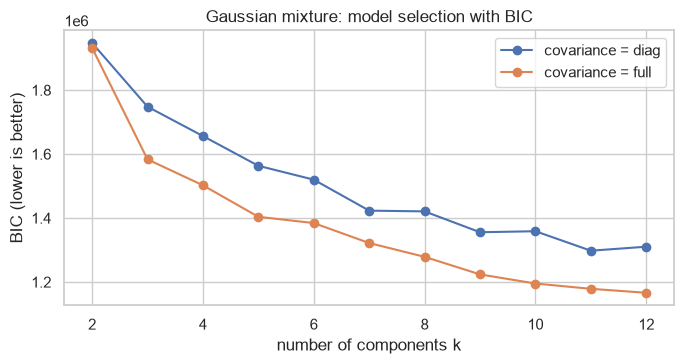

In [65]:
GMM_K = range(2, 13)
GMM_N_INIT = 3
gmm_rows, gmm_models = [], {}
for cov in ['diag', 'full']:
    for k in GMM_K:
        gm = GaussianMixture(n_components=k, covariance_type=cov, reg_covar=1e-3, init_params='random_from_data',
                             n_init=GMM_N_INIT, max_iter=500, random_state=RANDOM_STATE).fit(X)
        gmm_models[(cov, k)] = gm
        gmm_rows.append({'covariance': cov, 'k': k, 'BIC': gm.bic(X), 'converged': gm.converged_})
gmm_bic = pd.DataFrame(gmm_rows).pivot(index='k', columns='covariance', values='BIC')
gmm_bic['full: BIC decrease vs k-1'] = -gmm_bic['full'].diff()
print('All runs converged:', bool(pd.DataFrame(gmm_rows)['converged'].all()))
display(gmm_bic.round(0))
fig, ax = plt.subplots(figsize=(7, 3.8))
for cov in ['diag', 'full']:
    ax.plot(gmm_bic.index, gmm_bic[cov], marker='o', label=f'covariance = {cov}')
ax.set_xlabel('number of components k')
ax.set_ylabel('BIC (lower is better)')
ax.set_title('Gaussian mixture: model selection with BIC')
ax.legend()
plt.tight_layout()
plt.show()

**Choice of the model.** All the runs converged. Full covariance matrices always give a much lower BIC than diagonal
ones (the attributes are correlated, so elliptical clusters with free orientation fit better). BIC keeps decreasing
up to 12 components: with ≈69k accounts the penalty for extra parameters is small compared with the likelihood gain,
so BIC has no minimum in the range. We therefore use the "elbow" of the curve: the first improvement (2 → 3
components) is ≈349k, the next two are still above 20% of it (81k and 99k), and **after k = 5 every additional
component improves BIC by less than 20% of that first gain** (at most 62k). We select the full-covariance model with
**k = 5**, which is refitted with 10 random initialisations.

Final model: BIC = 1,403,592, converged = True, iterations = 42
GMM / EM (full covariance, k=5): 5 clusters | total class entropy = 0.424 bits, purity = 0.859 (noise excluded)


,size,size %,IO accounts,control accounts,% IO,% ecuador,% iran_1,% iran_4,% russia_1,% uae,% of all IO accounts,% shared bio,class entropy,class purity
C0,10689,15.4660,484,10205,4.5280,12.6300,8.4950,6.5860,63.6260,8.6630,4.8380,2.0860,0.2660,0.9550
C1,8759,12.6740,4182,4577,47.7450,26.2700,5.3770,9.1680,29.9580,29.2270,41.8030,4.5550,0.9990,0.5230
C2,6563,9.4960,3406,3157,51.8970,12.0680,1.2950,15.6640,53.9540,17.0200,34.0460,7.5730,0.9990,0.5190
C3,15845,22.9270,373,15472,2.3540,37.2170,5.6360,16.0930,18.2960,22.7580,3.7290,1.4260,0.1610,0.9760
C4,27255,39.4370,1559,25696,5.7200,23.0890,8.2330,11.5910,44.8910,12.1960,15.5840,1.2510,0.3160,0.9430


Medians of the attributes in every cluster (original units):


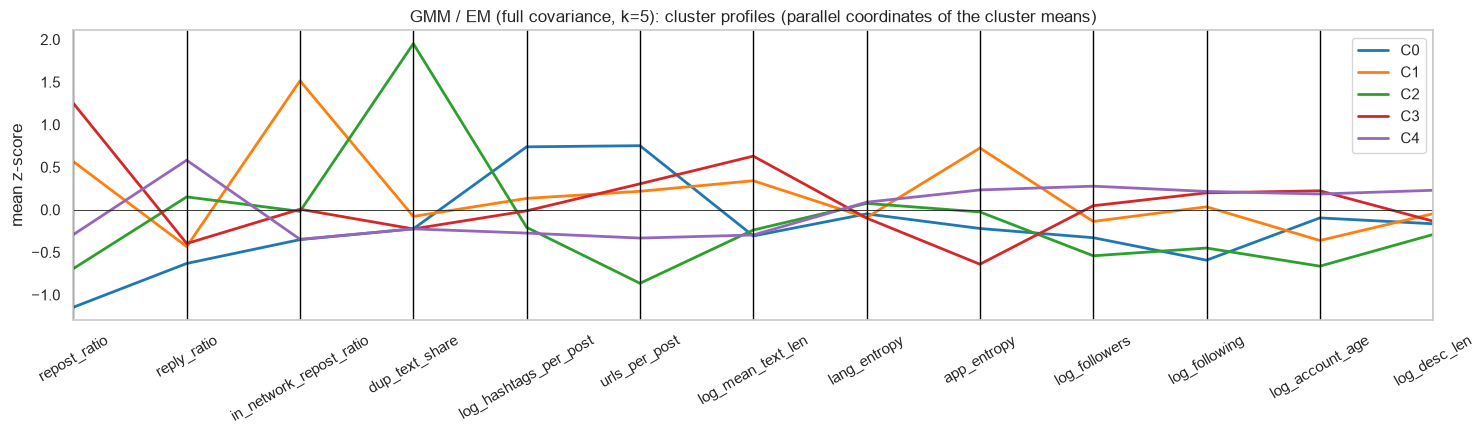

,repost_ratio,reply_ratio,in_network_repost_ratio,dup_text_share,hashtags_per_post,urls_per_post,mean_text_len,lang_entropy,app_entropy,follower_count,following_count,account_age_days,desc_len
C0,0.0000,0.0000,0.0000,0.0000,1.6670,1.0000,73.3330,0.2760,0.0000,275.0000,132.0000,566.9680,46.0000
C1,0.7140,0.0100,0.1150,0.0000,0.9510,0.6970,89.6000,0.3440,0.6010,284.0000,381.0000,322.1790,47.0000
C2,0.1160,0.0430,0.0100,0.1330,0.6740,0.1940,72.3330,0.3650,0.0000,107.0000,182.0000,189.4090,32.0000
C3,0.9740,0.0000,0.0000,0.0000,0.8000,0.7200,99.2160,0.2870,0.0000,488.0000,621.0000,994.7650,44.0000
C4,0.2630,0.1670,0.0000,0.0000,0.5510,0.3740,71.3830,0.4500,0.2640,761.0000,620.0000,844.9880,70.0000


,max posterior,uncertain (p < 0.8)
class,,
IO,0.9520,0.0950
Control,0.9790,0.0400


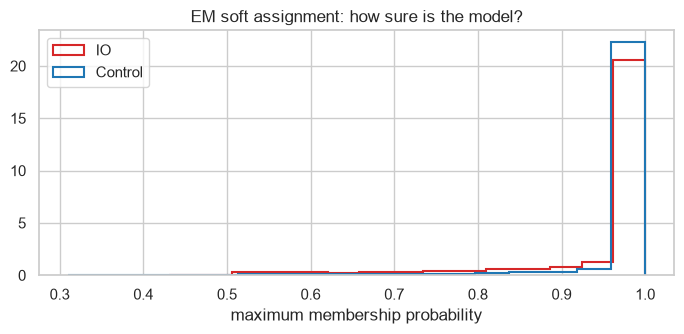

In [66]:
GMM_COV, GMM_K_BEST = 'full', 5
# the chosen model is refitted with 10 random initialisations (more restarts = less risk of a poor local maximum)
gmm = GaussianMixture(n_components=GMM_K_BEST, covariance_type=GMM_COV, reg_covar=1e-3, init_params='random_from_data',
                      n_init=10, max_iter=500, random_state=RANDOM_STATE).fit(X)
print(f'Final model: BIC = {gmm.bic(X):,.0f}, converged = {gmm.converged_}, iterations = {gmm.n_iter_}')
labels_gmm = gmm.predict(X)
proba = gmm.predict_proba(X)
gmm_name = f'GMM / EM ({GMM_COV} covariance, k={GMM_K_BEST})'
display(cluster_summary(labels_gmm, gmm_name))
print('Medians of the attributes in every cluster (original units):')
display(cluster_profiles(labels_gmm, gmm_name))

# Soft assignment: maximum membership probability of every account
conf = pd.DataFrame({'max posterior': proba.max(axis=1), 'class': data['class']})
conf['uncertain (p < 0.8)'] = conf['max posterior'] < 0.8
display(conf.groupby('class', observed=True)[['max posterior', 'uncertain (p < 0.8)']].mean().round(3))
fig, ax = plt.subplots(figsize=(7, 3.5))
for cls in CLASS_ORDER:
    v = conf.loc[conf['class'] == cls, 'max posterior']
    ax.hist(v, bins=sturges_bins(len(v)), density=True, histtype='step', lw=1.5, color=CLASS_PALETTE[cls], label=cls)
ax.set_xlabel('maximum membership probability')
ax.set_title('EM soft assignment: how sure is the model?')
ax.legend()
plt.tight_layout()
plt.show()

In [67]:
# Comparison with the mandatory methods on the common stratified sample of 10,000 accounts
methods_ext = dict(methods)
methods_ext[gmm_name] = labels_gmm[h_idx]
comparison_ext = pd.DataFrame({name: compare_row(lab) for name, lab in methods_ext.items()}).T
display(comparison_ext.round(3))
print('Agreement with K-means on all accounts, I / log2(min(nX, nY)):',
      round(mutual_information_bits(labels_km, labels_gmm) / np.log2(min(K_BEST, GMM_K_BEST)), 3))
print('Contingency table GMM components x K-means clusters (all accounts):')
display(pd.crosstab(cluster_names(labels_gmm).rename('GMM'), cluster_names(labels_km).rename('K-means')))

,clusters,noise %,SSE,BSS,silhouette,"corr(proximity, incidence)",class entropy,class purity,operation entropy,operation purity,% IO in IO-majority clusters,max % IO of a cluster (>=1% size)
K-means (k=5),5.0000,0.0000,"85,941.7450","43,241.7080",0.1520,-0.4140,0.4810,0.8650,1.9940,0.4410,30.2280,62.6330
"DBSCAN (Eps=1.6, MinPts=50)",4.0000,37.3560,"51,401.4060","6,836.0690",0.3380,-0.4510,0.4160,0.9150,2.0620,0.3890,14.0100,98.0950
Ward (k=6),6.0000,0.0000,"89,310.7020","39,872.7500",0.1090,-0.3320,0.4810,0.8610,1.9760,0.4540,13.3890,59.5090
Group average (k=6),6.0000,0.0000,"119,067.5550","10,115.8980",0.2860,-0.4060,0.5700,0.8620,2.0630,0.4070,12.8360,61.3330
MAX / complete (k=6),6.0000,0.0000,"101,907.8770","27,275.5760",0.0430,-0.2270,0.5600,0.8620,2.0320,0.4110,12.3530,67.0890
"GMM / EM (full covariance, k=5)",5.0000,0.0000,"102,757.6060","26,425.8460",0.0690,-0.2510,0.4210,0.8580,1.9770,0.4480,33.8850,51.3060


Agreement with K-means on all accounts, I / log2(min(nX, nY)): 0.219
Contingency table GMM components x K-means clusters (all accounts):


K-means,C0,C1,C2,C3,C4
GMM,,,,,
C0,0,0,1071,6280,3338
C1,2978,0,654,2074,3053
C2,114,1933,1930,2114,472
C3,458,0,440,2993,11954
C4,0,0,15358,3306,8591


**Does the mixture model add new insights?**

| Component | Size | % IO | Profile |
|---|---|---|---|
| C1 | 13% | 48% (**42% of all IO accounts**) | repost-based amplifiers: ≈71% reposts, in-network reposts, the component using **the most publishing clients** (median client entropy ≈ 0.6 bits), ≈11 months old, ≈280 followers |
| C2 | 9% | 52% (**34% of all IO accounts**) | young accounts (≈6 months) with few followers, mostly original posts, the **only component whose typical account has copied texts** and the one with the most shared biographies (7.6%) |
| C0 | 15% | 5% | link and hashtag sharers that never repost (≈1 link and 1.7 hashtags per post) |
| C4 | 39% | 6% | conversational, multilingual users (≈17% replies) |
| C3 | 23% | 2% | established pure reposters (≈97% reposts, ≈2.7 years old) |

* **Two components gather ≈76% of all IO accounts**, each about half IO, against ≈30% for the two IO-dominated
  K-means clusters. The GMM partition is the one that best concentrates the IO accounts in IO-majority groups (34% of
  the IO accounts of the common sample, see the comparison table) and has the lowest class entropy among the methods
  that assign every account (0.42 bits).
* The reason is the probabilistic model: each component has its own covariance matrix, so the EM algorithm can model
  the many exact zeros of the coordination attributes (components with almost no variance on duplicated texts,
  in-network reposts or client diversity) and separate accounts showing **small but present coordination signals**
  from accounts showing none. For K-means and Ward a small share of copied posts is only a small Euclidean distance,
  so those accounts are absorbed by the large "ordinary" clusters (contingency table: GMM C2 takes all the K-means
  copy-paste broadcasters plus ≈4,000 low-profile and conversational accounts with some copied texts).
* Internal indices are poor (silhouette 0.07, weak proximity–incidence correlation): overlapping elliptical
  components are not what these distance-based indices reward – a reminder that quantitative indices must not be the
  only basis of the comparison [Q&A Q8]. Its agreement with K-means is low (≈0.2 of the maximum mutual information):
  it is a genuinely different view of the data.
* The soft assignment is confident (mean maximum membership probability 0.95 for IO and 0.98 for control accounts), but
  IO accounts are more often "between" two components (9.5% of them below 0.8, against 4.0% of the controls): their
  coordination signals are weaker or mixed.

---
## Conclusions

1. **Data quality.** The data contained syntactic errors (invalid labels, text and negative values in numerical
   attributes), impossible follower counts (above 10^9), duplicates and partially missing reply identifiers. All were
   handled with explicit rules keyed by the composite identifiers (ioCountry, id); invalid counts are replaced by the
   values of the neighbouring posts of the same account in time, which reproduce hidden values better than the account
   median. Where no pattern suggested a better choice (post ids shared by several accounts, reply ids recorded only in
   part) the pipeline is declared and justified, as the Q&A allows [Q&A Q4, Q5, Q17]. Text lengths are measured on the
   text written by the account, without the anonymised mentions and links (39% of the raw characters).
2. **Timestamps.** `post_time` (UTC, [Q&A Q3, Q14]) is the real publication time (reposts and replies never precede
   the original post), but control accounts are observed in windows of **at most 99 posts per account and day, ending
   at 23:59 UTC** – a single day for 94.9% of them – on days on which the operation was active, whereas IO accounts are
   observed over their whole history. Volume and time features are therefore not comparable between the classes and
   were excluded from clustering.
3. **Profiles.** IO accounts are younger, less followed, copy-paste content, amplify their own operation, use fewer
   applications overall but more clients per account, and far more often share an identical biography with other
   accounts of their operation (12% vs 2% of the accounts with a biography, [Q&A Q15]); the length of what they write
   is the same as for control accounts; other habits (post type, language) depend strongly on the operation.
4. **Clustering.** Behavioural profiles form a continuum (low silhouettes, no natural k) and no method reproduces
   the IO/control label. K-means, Ward and DBSCAN agree on two behaviours in which IO accounts are strongly
   over-represented – **network amplifiers** and **copy-paste broadcasters** – which DBSCAN isolates as almost pure IO
   groups (its large noise share is a property of these data, not of the parameters, [Q&A Q12]); clustering each
   operation separately [Q&A Q7] gathers almost all the IO accounts of Iran_4 and UAE in one cluster of young,
   little-followed accounts; the Gaussian mixture fitted with EM gathers three quarters of the IO accounts in the two
   components of accounts with coordination signals.